In [ ]:

# STEP 1: Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

# Visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["font.size"] = 11


print("Libraries imported successfully!")


Libraries imported successfully!


In [ ]:

from google.colab import files
import io

uploaded = files.upload()

file_name = next(iter(uploaded))

df = pd.read_csv(io.BytesIO(uploaded[file_name]))

# Convert date column
date_candidates = ["observation_date", "DATE", "date", "Date"]

date_col = next(
    (col for col in date_candidates if col in df.columns),
    None
)

if date_col is None:
    raise ValueError(f"Date column not found. Available columns: {df.columns.tolist()}")

df[date_col] = pd.to_datetime(df[date_col])
df = df.sort_values(date_col).reset_index(drop=True)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("File:", file_name)

display(df.head())


Saving semiconductor_inflation_master_dataset.csv to semiconductor_inflation_master_dataset (1).csv
Dataset loaded successfully!
Dataset shape: (417, 9)
File: semiconductor_inflation_master_dataset (1).csv


,observation_date,PCU3344133441,PCOPPUSDM,PALUMUSDM,PNICKUSDM,CAPUTLG3344S,IPG3344S,PPI_Inflation_YoY_pct,PPI_Inflation_YoY_6M_Ahead_pct
0,1992-01-01,104.3,2150.579629,1181.227295,7531.136719,82.1197,0.3592,NaN,NaN
1,1992-02-01,104.8,2208.892259,1270.750000,7888.000000,81.5278,0.3629,NaN,NaN
2,1992-03-01,105.4,2231.785510,1282.022705,7430.455078,81.0672,0.3675,NaN,NaN
3,1992-04-01,105.4,2214.166816,1317.125000,7417.951172,80.6755,0.3725,NaN,NaN
4,1992-05-01,104.8,2219.315056,1306.710693,7333.947266,80.2895,0.3777,NaN,NaN


**Dataset overview**

In [ ]:

# STEP 3: Dataset structure and overview

print("=" * 60)
print("DATASET INFORMATION")
print("=" * 60)

# Dataset dimensions
print("\n1. Dataset Shape:")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

# Column names
print("\n2. Column Names:")
for col in df.columns:
    print("-", col)

# Data types and non-null counts
print("\n3. Dataset Information:")
df.info()

# First five observations
print("\n4. First Five Rows:")
display(df.head())

# Last five observations
print("\n5. Last Five Rows:")
display(df.tail())


DATASET INFORMATION

1. Dataset Shape:
Rows: 417
Columns: 9

2. Column Names:
- observation_date
- PCU3344133441
- PCOPPUSDM
- PALUMUSDM
- PNICKUSDM
- CAPUTLG3344S
- IPG3344S
- PPI_Inflation_YoY_pct
- PPI_Inflation_YoY_6M_Ahead_pct

3. Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 417 entries, 0 to 416
Data columns (total 9 columns):
 #   Column                          Non-Null Count  Dtype         
---  ------                          --------------  -----         
 0   observation_date                417 non-null    datetime64[ns]
 1   PCU3344133441                   417 non-null    float64       
 2   PCOPPUSDM                       417 non-null    float64       
 3   PALUMUSDM                       417 non-null    float64       
 4   PNICKUSDM                       417 non-null    float64       
 5   CAPUTLG3344S                    417 non-null    float64       
 6   IPG3344S                        417 non-null    float64       
 7   PPI_Inflation_YoY_pct 

,observation_date,PCU3344133441,PCOPPUSDM,PALUMUSDM,PNICKUSDM,CAPUTLG3344S,IPG3344S,PPI_Inflation_YoY_pct,PPI_Inflation_YoY_6M_Ahead_pct
0,1992-01-01,104.3,2150.579629,1181.227295,7531.136719,82.1197,0.3592,NaN,NaN
1,1992-02-01,104.8,2208.892259,1270.750000,7888.000000,81.5278,0.3629,NaN,NaN
2,1992-03-01,105.4,2231.785510,1282.022705,7430.455078,81.0672,0.3675,NaN,NaN
3,1992-04-01,105.4,2214.166816,1317.125000,7417.951172,80.6755,0.3725,NaN,NaN
4,1992-05-01,104.8,2219.315056,1306.710693,7333.947266,80.2895,0.3777,NaN,NaN



5. Last Five Rows:


,observation_date,PCU3344133441,PCOPPUSDM,PALUMUSDM,PNICKUSDM,CAPUTLG3344S,IPG3344S,PPI_Inflation_YoY_pct,PPI_Inflation_YoY_6M_Ahead_pct
412,2026-05-01,72.931,13512.156190,3658.221429,18792.748571,74.0213,184.6946,25.036003,NaN
413,2026-06-01,73.698,13552.040909,3438.847273,17588.285455,74.6883,188.2611,27.934590,NaN
414,2026-07-01,73.199,13542.820870,3158.265000,16632.361364,75.5013,192.2137,27.134570,NaN
415,2026-08-01,75.571,14331.264762,3250.121429,16748.181905,75.6619,194.5212,26.718312,NaN
416,2026-09-01,75.313,14473.055909,3283.054286,16323.821905,76.5104,198.6335,26.015226,NaN


Missing values and duplicate records analysis

In [ ]:

# STEP 4: Missing Values and Duplicate Analysis

print("=" * 60)
print("DATA QUALITY ANALYSIS")
print("=" * 60)

# 1. Check missing values
print("\n1. Missing Values:")
missing_values = df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": (missing_values / len(df)) * 100
})

display(missing_summary)

# 2. Total missing values
print("\nTotal Missing Values:", df.isnull().sum().sum())

# 3. Check duplicate rows
print("\n2. Duplicate Records:")
print("Total Duplicate Rows:", df.duplicated().sum())

# 4. Check duplicate dates
print("\n3. Duplicate Dates:")
print("Total Duplicate Dates:", df[date_col].duplicated().sum())

# 5. Check date continuity
print("\n4. Date Range:")
print("Start Date:", df[date_col].min())
print("End Date:", df[date_col].max())

# 6. Check monthly frequency
monthly_gaps = pd.date_range(
    start=df[date_col].min(),
    end=df[date_col].max(),
    freq="MS"
).difference(df[date_col])

print("\nMissing Monthly Dates:", len(monthly_gaps))

if len(monthly_gaps) > 0:
    print("Missing Dates:", monthly_gaps.tolist())

print("\nData quality analysis completed!")


DATA QUALITY ANALYSIS

1. Missing Values:


,Missing Values,Missing Percentage
observation_date,0,0.000000
PCU3344133441,0,0.000000
PCOPPUSDM,0,0.000000
PALUMUSDM,0,0.000000
PNICKUSDM,0,0.000000
CAPUTLG3344S,0,0.000000
IPG3344S,0,0.000000
PPI_Inflation_YoY_pct,12,2.877698
PPI_Inflation_YoY_6M_Ahead_pct,12,2.877698



Total Missing Values: 24

2. Duplicate Records:
Total Duplicate Rows: 0

3. Duplicate Dates:
Total Duplicate Dates: 0

4. Date Range:
Start Date: 1992-01-01 00:00:00
End Date: 2026-09-01 00:00:00

Missing Monthly Dates: 0

Data quality analysis completed!


**Identify which indicators have missing values**

In [ ]:

# STEP 4.1: Detailed Missing Value Investigation

missing_details = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().sum() / len(df)) * 100
})

display(missing_details)

# Display rows containing missing values
missing_rows = df[df.isnull().any(axis=1)]

print("Total rows containing missing values:", len(missing_rows))

display(missing_rows.head(30))


,Missing Count,Missing Percentage
observation_date,0,0.000000
PCU3344133441,0,0.000000
PCOPPUSDM,0,0.000000
PALUMUSDM,0,0.000000
PNICKUSDM,0,0.000000
CAPUTLG3344S,0,0.000000
IPG3344S,0,0.000000
PPI_Inflation_YoY_pct,12,2.877698
PPI_Inflation_YoY_6M_Ahead_pct,12,2.877698


Total rows containing missing values: 18


,observation_date,PCU3344133441,PCOPPUSDM,PALUMUSDM,PNICKUSDM,CAPUTLG3344S,IPG3344S,PPI_Inflation_YoY_pct,PPI_Inflation_YoY_6M_Ahead_pct
0,1992-01-01,104.300,2150.579629,1181.227295,7531.136719,82.1197,0.3592,NaN,NaN
1,1992-02-01,104.800,2208.892259,1270.750000,7888.000000,81.5278,0.3629,NaN,NaN
2,1992-03-01,105.400,2231.785510,1282.022705,7430.455078,81.0672,0.3675,NaN,NaN
3,1992-04-01,105.400,2214.166816,1317.125000,7417.951172,80.6755,0.3725,NaN,NaN
4,1992-05-01,104.800,2219.315056,1306.710693,7333.947266,80.2895,0.3777,NaN,NaN
5,1992-06-01,104.700,2296.441939,1275.272705,7202.363281,81.4324,0.3903,NaN,NaN
6,1992-07-01,104.500,2527.285022,1314.347900,7516.173828,81.9253,0.3998,NaN,0.287632
7,1992-08-01,104.300,2513.469985,1305.550049,7279.750000,81.2902,0.4037,NaN,0.381679
8,1992-09-01,104.200,2419.614182,1270.214355,6918.572266,81.4856,0.4115,NaN,-0.094877
9,1992-10-01,104.300,2262.456962,1180.841064,6322.500000,82.4907,0.4232,NaN,0.284630


Prepare clean modelling data

In [ ]:

# STEP 4.2: Create model-ready dataset

model_df = df.dropna(
    subset=[
        "PPI_Inflation_YoY_pct",
        "PPI_Inflation_YoY_6M_Ahead_pct"
    ]
).copy()

model_df = model_df.reset_index(drop=True)

print("Original dataset shape:", df.shape)
print("Model-ready dataset shape:", model_df.shape)
print("Remaining missing values:", model_df.isnull().sum().sum())

display(model_df.head())


Original dataset shape: (417, 9)
Model-ready dataset shape: (399, 9)
Remaining missing values: 0


,observation_date,PCU3344133441,PCOPPUSDM,PALUMUSDM,PNICKUSDM,CAPUTLG3344S,IPG3344S,PPI_Inflation_YoY_pct,PPI_Inflation_YoY_6M_Ahead_pct
0,1993-01-01,104.6,2264.213971,1208.099976,5948.100098,80.2551,0.4288,0.287632,0.669856
1,1993-02-01,105.2,2212.181393,1203.150024,6050.750000,80.1988,0.4334,0.381679,0.958773
2,1993-03-01,105.3,2152.380201,1150.478271,5974.913086,80.1333,0.4375,-0.094877,1.151631
3,1993-04-01,105.7,1953.620602,1110.275024,5987.500000,79.6596,0.4391,0.284630,0.958773
4,1993-05-01,105.5,1799.351698,1125.421021,5777.789551,79.8275,0.4440,0.667939,1.440922


**Descriptive statistical analysis**

In [ ]:

# STEP 5: Descriptive Statistical Analysis

indicator_columns = [
    "PCU3344133441",
    "PCOPPUSDM",
    "PALUMUSDM",
    "PNICKUSDM",
    "CAPUTLG3344S",
    "IPG3344S"
]

print("=" * 65)
print("DESCRIPTIVE STATISTICAL ANALYSIS")
print("=" * 65)

descriptive_stats = df[indicator_columns].describe().T

descriptive_stats["median"] = df[indicator_columns].median()
descriptive_stats["variance"] = df[indicator_columns].var()

display(descriptive_stats.round(3))


DESCRIPTIVE STATISTICAL ANALYSIS


,count,mean,std,min,25%,50%,75%,max,median,variance
PCU3344133441,417.0,73.301,17.227,53.800,58.062,66.000,88.600,105.700,66.000,2.967830e+02
PCOPPUSDM,417.0,5354.407,3048.338,1377.376,2231.786,5719.761,7690.250,14473.056,5719.761,9.292362e+06
PALUMUSDM,417.0,1913.638,521.949,1040.023,1500.976,1814.719,2237.619,3658.221,1814.719,2.724308e+05
PNICKUSDM,417.0,13994.796,7627.936,3865.763,7870.714,13506.864,17588.285,51783.333,13506.864,5.818540e+07
CAPUTLG3344S,417.0,78.422,7.581,58.788,73.376,78.857,83.708,93.183,78.857,5.746500e+01
IPG3344S,417.0,55.824,53.581,0.359,7.468,35.867,103.144,198.634,35.867,2.870962e+03


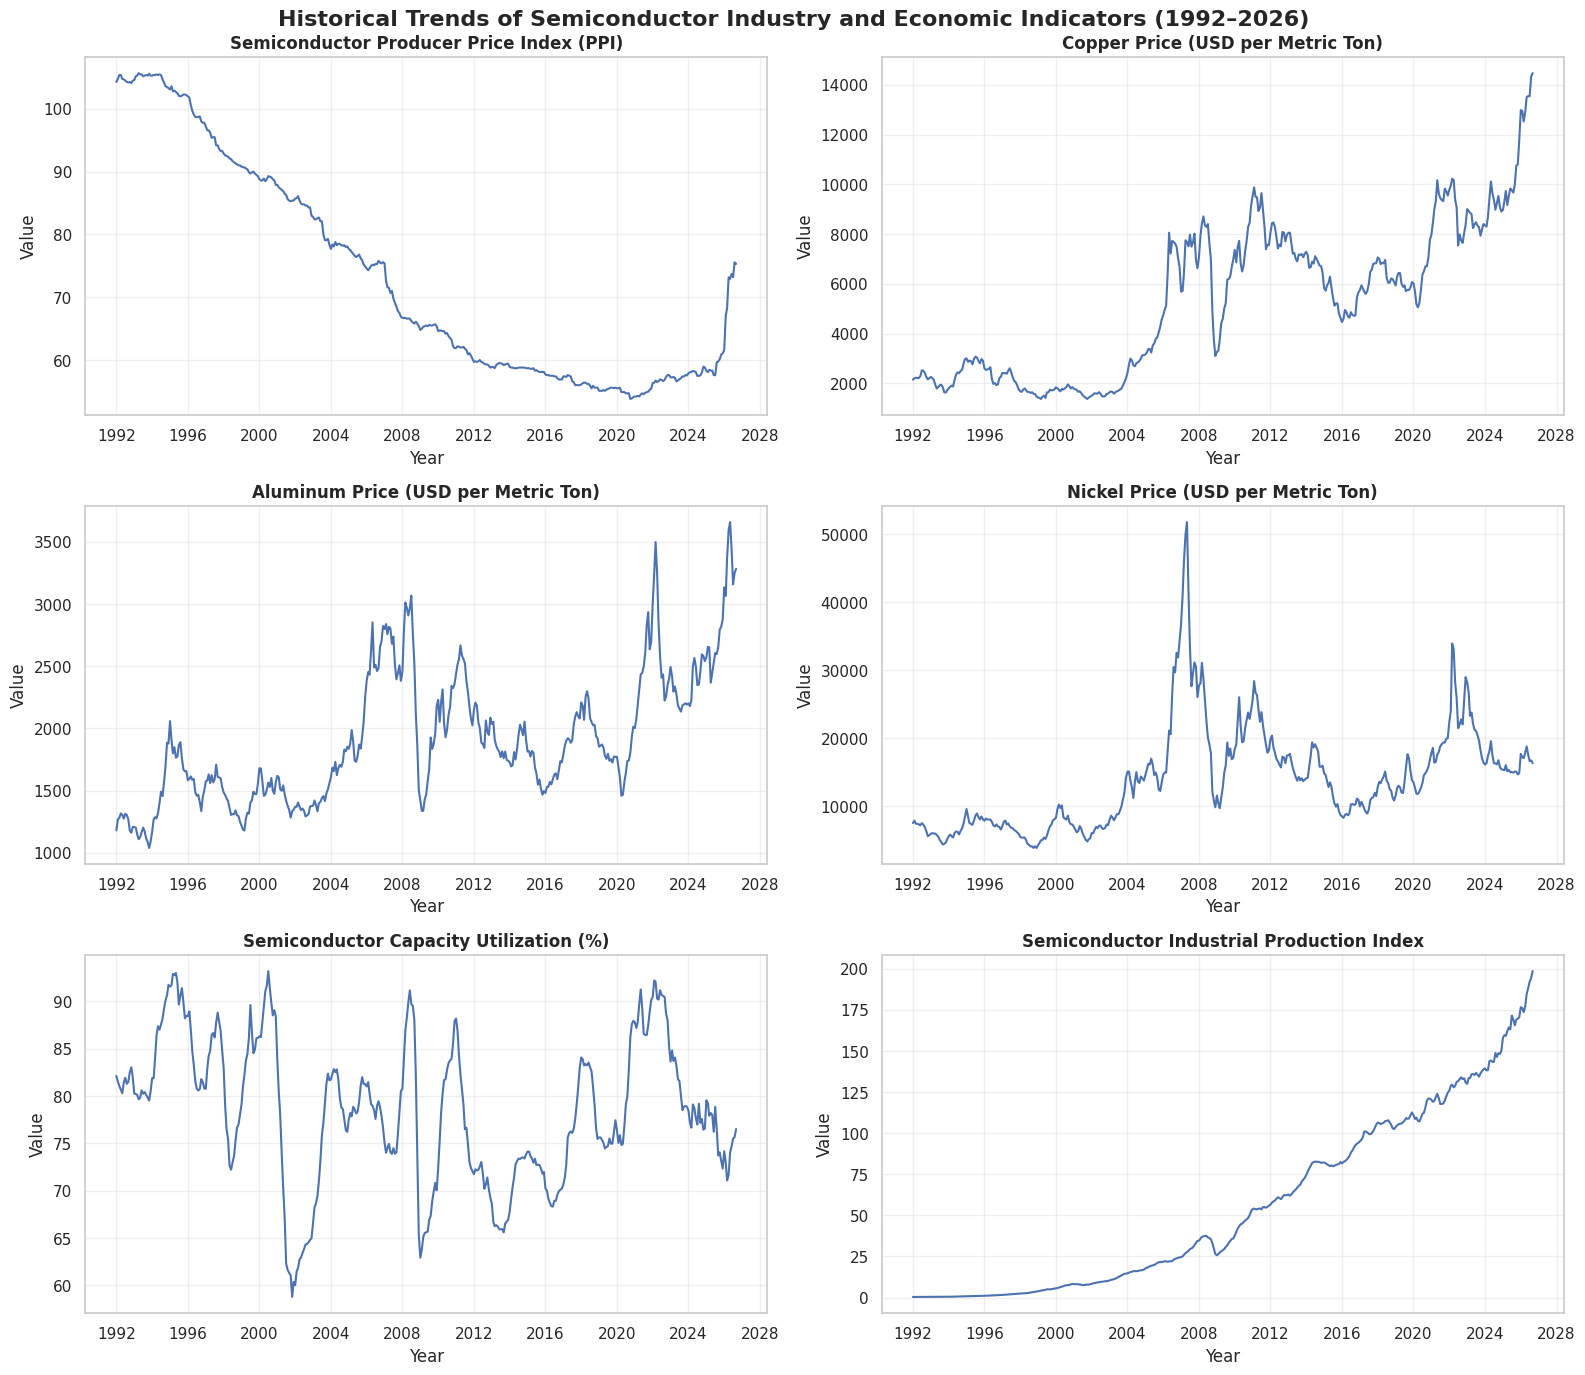

In [ ]:

# STEP 6.1: Historical Trend Visualization

indicators = {
    "PCU3344133441": "Semiconductor Producer Price Index (PPI)",
    "PCOPPUSDM": "Copper Price (USD per Metric Ton)",
    "PALUMUSDM": "Aluminum Price (USD per Metric Ton)",
    "PNICKUSDM": "Nickel Price (USD per Metric Ton)",
    "CAPUTLG3344S": "Semiconductor Capacity Utilization (%)",
    "IPG3344S": "Semiconductor Industrial Production Index"
}

fig, axes = plt.subplots(3, 2, figsize=(16, 14))

for ax, (column, title) in zip(axes.flatten(), indicators.items()):
    ax.plot(
        df[date_col],
        df[column],
        linewidth=1.5
    )

    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.set_xlabel("Year")
    ax.set_ylabel("Value")
    ax.grid(True, alpha=0.3)

plt.suptitle(
    "Historical Trends of Semiconductor Industry and Economic Indicators (1992–2026)",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


**Individual PPI trend**

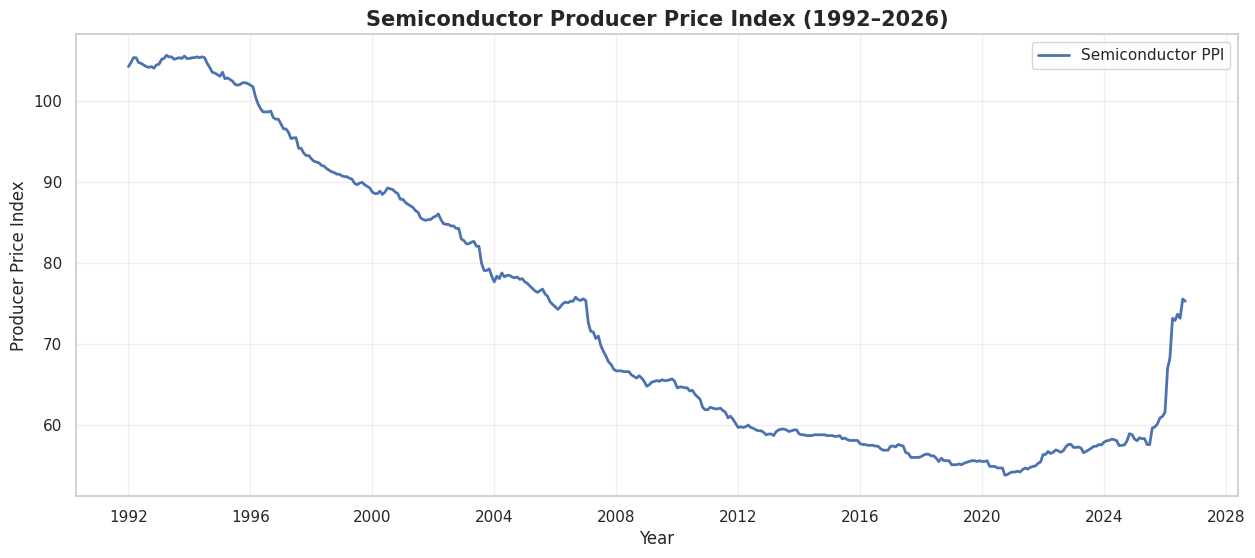

In [ ]:

# STEP 6.2: Semiconductor PPI Trend

plt.figure(figsize=(15, 6))

plt.plot(
    df[date_col],
    df["PCU3344133441"],
    linewidth=2,
    label="Semiconductor PPI"
)

plt.title(
    "Semiconductor Producer Price Index (1992–2026)",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Year")
plt.ylabel("Producer Price Index")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


Semiconductor inflation trend

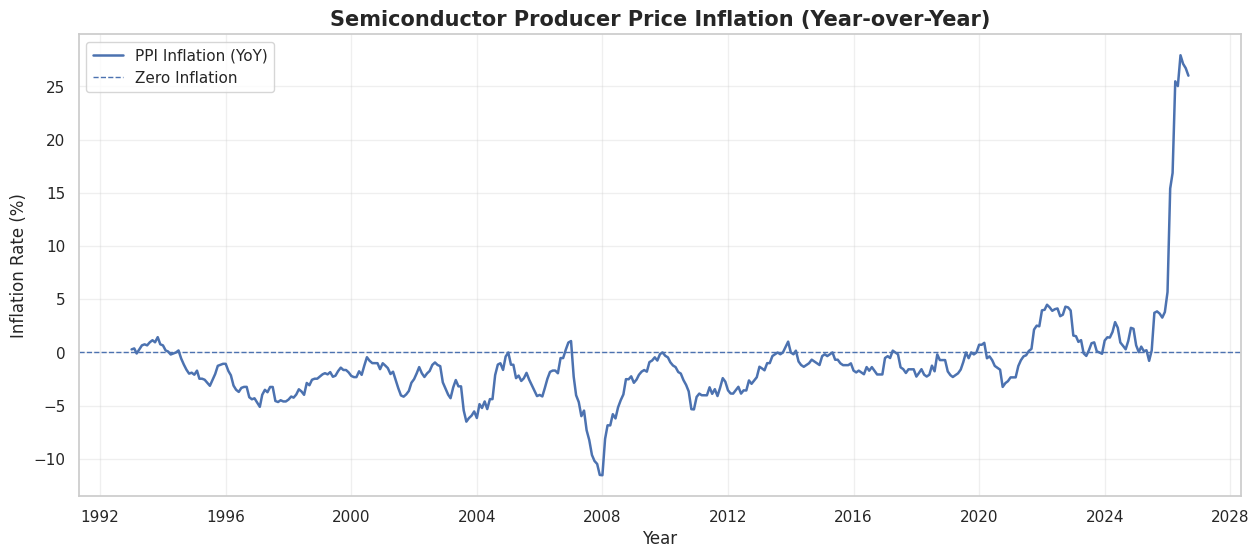

In [ ]:

# STEP 6.3: Semiconductor PPI Inflation Trend

plt.figure(figsize=(15, 6))

plt.plot(
    df[date_col],
    df["PPI_Inflation_YoY_pct"],
    linewidth=1.8,
    label="PPI Inflation (YoY)"
)

plt.axhline(
    y=0,
    linestyle="--",
    linewidth=1,
    label="Zero Inflation"
)

plt.title(
    "Semiconductor Producer Price Inflation (Year-over-Year)",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Year")
plt.ylabel("Inflation Rate (%)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


**Distribution analysis**

Histogram analysis

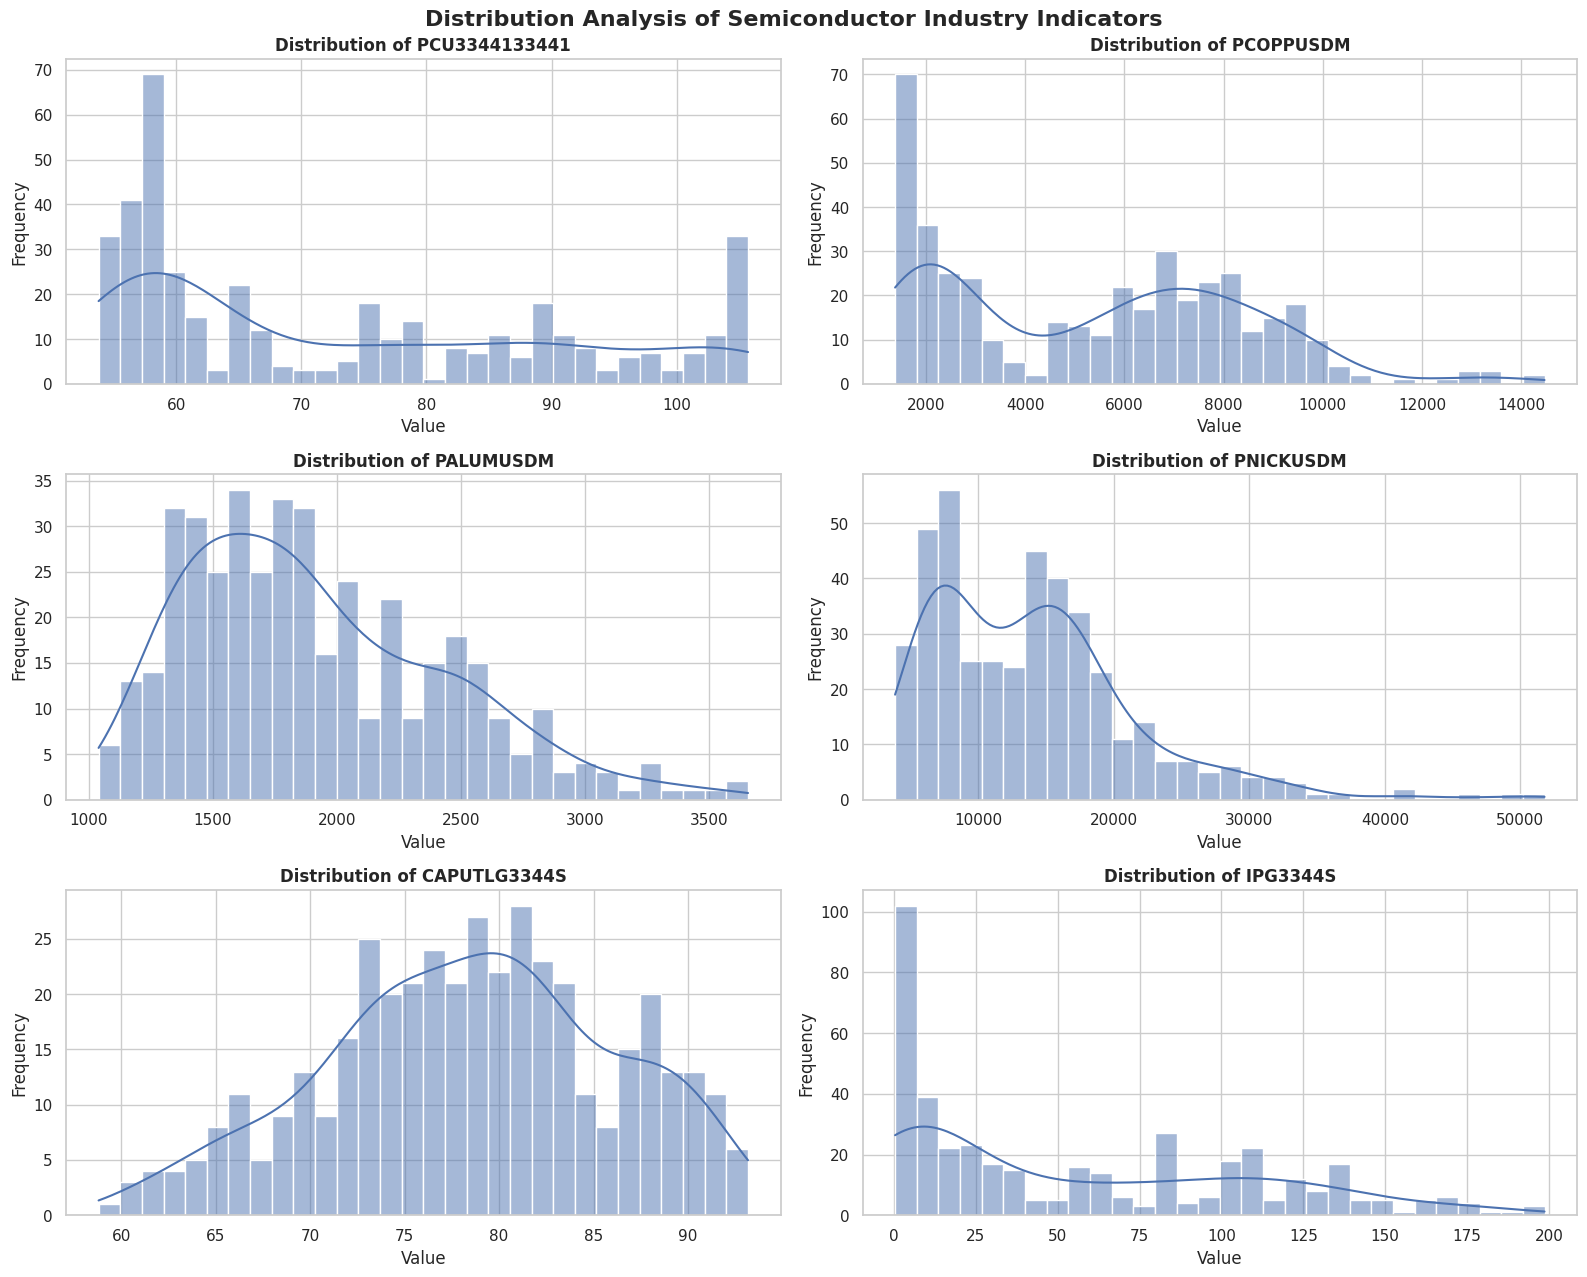

In [ ]:

# STEP 7.1: Distribution Analysis using Histograms

fig, axes = plt.subplots(3, 2, figsize=(16, 13))

for ax, column in zip(axes.flatten(), indicator_columns):

    sns.histplot(
        data=df,
        x=column,
        kde=True,
        bins=30,
        ax=ax
    )

    ax.set_title(f"Distribution of {column}", fontweight="bold")
    ax.set_xlabel("Value")
    ax.set_ylabel("Frequency")

plt.suptitle(
    "Distribution Analysis of Semiconductor Industry Indicators",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


Boxplot analysis

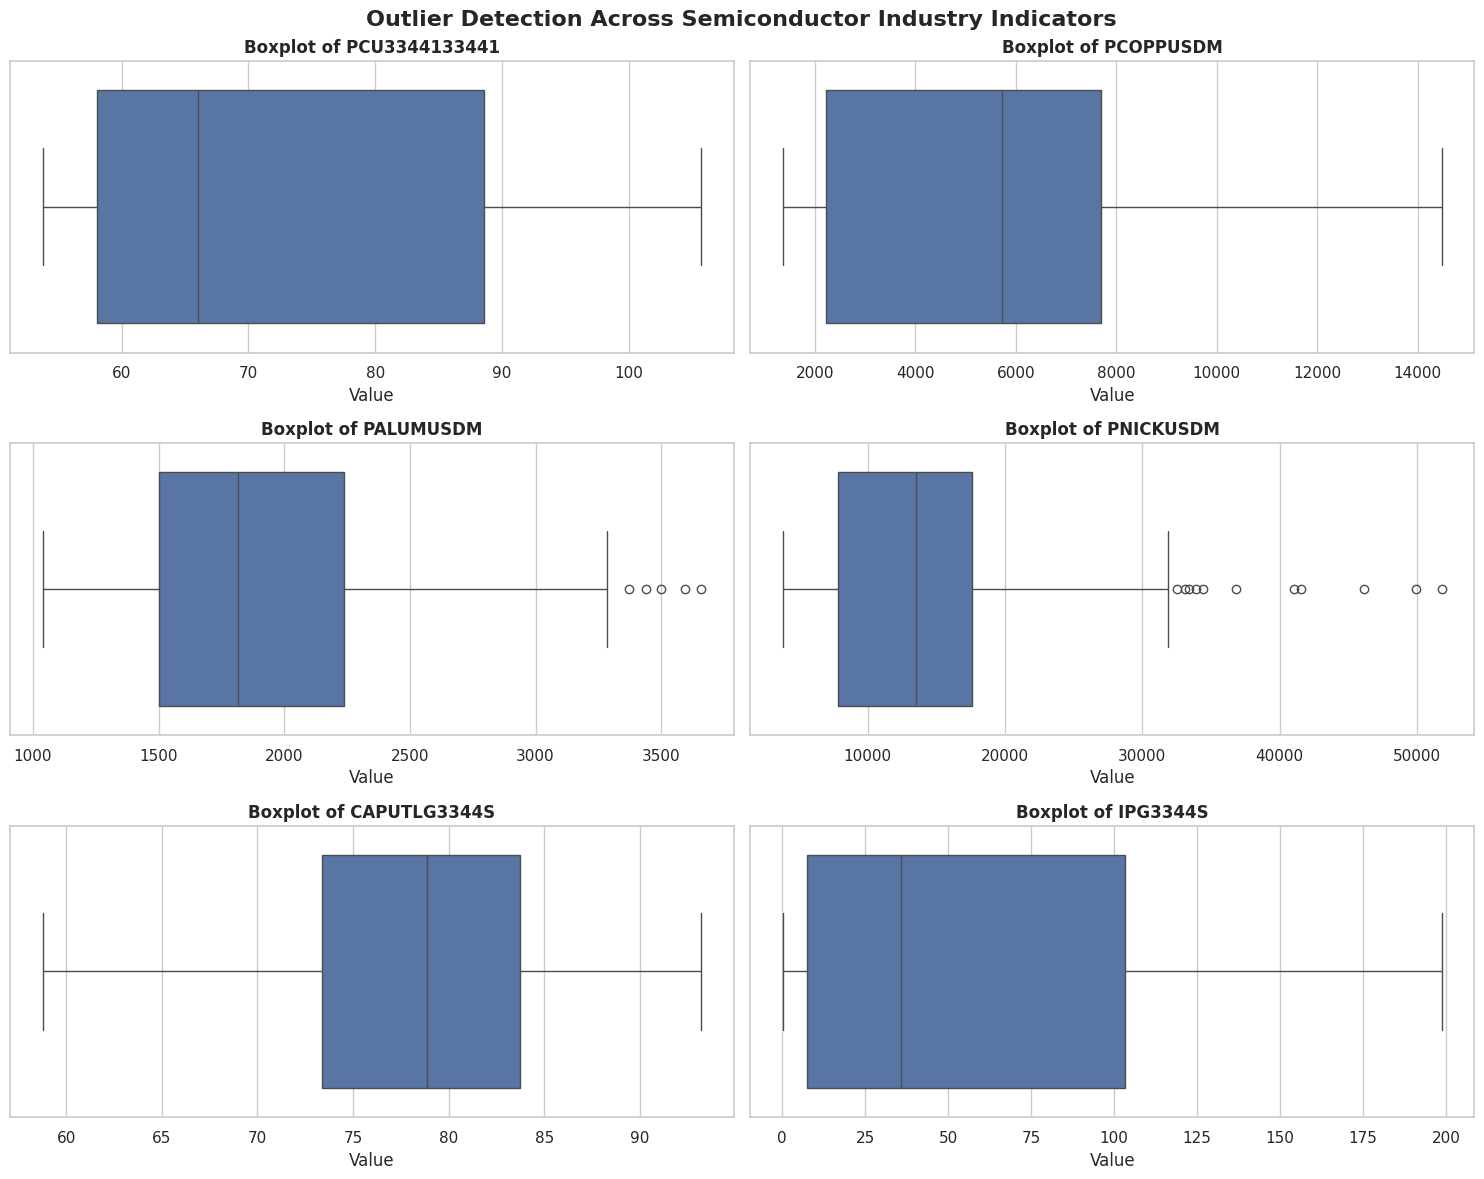

In [ ]:

# STEP 7.2: Outlier Detection using Boxplots

fig, axes = plt.subplots(3, 2, figsize=(15, 12))

for ax, column in zip(axes.flatten(), indicator_columns):

    sns.boxplot(
        x=df[column],
        ax=ax
    )

    ax.set_title(f"Boxplot of {column}", fontweight="bold")
    ax.set_xlabel("Value")

plt.suptitle(
    "Outlier Detection Across Semiconductor Industry Indicators",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


Skewness and kurtosis

In [ ]:

# STEP 7.3: Statistical Distribution Measures

distribution_stats = pd.DataFrame({
    "Mean": df[indicator_columns].mean(),
    "Median": df[indicator_columns].median(),
    "Skewness": df[indicator_columns].skew(),
    "Kurtosis": df[indicator_columns].kurt()
})

display(distribution_stats.round(3))


,Mean,Median,Skewness,Kurtosis
PCU3344133441,73.301,66.000,0.592,-1.109
PCOPPUSDM,5354.407,5719.761,0.351,-0.724
PALUMUSDM,1913.638,1814.719,0.769,0.124
PNICKUSDM,13994.796,13506.864,1.402,3.197
CAPUTLG3344S,78.422,78.857,-0.189,-0.534
IPG3344S,55.824,35.867,0.673,-0.769


**Correlation analysis**

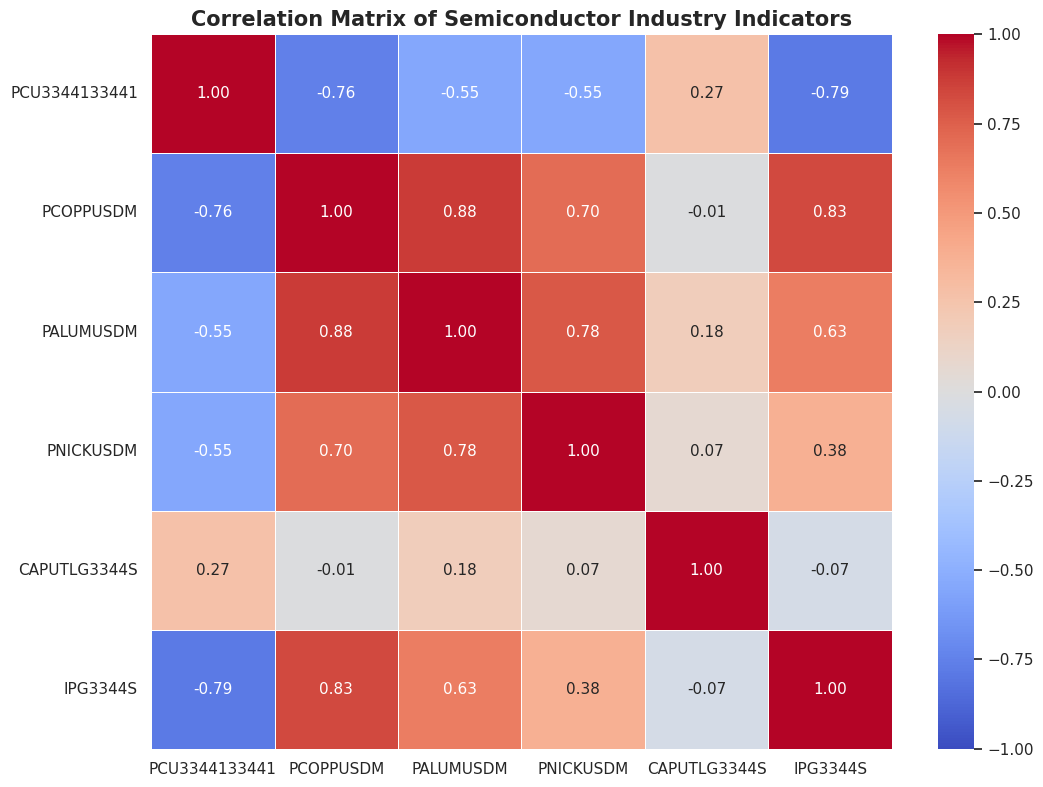

In [ ]:

# STEP 8.1: Correlation Analysis

correlation_matrix = df[indicator_columns].corr(method="pearson")

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1,
    center=0
)

plt.title(
    "Correlation Matrix of Semiconductor Industry Indicators",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


**Correlation with semiconductor PPI inflation**

Correlation with Semiconductor PPI Inflation:


,Correlation with PPI Inflation
IPG3344S,0.561
PCOPPUSDM,0.461
PALUMUSDM,0.395
PNICKUSDM,0.036
CAPUTLG3344S,-0.043
PCU3344133441,-0.123


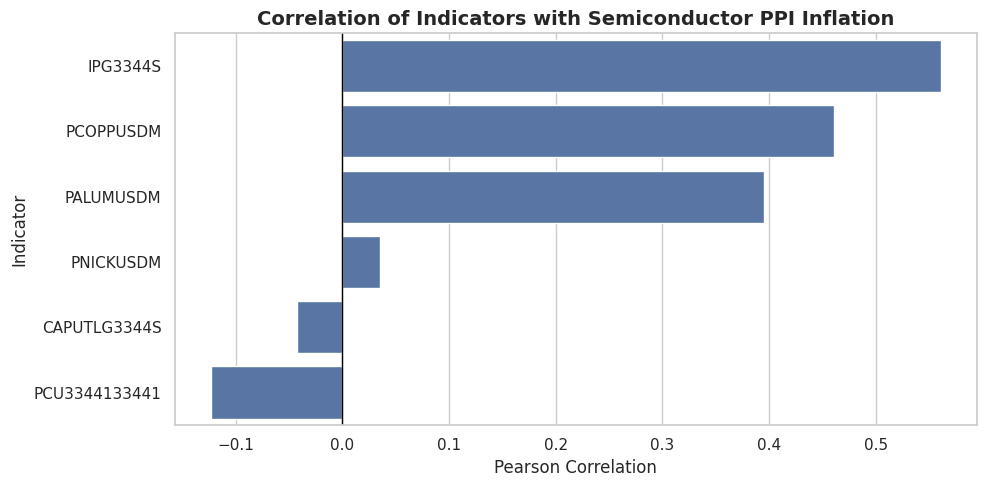

In [ ]:

# STEP 8.2: Correlation with PPI Inflation

target_column = "PPI_Inflation_YoY_pct"

correlation_with_target = (
    df[indicator_columns]
    .corrwith(df[target_column])
    .sort_values(ascending=False)
)

print("Correlation with Semiconductor PPI Inflation:")

display(
    correlation_with_target.to_frame(
        name="Correlation with PPI Inflation"
    ).round(3)
)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=correlation_with_target.values,
    y=correlation_with_target.index
)

plt.title(
    "Correlation of Indicators with Semiconductor PPI Inflation",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Pearson Correlation")
plt.ylabel("Indicator")
plt.axvline(x=0, color="black", linewidth=1)
plt.tight_layout()
plt.show()


**Spearman correlation**

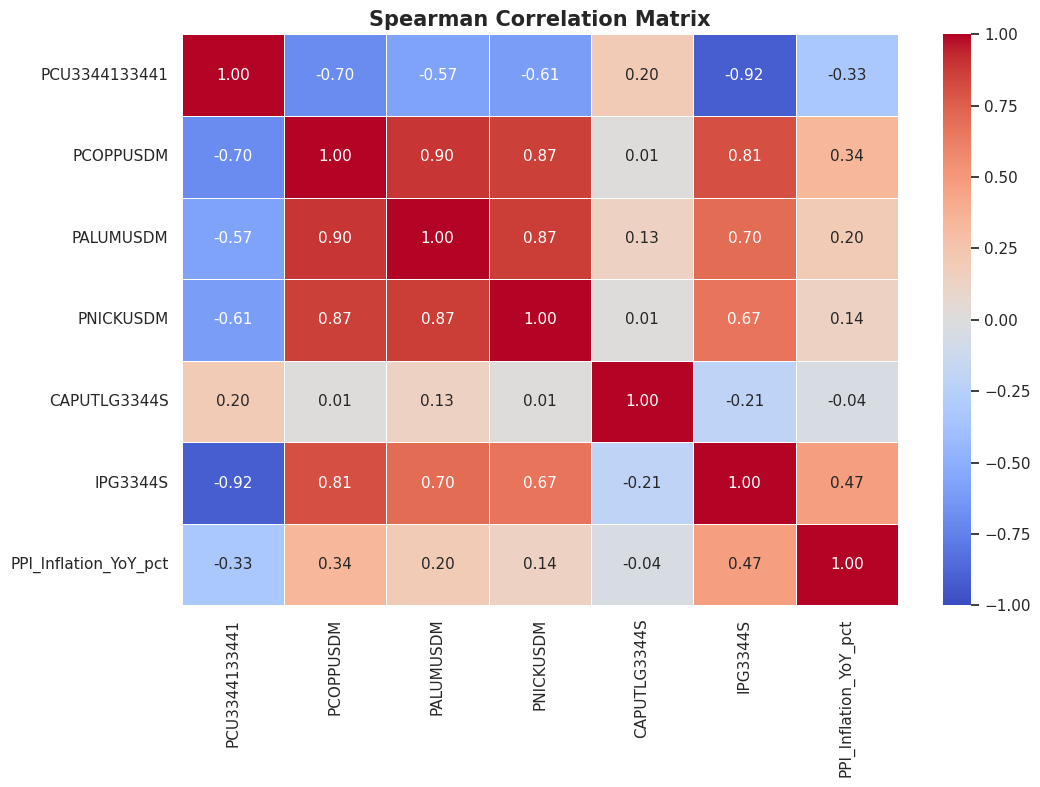

In [ ]:

# STEP 8.3: Spearman Correlation

spearman_matrix = df[
    indicator_columns + [target_column]
].corr(method="spearman")

plt.figure(figsize=(11, 8))

sns.heatmap(
    spearman_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    center=0,
    vmin=-1,
    vmax=1
)

plt.title(
    "Spearman Correlation Matrix",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


**Stationarity analysis**

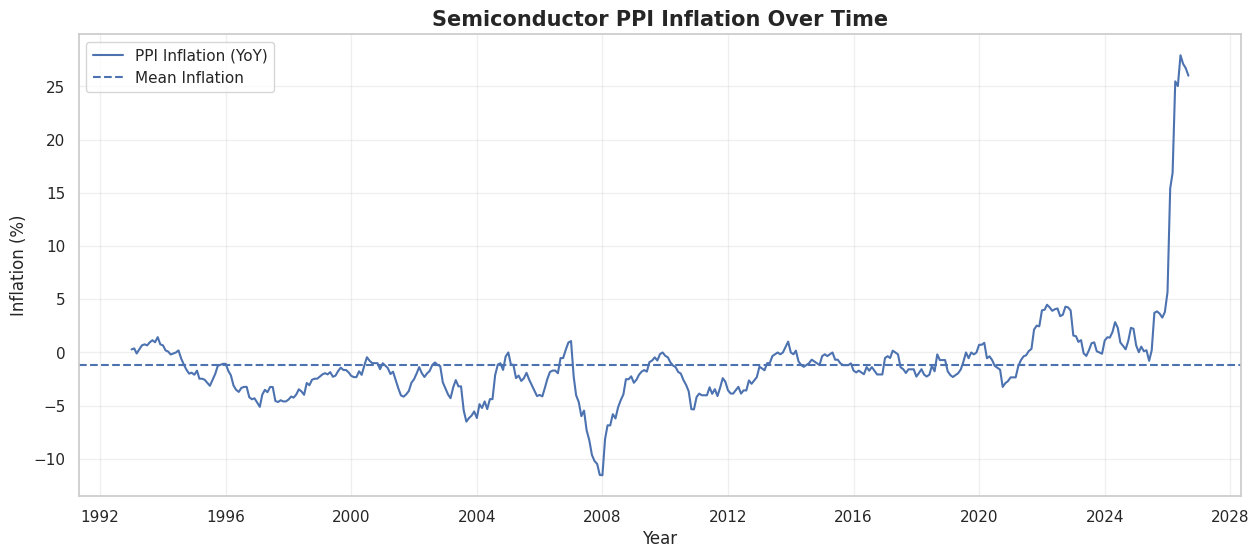

In [ ]:

# STEP 9.1: Target Inflation Analysis

plt.figure(figsize=(15, 6))

plt.plot(
    df[date_col],
    df["PPI_Inflation_YoY_pct"],
    label="PPI Inflation (YoY)",
    linewidth=1.5
)

plt.axhline(
    y=df["PPI_Inflation_YoY_pct"].mean(),
    linestyle="--",
    label="Mean Inflation"
)

plt.title(
    "Semiconductor PPI Inflation Over Time",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Year")
plt.ylabel("Inflation (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


**ADF test on all six indicators**

In [ ]:

# STEP 9.3: Stationarity Test for All Indicators

from statsmodels.tsa.stattools import adfuller

stationarity_results = []

for column in indicator_columns:

    series = df[column].dropna()

    result = adfuller(series, autolag="AIC")

    stationarity_results.append({
        "Indicator": column,
        "ADF Statistic": result[0],
        "p-value": result[1],
        "Stationary at 5%": "Yes" if result[1] < 0.05 else "No"
    })

stationarity_df = pd.DataFrame(stationarity_results)

display(stationarity_df.round(4))


,Indicator,ADF Statistic,p-value,Stationary at 5%
0,PCU3344133441,-1.8074,0.3768,No
1,PCOPPUSDM,-0.1189,0.9475,No
2,PALUMUSDM,-2.1625,0.2201,No
3,PNICKUSDM,-2.5256,0.1094,No
4,CAPUTLG3344S,-4.0630,0.0011,Yes
5,IPG3344S,3.0132,1.0000,No


PPI inflation jumps from roughly 4% to approximately 28% in 2026. This is unusually large compared with its earlier history.

We should verify the underlying PPI observations and series definition before deciding whether this is a genuine economic change or a data issue. It can strongly influence the ADF test and model performance.

**Verify the 2026 PPI increase**

,observation_date,PCU3344133441,PPI_Inflation_YoY_pct,PPI_Monthly_Change_pct
384,2024-01-01,57.884,1.122,NaN
385,2024-02-01,58.055,1.427,0.295
386,2024-03-01,58.105,1.401,0.086
387,2024-04-01,58.256,1.932,0.260
388,2024-05-01,58.205,2.854,-0.088
389,2024-06-01,58.062,2.325,-0.246
390,2024-07-01,57.463,0.938,-1.032
391,2024-08-01,57.494,0.628,0.054
392,2024-09-01,57.543,0.298,0.085
393,2024-10-01,58.003,1.079,0.799


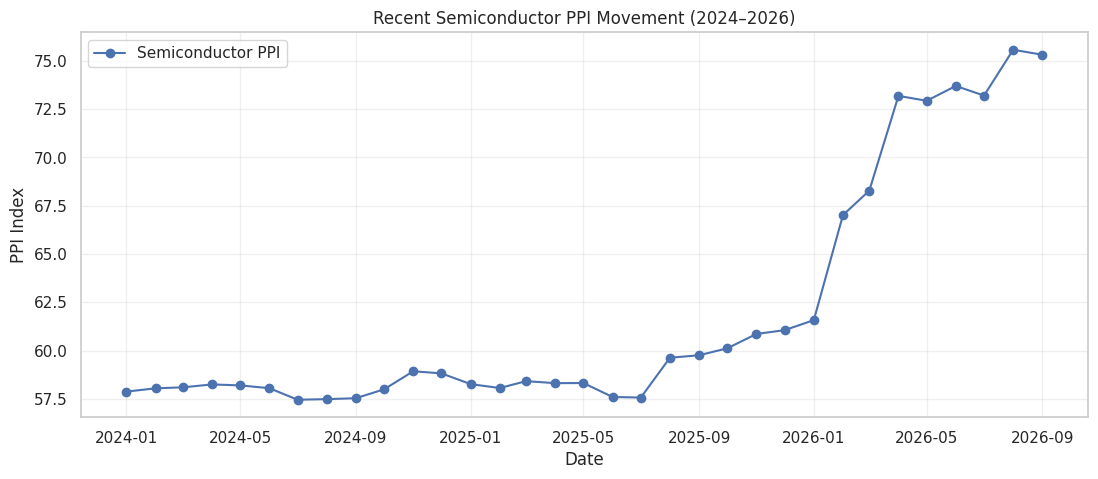

In [ ]:

# STEP 9.1: Investigate the unusual 2026 PPI increase

check_columns = [
    date_col,
    "PCU3344133441",
    "PPI_Inflation_YoY_pct"
]

recent_ppi = df.loc[
    df[date_col] >= "2024-01-01",
    check_columns
].copy()

recent_ppi["PPI_Monthly_Change_pct"] = (
    recent_ppi["PCU3344133441"].pct_change() * 100
)

display(recent_ppi.round(3))

# Plot the recent PPI values
plt.figure(figsize=(13, 5))

plt.plot(
    recent_ppi[date_col],
    recent_ppi["PCU3344133441"],
    marker="o",
    label="Semiconductor PPI"
)

plt.title("Recent Semiconductor PPI Movement (2024–2026)")
plt.xlabel("Date")
plt.ylabel("PPI Index")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


**Test stationarity of the actual inflation target**

In [ ]:

# STEP 9.2: ADF Test on PPI Inflation

from statsmodels.tsa.stattools import adfuller

inflation_series = (
    df["PPI_Inflation_YoY_pct"]
    .dropna()
)

result = adfuller(inflation_series, autolag="AIC")

print("ADF TEST: SEMICONDUCTOR PPI INFLATION")
print("-" * 50)
print("ADF Statistic:", round(result[0], 4))
print("p-value:", round(result[1], 4))
print("Lags Used:", result[2])
print("Observations:", result[3])

print("\nCritical Values:")
for key, value in result[4].items():
    print(key, round(value, 4))

if result[1] < 0.05:
    print("\nConclusion: Evidence of stationarity.")
else:
    print("\nConclusion: Insufficient evidence of stationarity.")


ADF TEST: SEMICONDUCTOR PPI INFLATION
--------------------------------------------------
ADF Statistic: 0.5457
p-value: 0.9862
Lags Used: 14
Observations: 390

Critical Values:
1% -3.4472
5% -2.869
10% -2.5707

Conclusion: Insufficient evidence of stationarity.


we should investigate whether February 2026 represents a genuine change in the series or a methodological/data revision.

This matters because blindly differencing a series with a structural break can produce misleading results.

**Investigate the structural change**

In [ ]:

# STEP 10: Structural Change Investigation

ppi_check = df[[date_col, "PCU3344133441"]].copy()

# Calculate monthly percentage change
ppi_check["Monthly_Change_pct"] = (
    ppi_check["PCU3344133441"].pct_change() * 100
)

# Calculate year-over-year percentage change
ppi_check["YoY_Change_pct"] = (
    ppi_check["PCU3344133441"].pct_change(12) * 100
)

# Display observations from 2025 and 2026
recent_data = ppi_check[
    ppi_check[date_col] >= "2025-01-01"
]

display(recent_data.round(3))

# Identify unusually large monthly changes
print("\nLargest absolute monthly changes:")

display(
    ppi_check.assign(
        Absolute_Change=lambda x: x["Monthly_Change_pct"].abs()
    )
    .nlargest(10, "Absolute_Change")
    [[date_col, "PCU3344133441", "Monthly_Change_pct"]]
    .round(3)
)


,observation_date,PCU3344133441,Monthly_Change_pct,YoY_Change_pct
396,2025-01-01,58.272,-0.945,0.670
397,2025-02-01,58.070,-0.347,0.026
398,2025-03-01,58.425,0.611,0.551
399,2025-04-01,58.322,-0.176,0.113
400,2025-05-01,58.328,0.010,0.211
401,2025-06-01,57.606,-1.238,-0.785
402,2025-07-01,57.576,-0.052,0.197
403,2025-08-01,59.637,3.580,3.727
404,2025-09-01,59.765,0.215,3.861
405,2025-10-01,60.125,0.602,3.658



Largest absolute monthly changes:


,observation_date,PCU3344133441,Monthly_Change_pct
409,2026-02-01,67.019,8.827
411,2026-04-01,73.184,7.179
181,2007-02-01,72.600,-3.714
403,2025-08-01,59.637,3.580
415,2026-08-01,75.571,3.240
139,2003-08-01,80.000,-2.558
410,2026-03-01,68.282,1.885
186,2007-07-01,69.800,-1.690
360,2022-01-01,56.346,1.653
345,2020-10-01,53.800,-1.645


**First-order differencing**

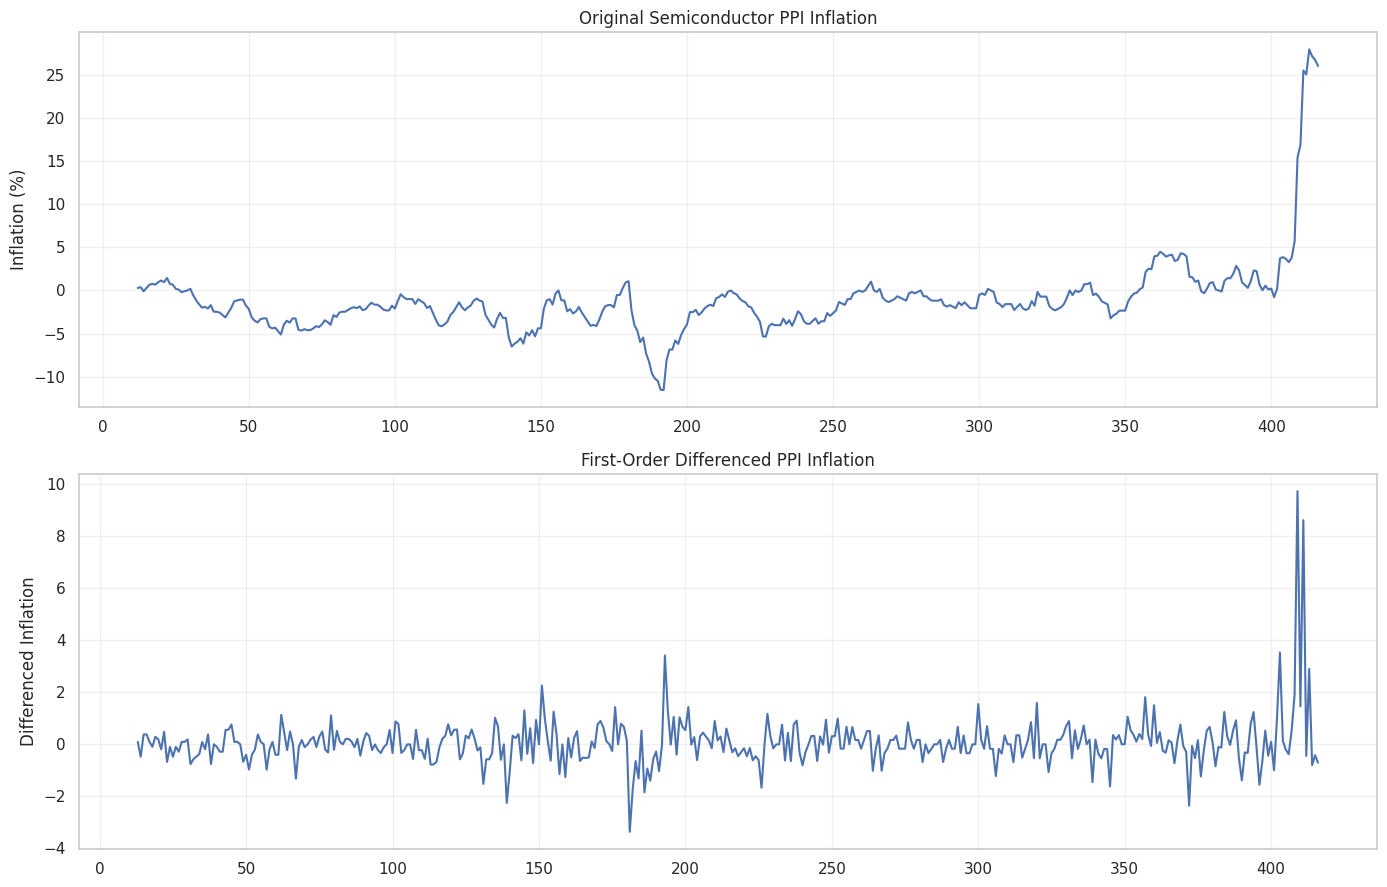

ADF TEST AFTER FIRST DIFFERENCING
---------------------------------------------
ADF Statistic: -5.4678
p-value: 0.0
Conclusion: Evidence of stationarity after differencing.


In [ ]:

# STEP 11: First-Order Differencing of PPI Inflation

from statsmodels.tsa.stattools import adfuller

inflation = df["PPI_Inflation_YoY_pct"].dropna()

# First-order differencing
inflation_diff = inflation.diff().dropna()

# Plot original and differenced inflation
fig, axes = plt.subplots(2, 1, figsize=(14, 9))

axes[0].plot(inflation)
axes[0].set_title("Original Semiconductor PPI Inflation")
axes[0].set_ylabel("Inflation (%)")
axes[0].grid(alpha=0.3)

axes[1].plot(inflation_diff)
axes[1].set_title("First-Order Differenced PPI Inflation")
axes[1].set_ylabel("Differenced Inflation")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# ADF test after differencing
result_diff = adfuller(inflation_diff, autolag="AIC")

print("ADF TEST AFTER FIRST DIFFERENCING")
print("-" * 45)
print("ADF Statistic:", round(result_diff[0], 4))
print("p-value:", round(result_diff[1], 4))

if result_diff[1] < 0.05:
    print("Conclusion: Evidence of stationarity after differencing.")
else:
    print("Conclusion: Still insufficient evidence of stationarity.")


**Feature Engineering**

In [ ]:
# Step 12: Feature Engineering

# Work on a separate copy
feature_df = df.copy()

# Sort chronologically
feature_df = feature_df.sort_values("observation_date").reset_index(drop=True)

# 1. Monthly percentage changes
monthly_change_cols = [
    "PCOPPUSDM",
    "PALUMUSDM",
    "PNICKUSDM",
    "IPG3344S"
]

for col in monthly_change_cols:
    feature_df[f"{col}_MoM_pct"] = feature_df[col].pct_change() * 100

# 2. Year-over-year percentage changes
yoy_cols = [
    "PCOPPUSDM",
    "PALUMUSDM",
    "PNICKUSDM",
    "IPG3344S"
]

for col in yoy_cols:
    feature_df[f"{col}_YoY_pct"] = feature_df[col].pct_change(12) * 100

# Capacity utilization: change in percentage points
feature_df["Capacity_Change"] = (
    feature_df["CAPUTLG3344S"].diff()
)

# 3. Lagged features for the target and predictors
lag_cols = [
    "PPI_Inflation_YoY_pct",
    "PCOPPUSDM_MoM_pct",
    "PALUMUSDM_MoM_pct",
    "PNICKUSDM_MoM_pct",
    "IPG3344S_MoM_pct",
    "Capacity_Change"
]

for col in lag_cols:
    for lag in [1, 2, 3, 6]:
        feature_df[f"{col}_Lag_{lag}"] = feature_df[col].shift(lag)

# Inspect the engineered dataset
print("Dataset shape:", feature_df.shape)
print("\nNew feature columns:")
print([col for col in feature_df.columns if "_MoM_pct" in col
       or "_YoY_pct" in col or "_Lag_" in col
       or col == "Capacity_Change"])

display(feature_df.tail())

Dataset shape: (417, 42)

New feature columns:
['PPI_Inflation_YoY_pct', 'PCOPPUSDM_MoM_pct', 'PALUMUSDM_MoM_pct', 'PNICKUSDM_MoM_pct', 'IPG3344S_MoM_pct', 'PCOPPUSDM_YoY_pct', 'PALUMUSDM_YoY_pct', 'PNICKUSDM_YoY_pct', 'IPG3344S_YoY_pct', 'Capacity_Change', 'PPI_Inflation_YoY_pct_Lag_1', 'PPI_Inflation_YoY_pct_Lag_2', 'PPI_Inflation_YoY_pct_Lag_3', 'PPI_Inflation_YoY_pct_Lag_6', 'PCOPPUSDM_MoM_pct_Lag_1', 'PCOPPUSDM_MoM_pct_Lag_2', 'PCOPPUSDM_MoM_pct_Lag_3', 'PCOPPUSDM_MoM_pct_Lag_6', 'PALUMUSDM_MoM_pct_Lag_1', 'PALUMUSDM_MoM_pct_Lag_2', 'PALUMUSDM_MoM_pct_Lag_3', 'PALUMUSDM_MoM_pct_Lag_6', 'PNICKUSDM_MoM_pct_Lag_1', 'PNICKUSDM_MoM_pct_Lag_2', 'PNICKUSDM_MoM_pct_Lag_3', 'PNICKUSDM_MoM_pct_Lag_6', 'IPG3344S_MoM_pct_Lag_1', 'IPG3344S_MoM_pct_Lag_2', 'IPG3344S_MoM_pct_Lag_3', 'IPG3344S_MoM_pct_Lag_6', 'Capacity_Change_Lag_1', 'Capacity_Change_Lag_2', 'Capacity_Change_Lag_3', 'Capacity_Change_Lag_6']


,observation_date,PCU3344133441,PCOPPUSDM,PALUMUSDM,PNICKUSDM,CAPUTLG3344S,IPG3344S,PPI_Inflation_YoY_pct,PPI_Inflation_YoY_6M_Ahead_pct,PCOPPUSDM_MoM_pct,...,PNICKUSDM_MoM_pct_Lag_3,PNICKUSDM_MoM_pct_Lag_6,IPG3344S_MoM_pct_Lag_1,IPG3344S_MoM_pct_Lag_2,IPG3344S_MoM_pct_Lag_3,IPG3344S_MoM_pct_Lag_6,Capacity_Change_Lag_1,Capacity_Change_Lag_2,Capacity_Change_Lag_3,Capacity_Change_Lag_6
412,2026-05-01,72.931,13512.156190,3658.221429,18792.748571,74.0213,184.6946,25.036003,NaN,4.821065,...,-3.036329,-2.791828,1.891554,-1.411735,-0.299926,0.370219,0.5722,-1.8825,-1.1857,-0.9080
413,2026-06-01,73.698,13552.040909,3438.847273,17588.285455,74.6883,188.2611,27.934590,NaN,0.295177,...,-0.563735,1.419568,4.359790,1.891554,-1.411735,0.470006,2.3529,0.5722,-1.8825,-0.8067
414,2026-07-01,73.199,13542.820870,3158.265000,16632.361364,75.5013,192.2137,27.134570,NaN,-0.068034,...,4.618237,19.032381,1.931026,4.359790,1.891554,3.618033,0.6670,2.3529,0.5722,1.8267
415,2026-08-01,75.571,14331.264762,3250.121429,16748.181905,75.6619,194.5212,26.718312,NaN,5.821859,...,5.193600,-3.036329,2.099531,1.931026,4.359790,-0.299926,0.8130,0.6670,2.3529,-1.1857
416,2026-09-01,75.313,14473.055909,3283.054286,16323.821905,76.5104,198.6335,26.015226,NaN,0.989383,...,-6.409191,-0.563735,1.200487,2.099531,1.931026,-1.411735,0.1606,0.8130,0.6670,-1.8825


**Validation**

output shows that PPI_Inflation_YoY_6M_Ahead_pct is NaN for May–September 2026. That's expected because future observations are unavailable.

In [ ]:
# Step 12.1: Validate engineered features

print("Dataset shape:", feature_df.shape)

# Count missing values in each column
missing = feature_df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

print("\nColumns with missing values:")
print(missing)

# Check duplicate dates
print("\nDuplicate dates:",
      feature_df["observation_date"].duplicated().sum())

# Check infinite values
numeric_df = feature_df.select_dtypes(include=np.number)

print("\nInfinite values:",
      np.isinf(numeric_df).sum().sum())

# Check target availability
print("\nTarget availability:")
print("Available targets:",
      feature_df["PPI_Inflation_YoY_6M_Ahead_pct"].notna().sum())

print("Missing targets:",
      feature_df["PPI_Inflation_YoY_6M_Ahead_pct"].isna().sum())

Dataset shape: (417, 42)

Columns with missing values:
PPI_Inflation_YoY_pct_Lag_6       18
PPI_Inflation_YoY_pct_Lag_3       15
PPI_Inflation_YoY_pct_Lag_2       14
PPI_Inflation_YoY_pct_Lag_1       13
PCOPPUSDM_YoY_pct                 12
PPI_Inflation_YoY_pct             12
PPI_Inflation_YoY_6M_Ahead_pct    12
PNICKUSDM_YoY_pct                 12
IPG3344S_YoY_pct                  12
PALUMUSDM_YoY_pct                 12
PCOPPUSDM_MoM_pct_Lag_6            7
IPG3344S_MoM_pct_Lag_6             7
Capacity_Change_Lag_6              7
PNICKUSDM_MoM_pct_Lag_6            7
PALUMUSDM_MoM_pct_Lag_6            7
PNICKUSDM_MoM_pct_Lag_3            4
PCOPPUSDM_MoM_pct_Lag_3            4
Capacity_Change_Lag_3              4
IPG3344S_MoM_pct_Lag_3             4
PALUMUSDM_MoM_pct_Lag_3            4
PALUMUSDM_MoM_pct_Lag_2            3
Capacity_Change_Lag_2              3
IPG3344S_MoM_pct_Lag_2             3
PNICKUSDM_MoM_pct_Lag_2            3
PCOPPUSDM_MoM_pct_Lag_2            3
PNICKUSDM_MoM_pct_La

**Prepare the model-ready dataset**

In [ ]:
# Step 13: Prepare model-ready dataset

target = "PPI_Inflation_YoY_6M_Ahead_pct"

# Exclude date and future target from predictors
feature_cols = [
    col for col in feature_df.columns
    if col not in ["observation_date", target]
]

# Keep only rows with complete predictors and target
model_df = feature_df.dropna(
    subset=feature_cols + [target]
).copy()

# Separate predictors and target
X = model_df[feature_cols]
y = model_df[target]

print("Model-ready dataset shape:", model_df.shape)
print("Number of features:", X.shape[1])
print("Number of samples:", len(y))

print("\nRemaining missing values:", model_df.isnull().sum().sum())

print("\nDate range:")
print(model_df["observation_date"].min(), "to",
      model_df["observation_date"].max())

display(model_df.head())

Model-ready dataset shape: (393, 42)
Number of features: 40
Number of samples: 393

Remaining missing values: 0

Date range:
1993-07-01 00:00:00 to 2026-03-01 00:00:00


,observation_date,PCU3344133441,PCOPPUSDM,PALUMUSDM,PNICKUSDM,CAPUTLG3344S,IPG3344S,PPI_Inflation_YoY_pct,PPI_Inflation_YoY_6M_Ahead_pct,PCOPPUSDM_MoM_pct,...,PNICKUSDM_MoM_pct_Lag_3,PNICKUSDM_MoM_pct_Lag_6,IPG3344S_MoM_pct_Lag_1,IPG3344S_MoM_pct_Lag_2,IPG3344S_MoM_pct_Lag_3,IPG3344S_MoM_pct_Lag_6,Capacity_Change_Lag_1,Capacity_Change_Lag_2,Capacity_Change_Lag_3,Capacity_Change_Lag_6
18,1993-07-01,105.2,1927.339820,1203.181763,5051.181641,80.2468,0.4545,0.669856,0.669216,3.739179,...,0.210663,3.423807,1.869369,1.115919,0.365714,-0.924214,0.7662,0.1679,-0.4737,-1.7576
19,1993-08-01,105.3,1951.071375,1172.761963,4740.476074,80.4144,0.4599,0.958773,0.190114,1.231311,...,-3.502471,1.725759,0.486403,1.869369,1.115919,1.072761,-0.3469,0.7662,0.1679,-0.0563
20,1993-09-01,105.4,1858.249998,1116.909058,4376.045410,80.1323,0.4631,1.151631,0.094967,-4.757457,...,-4.040839,-1.253347,1.188119,0.486403,1.869369,0.946008,0.1676,-0.3469,0.7662,-0.0655
21,1993-10-01,105.3,1646.999929,1089.428589,4464.856934,79.8439,0.4668,0.958773,-0.189215,-11.368226,...,-8.894452,0.210663,0.695803,1.188119,0.486403,0.365714,-0.2821,0.1676,-0.3469,-0.4737
22,1993-11-01,105.6,1632.568105,1040.022705,4642.272949,79.5353,0.4708,1.440922,-0.094787,-0.876249,...,-6.151146,-3.502471,0.798964,0.695803,1.188119,1.115919,-0.2884,-0.2821,0.1676,0.1679


**Chronological train-test split**

In [ ]:
# Step 12: Chronological train-test split

target = "PPI_Inflation_YoY_6M_Ahead_pct"

# Sort observations by date
model_df = model_df.sort_values(
    "observation_date"
).reset_index(drop=True)

# Define predictors and target
feature_cols = [
    col for col in model_df.columns
    if col not in ["observation_date", target]
]

X = model_df[feature_cols]
y = model_df[target]

# Determine chronological split
split_index = int(len(model_df) * 0.80)

# Six-month gap to prevent overlapping forecast horizons
gap = 6
train_end = split_index - gap

X_train = X.iloc[:train_end]
y_train = y.iloc[:train_end]

X_test = X.iloc[split_index:]
y_test = y.iloc[split_index:]

# Dates for verification
train_dates = model_df["observation_date"].iloc[:train_end]
test_dates = model_df["observation_date"].iloc[split_index:]

print("TRAINING DATA")
print("Samples:", len(X_train))
print("Start:", train_dates.min())
print("End:", train_dates.max())

print("\nTESTING DATA")
print("Samples:", len(X_test))
print("Start:", test_dates.min())
print("End:", test_dates.max())

print("\nGap between training and testing:", gap, "months")

print("\nFinal shapes:")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

TRAINING DATA
Samples: 308
Start: 1993-07-01 00:00:00
End: 2019-02-01 00:00:00

TESTING DATA
Samples: 79
Start: 2019-09-01 00:00:00
End: 2026-03-01 00:00:00

Gap between training and testing: 6 months

Final shapes:
X_train: (308, 40)
X_test: (79, 40)
y_train: (308,)
y_test: (79,)


we should leave a six-month gap between the training and testing periods. Otherwise, training labels near the split could overlap with the testing period.


**Build the baseline forecasting model**

In [ ]:
# Step 13: Baseline Model

from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
import numpy as np

# Create baseline model
baseline_model = DummyRegressor(strategy="mean")

# Train
baseline_model.fit(X_train, y_train)

# Predict
baseline_predictions = baseline_model.predict(X_test)

# Evaluate
baseline_mae = mean_absolute_error(y_test, baseline_predictions)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_predictions))
baseline_r2 = r2_score(y_test, baseline_predictions)

print("BASELINE MODEL RESULTS")
print("----------------------")
print("MAE:", round(baseline_mae, 4))
print("RMSE:", round(baseline_rmse, 4))
print("R2 Score:", round(baseline_r2, 4))

BASELINE MODEL RESULTS
----------------------
MAE: 5.9509
RMSE: 9.3683
R2 Score: -0.6625


**Train first machine-learning model: Random Forest**

Random Forest combines multiple decision trees. Each tree learns different patterns in the training data, and their predictions are averaged.

it can learn nonlinear relationships between:
- Copper, aluminum and nickel price movements.
- Semiconductor production and capacity utilization.
- Historical inflation and lagged indicators.

start with a restrained model to reduce overfitting, given that we have only 308 training observations.

In [ ]:
# Step 14: Random Forest Regressor

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
import numpy as np

# Initialize model
rf_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=5,
    min_samples_split=10,
    min_samples_leaf=5,
    max_features=0.7,
    random_state=42,
    n_jobs=-1
)

# Train model
rf_model.fit(X_train, y_train)

# Generate predictions
rf_predictions = rf_model.predict(X_test)

# Evaluate model
rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))
rf_r2 = r2_score(y_test, rf_predictions)

print("RANDOM FOREST RESULTS")
print("---------------------")
print("MAE:", round(rf_mae, 4))
print("RMSE:", round(rf_rmse, 4))
print("R2 Score:", round(rf_r2, 4))

# Compare against baseline
print("\nBASELINE vs RANDOM FOREST")
print("-------------------------")
print("Baseline MAE:", round(baseline_mae, 4))
print("Random Forest MAE:", round(rf_mae, 4))
print("Baseline RMSE:", round(baseline_rmse, 4))
print("Random Forest RMSE:", round(rf_rmse, 4))

RANDOM FOREST RESULTS
---------------------
MAE: 5.1523
RMSE: 8.8063
R2 Score: -0.4691

BASELINE vs RANDOM FOREST
-------------------------
Baseline MAE: 5.9509
Random Forest MAE: 5.1523
Baseline RMSE: 9.3683
Random Forest RMSE: 8.8063


Random Forest has improved over our baseline

Research interpretation: The nonlinear model captures some useful relationships, but its predictive performance is not yet strong enough. We should investigate the test-period errors and compare other models before making conclusions.

**Visualize actual vs predicted inflation**

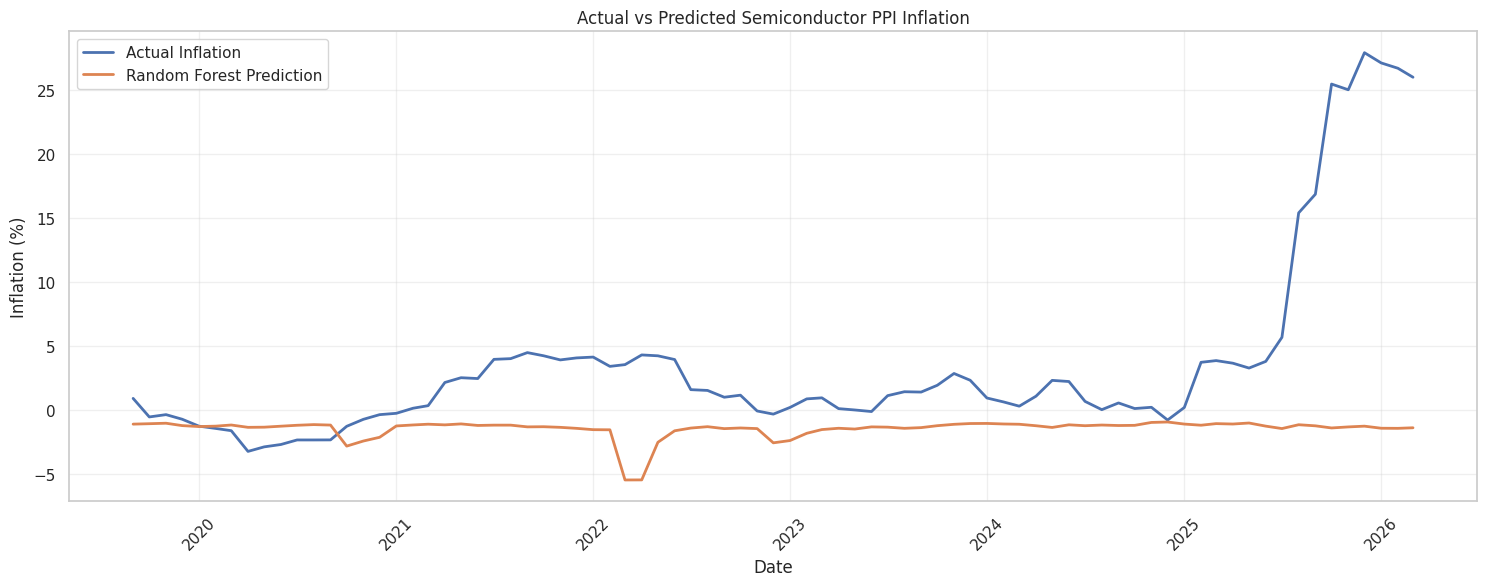

In [ ]:
# Step 15: Actual vs Predicted Visualization

import matplotlib.pyplot as plt

results_df = pd.DataFrame({
    "Date": test_dates.values,
    "Actual": y_test.values,
    "Predicted": rf_predictions
})

plt.figure(figsize=(15, 6))

plt.plot(
    results_df["Date"],
    results_df["Actual"],
    label="Actual Inflation",
    linewidth=2
)

plt.plot(
    results_df["Date"],
    results_df["Predicted"],
    label="Random Forest Prediction",
    linewidth=2
)

plt.title("Actual vs Predicted Semiconductor PPI Inflation")
plt.xlabel("Date")
plt.ylabel("Inflation (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

There are three clear observations:
1. 2019–2024: Inflation mostly fluctuates between approximately -3% and +5%. Random Forest follows the general low-inflation range, although it misses some movements.
2. 2022: The model misses a sudden downward movement and subsequent recovery.
3. 2025–2026: Actual inflation rises sharply, reaching approximately 28%, while Random Forest continues predicting around -1%.

The model is failing to adapt to a substantially different inflation regime.

In [ ]:
# Inspect largest prediction errors

results_df["Error"] = (
    results_df["Actual"] - results_df["Predicted"]
)

results_df["Absolute_Error"] = results_df["Error"].abs()

display(
    results_df.sort_values(
        "Absolute_Error",
        ascending=False
    ).head(10)
)

,Date,Actual,Predicted,Error,Absolute_Error
75,2025-12-01,27.934590,-1.264235,29.198826,29.198826
76,2026-01-01,27.134570,-1.426368,28.560938,28.560938
77,2026-02-01,26.718312,-1.434225,28.152538,28.152538
78,2026-03-01,26.015226,-1.390759,27.405985,27.405985
73,2025-10-01,25.482665,-1.404611,26.887276,26.887276
74,2025-11-01,25.036003,-1.323153,26.359156,26.359156
72,2025-09-01,16.871202,-1.237835,18.109037,18.109037
71,2025-08-01,15.410711,-1.152289,16.563000,16.563000
31,2022-04-01,4.305184,-5.465602,9.770786,9.770786
30,2022-03-01,3.547417,-5.471005,9.018422,9.018422


In [ ]:
# Step 16: Compare training and testing target distributions

print("TRAINING TARGET STATISTICS")
print(y_train.describe())

print("\nTESTING TARGET STATISTICS")
print(y_test.describe())

print("\nTARGET RANGE COMPARISON")

print("Training minimum:", y_train.min())
print("Training maximum:", y_train.max())

print("Testing minimum:", y_test.min())
print("Testing maximum:", y_test.max())

print("\nTRAINING PERIOD MEAN:", y_train.mean())
print("TESTING PERIOD MEAN:", y_test.mean())

TRAINING TARGET STATISTICS
count    308.000000
mean      -2.453530
std        1.971293
min      -11.538462
25%       -3.519995
50%       -2.065404
75%       -1.166023
max        1.072386
Name: PPI_Inflation_YoY_6M_Ahead_pct, dtype: float64

TESTING TARGET STATISTICS
count    79.000000
mean      3.460496
std       7.312071
min      -3.237410
25%      -0.037978
50%       1.121554
75%       3.830336
max      27.934590
Name: PPI_Inflation_YoY_6M_Ahead_pct, dtype: float64

TARGET RANGE COMPARISON
Training minimum: -11.538461538461542
Training maximum: 1.0723860589812562
Testing minimum: -3.237410071942448
Testing maximum: 27.934590146859684

TRAINING PERIOD MEAN: -2.453530136767889
TESTING PERIOD MEAN: 3.4604960705855485


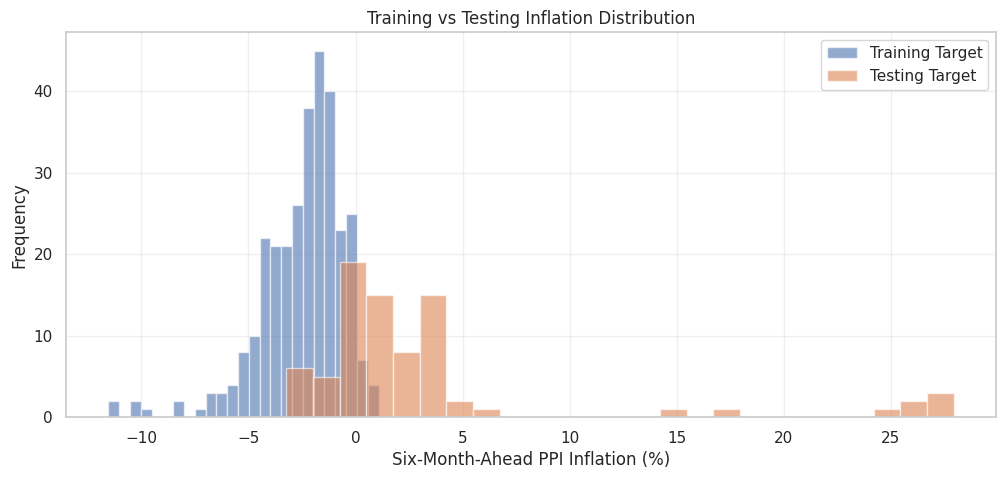

In [ ]:
# Compare target distributions visually

plt.figure(figsize=(12, 5))

plt.hist(y_train, bins=25, alpha=0.6, label="Training Target")
plt.hist(y_test, bins=25, alpha=0.6, label="Testing Target")

plt.title("Training vs Testing Inflation Distribution")
plt.xlabel("Six-Month-Ahead PPI Inflation (%)")
plt.ylabel("Frequency")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Research interpretation**

The chronological evaluation revealed a substantial distribution shift between the training and testing periods. The mean six-month-ahead PPI inflation increased from -2.45% in the training dataset to 3.46% in the testing dataset, while the standard deviation increased from 1.97 to 7.31 percentage points. Furthermore, the maximum testing target reached 27.93%, exceeding the maximum training target of 1.07%. This indicates that the forecasting model was evaluated under inflationary conditions that were not represented in its training data, limiting its ability to generalize to the newer inflation regime.

**Test a persistence forecasting benchmark**

In [ ]:
# Step 17: Persistence Forecast

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
import numpy as np

# Current inflation as prediction of future inflation
persistence_predictions = X_test[
    "PPI_Inflation_YoY_pct"
].values

# Actual six-month-ahead inflation
actual_values = y_test.values

# Evaluation
persistence_mae = mean_absolute_error(
    actual_values, persistence_predictions
)

persistence_rmse = np.sqrt(
    mean_squared_error(actual_values, persistence_predictions)
)

persistence_r2 = r2_score(
    actual_values, persistence_predictions
)

print("PERSISTENCE FORECAST RESULTS")
print("----------------------------")
print("MAE:", round(persistence_mae, 4))
print("RMSE:", round(persistence_rmse, 4))
print("R2 Score:", round(persistence_r2, 4))

# Compare all models so far
comparison = pd.DataFrame({
    "Model": [
        "Dummy Regressor",
        "Random Forest",
        "Persistence Forecast"
    ],
    "MAE": [
        baseline_mae,
        rf_mae,
        persistence_mae
    ],
    "RMSE": [
        baseline_rmse,
        rf_rmse,
        persistence_rmse
    ],
    "R2": [
        baseline_r2,
        rf_r2,
        persistence_r2
    ]
})

display(comparison.round(4))

PERSISTENCE FORECAST RESULTS
----------------------------
MAE: 3.3251
RMSE: 6.0287
R2 Score: 0.3115


,Model,MAE,RMSE,R2
0,Dummy Regressor,5.9509,9.3683,-0.6625
1,Random Forest,5.1523,8.8063,-0.4691
2,Persistence Forecast,3.3251,6.0287,0.3115


Why this experiment matters:

A complex ML model should ideally outperform a simple persistence forecast. If it cannot, we need to reconsider our feature design, model choice, and forecasting strategy.

Our persistence model predicts:
\[
\hat{y}_{t+6}=y_t
\]

**Research insight:**

 A simple economic benchmark can outperform a complex machine-learning model. This is exactly why baseline comparisons are essential in forecasting research.

**Build XGBoost**

In [ ]:
# Step 18: XGBoost Regressor

!pip install xgboost -q

from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
import numpy as np

# Initialize XGBoost
xgb_model = XGBRegressor(
    n_estimators=300,
    max_depth=2,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=5,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

# Train
xgb_model.fit(X_train, y_train)

# Predict
xgb_predictions = xgb_model.predict(X_test)

# Evaluate
xgb_mae = mean_absolute_error(y_test, xgb_predictions)
xgb_rmse = np.sqrt(mean_squared_error(y_test, xgb_predictions))
xgb_r2 = r2_score(y_test, xgb_predictions)

print("XGBOOST RESULTS")
print("----------------")
print("MAE:", round(xgb_mae, 4))
print("RMSE:", round(xgb_rmse, 4))
print("R2 Score:", round(xgb_r2, 4))

# Compare all models
comparison = pd.DataFrame({
    "Model": [
        "Dummy Regressor",
        "Random Forest",
        "Persistence Forecast",
        "XGBoost"
    ],
    "MAE": [
        baseline_mae,
        rf_mae,
        persistence_mae,
        xgb_mae
    ],
    "RMSE": [
        baseline_rmse,
        rf_rmse,
        persistence_rmse,
        xgb_rmse
    ],
    "R2": [
        baseline_r2,
        rf_r2,
        persistence_r2,
        xgb_r2
    ]
})

display(comparison.round(4))

XGBOOST RESULTS
----------------
MAE: 4.9023
RMSE: 8.6866
R2 Score: -0.4294


,Model,MAE,RMSE,R2
0,Dummy Regressor,5.9509,9.3683,-0.6625
1,Random Forest,5.1523,8.8063,-0.4691
2,Persistence Forecast,3.3251,6.0287,0.3115
3,XGBoost,4.9023,8.6866,-0.4294


XGBoost improved MAE by approximately 4.85% compared with Random Forest.



XGBoost still has a negative R².



Persistence has approximately 32.2% lower MAE than XGBoost.

The current indicators and model configurations aren't yet providing enough predictive value beyond the current inflation rate.

**Improve our experimental design**

Instead of predicting:

\[
y_{t+6}
\]

we predict:

\[
\Delta y_{t+6}=y_{t+6}-y_t
\]

Then reconstruct the forecast:

\[
\hat y_{t+6}=y_t+\widehat{\Delta y}_{t+6}
\]

This is called a change-based forecasting approach. It may help the model learn whether inflation will rise or fall, instead of learning to reproduce the historical inflation level.

In [ ]:
# Step 19: Change-based forecasting target

# Current inflation at forecast origin
current_inflation = X_train["PPI_Inflation_YoY_pct"]
current_inflation_test = X_test["PPI_Inflation_YoY_pct"]

# Create change targets
y_train_change = (
    y_train - current_inflation
)

y_test_change = (
    y_test - current_inflation_test
)

print("TRAINING CHANGE TARGET")
print(y_train_change.describe())

print("\nTESTING CHANGE TARGET")
print(y_test_change.describe())

# Train Random Forest on inflation changes
rf_change_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=4,
    min_samples_split=10,
    min_samples_leaf=5,
    max_features=0.7,
    random_state=42,
    n_jobs=-1
)

rf_change_model.fit(X_train, y_train_change)

# Predict future inflation change
predicted_change = rf_change_model.predict(X_test)

# Reconstruct future inflation level
change_predictions = (
    current_inflation_test.values + predicted_change
)

# Evaluate reconstructed predictions
change_mae = mean_absolute_error(
    y_test, change_predictions
)

change_rmse = np.sqrt(
    mean_squared_error(y_test, change_predictions)
)

change_r2 = r2_score(
    y_test, change_predictions
)

print("\nCHANGE-BASED RANDOM FOREST")
print("--------------------------")
print("MAE:", round(change_mae, 4))
print("RMSE:", round(change_rmse, 4))
print("R2 Score:", round(change_r2, 4))

TRAINING CHANGE TARGET
count    308.000000
mean      -0.048154
std        1.937424
min       -8.376503
25%       -1.092413
50%       -0.003196
75%        1.167375
max        6.380868
dtype: float64

TESTING CHANGE TARGET
count    79.000000
mean      1.994759
std       5.725463
min      -4.314029
25%      -0.919836
50%       0.177472
75%       2.837417
max      24.135379
dtype: float64

CHANGE-BASED RANDOM FOREST
--------------------------
MAE: 3.587
RMSE: 6.4331
R2 Score: 0.216


Predicting inflation changes improved Random Forest substantially.



The model now achieves a positive R² of 0.216.

**Research conclusion:**

Modelling inflation changes improves the ability of Random Forest to capture movements in the target, but the macroeconomic features have not yet demonstrated incremental predictive value over the persistence benchmark.

**Visualize change-based predictions**

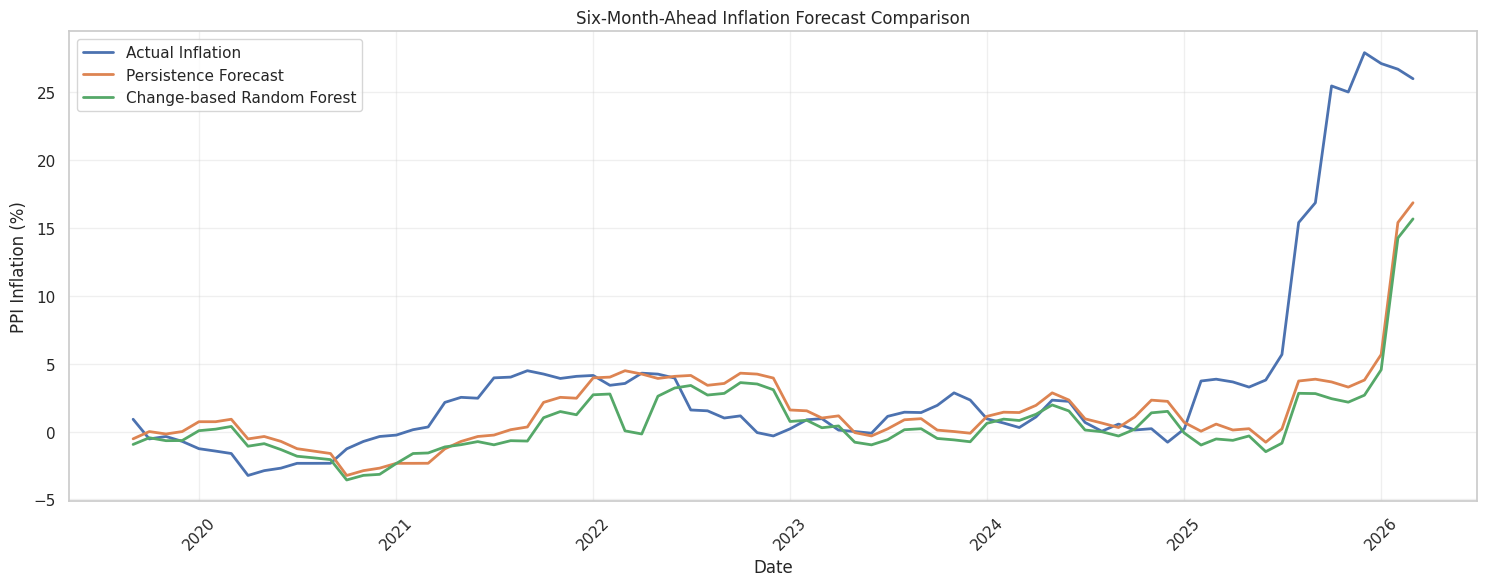

In [ ]:
# Step 20: Compare change-based RF with persistence

comparison_df = pd.DataFrame({
    "Date": test_dates.values,
    "Actual": y_test.values,
    "Persistence": current_inflation_test.values,
    "Change_RF": change_predictions
})

plt.figure(figsize=(15, 6))

plt.plot(
    comparison_df["Date"],
    comparison_df["Actual"],
    label="Actual Inflation",
    linewidth=2
)

plt.plot(
    comparison_df["Date"],
    comparison_df["Persistence"],
    label="Persistence Forecast",
    linewidth=2
)

plt.plot(
    comparison_df["Date"],
    comparison_df["Change_RF"],
    label="Change-based Random Forest",
    linewidth=2
)

plt.title("Six-Month-Ahead Inflation Forecast Comparison")
plt.xlabel("Date")
plt.ylabel("PPI Inflation (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# Inspect predictions during the latest inflation increase

display(
    comparison_df.tail(12).round(3)
)

,Date,Actual,Persistence,Change_RF
67,2025-04-01,3.658,0.113,-0.649
68,2025-05-01,3.278,0.211,-0.324
69,2025-06-01,3.799,-0.785,-1.483
70,2025-07-01,5.682,0.197,-0.856
71,2025-08-01,15.411,3.727,2.820
72,2025-09-01,16.871,3.861,2.799
73,2025-10-01,25.483,3.658,2.423
74,2025-11-01,25.036,3.278,2.166
75,2025-12-01,27.935,3.799,2.682
76,2026-01-01,27.135,5.682,4.558


Look at the 2025–2026 movement:
- Persistence captures the increase because it carries forward the latest observed inflation.
- Change-based Random Forest also captures the upward movement, but its predictions remain below the actual values.
- Neither approach fully anticipates the extreme increase.

Our target is six-month-ahead inflation:

\[
y_{t+6}
\]

But our graph currently uses the forecast-origin date \(t\) as its x-axis. The actual value belongs to the target date \(t+6\).

For example, a forecast made using August 2025 information predicts February 2026 inflation.

We should shift the plotted dates forward by six months.

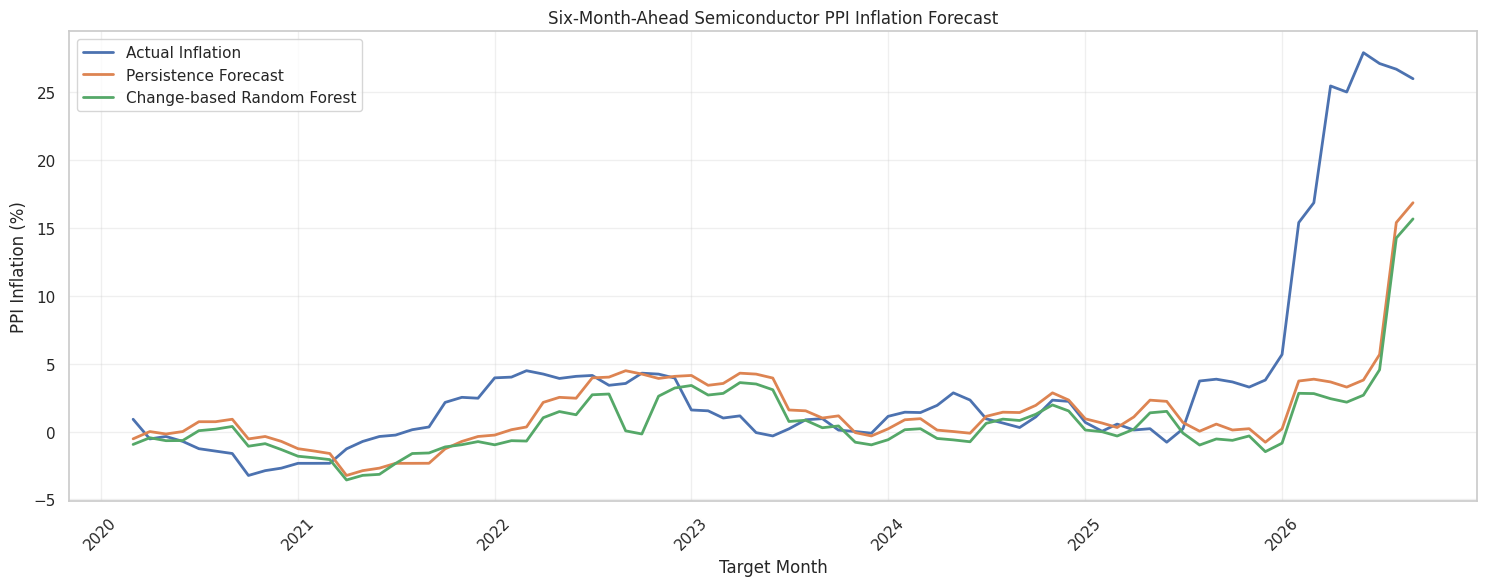

,Date,Forecast_Date,Actual,Persistence,Change_RF
67,2025-04-01,2025-10-01,3.658,0.113,-0.649
68,2025-05-01,2025-11-01,3.278,0.211,-0.324
69,2025-06-01,2025-12-01,3.799,-0.785,-1.483
70,2025-07-01,2026-01-01,5.682,0.197,-0.856
71,2025-08-01,2026-02-01,15.411,3.727,2.820
72,2025-09-01,2026-03-01,16.871,3.861,2.799
73,2025-10-01,2026-04-01,25.483,3.658,2.423
74,2025-11-01,2026-05-01,25.036,3.278,2.166
75,2025-12-01,2026-06-01,27.935,3.799,2.682
76,2026-01-01,2026-07-01,27.135,5.682,4.558


In [ ]:
# Step 21: Correct six-month forecast dates

comparison_df["Forecast_Date"] = (
    pd.to_datetime(comparison_df["Date"])
    + pd.DateOffset(months=6)
)

plt.figure(figsize=(15, 6))

plt.plot(
    comparison_df["Forecast_Date"],
    comparison_df["Actual"],
    label="Actual Inflation",
    linewidth=2
)

plt.plot(
    comparison_df["Forecast_Date"],
    comparison_df["Persistence"],
    label="Persistence Forecast",
    linewidth=2
)

plt.plot(
    comparison_df["Forecast_Date"],
    comparison_df["Change_RF"],
    label="Change-based Random Forest",
    linewidth=2
)

plt.title("Six-Month-Ahead Semiconductor PPI Inflation Forecast")
plt.xlabel("Target Month")
plt.ylabel("PPI Inflation (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

display(
    comparison_df[
        ["Date", "Forecast_Date", "Actual",
         "Persistence", "Change_RF"]
    ].tail(12).round(3)
)

**Random Forest feature importance**

TOP 15 IMPORTANT FEATURES


,Feature,Importance
3,PNICKUSDM,0.32486
6,PPI_Inflation_YoY_pct,0.17987
14,IPG3344S_YoY_pct,0.11632
13,PNICKUSDM_YoY_pct,0.05148
16,PPI_Inflation_YoY_pct_Lag_1,0.03725
4,CAPUTLG3344S,0.03115
0,PCU3344133441,0.03013
11,PCOPPUSDM_YoY_pct,0.02471
19,PPI_Inflation_YoY_pct_Lag_6,0.02313
5,IPG3344S,0.02150


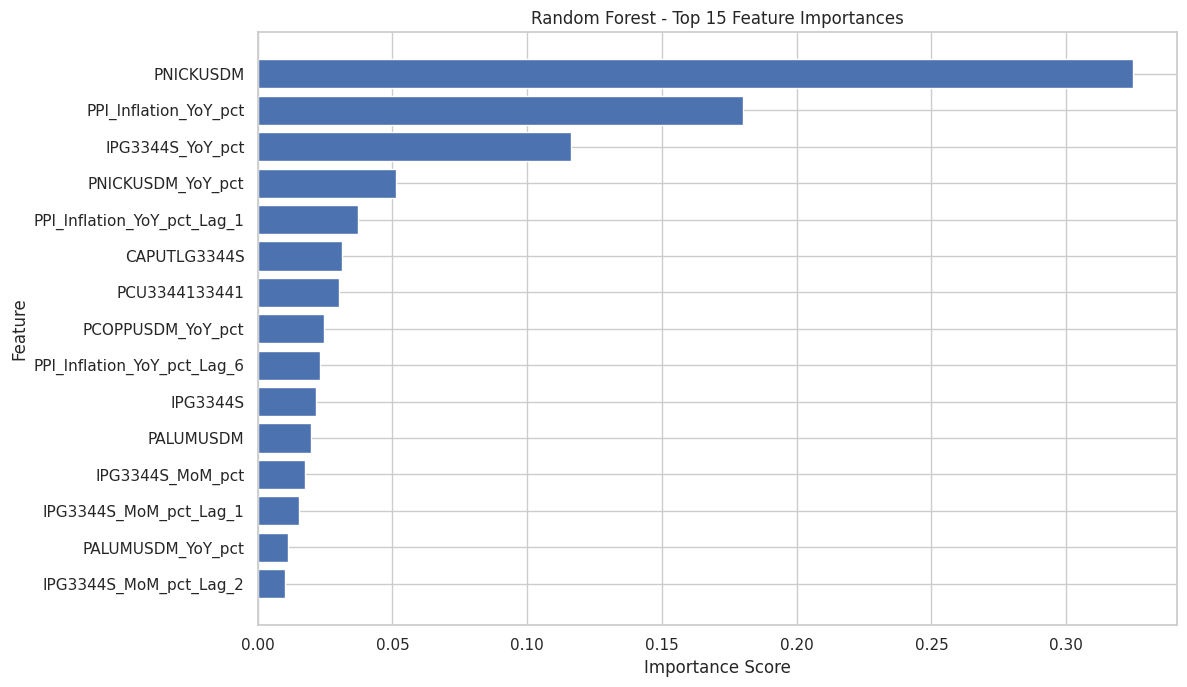

In [ ]:
# Step 22: Feature Importance Analysis

import pandas as pd
import matplotlib.pyplot as plt

# Extract feature importance
importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

# Sort by importance
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

# Display top 15 features
print("TOP 15 IMPORTANT FEATURES")
display(importance_df.head(15).round(5))

# Visualize top 15
top_features = importance_df.head(15).sort_values(
    by="Importance"
)

plt.figure(figsize=(12, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Random Forest - Top 15 Feature Importances")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

1. Nickel prices dominate the model.

Nickel accounts for approximately 32.5% of the Random Forest's total impurity-based feature importance.

This suggests that nickel price levels are particularly useful for the fitted model's predictions.

2. Historical inflation is important.

Current PPI inflation and its lagged value together contribute substantially to the model's importance scores.

3. Industrial production matters.

Industrial production's YoY change ranks third, suggesting that manufacturing activity may contain useful predictive information.

**Research caution:**

Feature importance does not establish economic causation. Also, correlated indicators can share or distort importance scores. We need another test before interpreting these features as genuinely predictive.

**Permutation importance**

TOP 15 TEST-SET PERMUTATION IMPORTANCES


,Feature,Importance,Std
1,PCOPPUSDM,0.00696,0.00130
0,PCU3344133441,0.00587,0.00328
4,CAPUTLG3344S,0.00294,0.00438
12,PALUMUSDM_YoY_pct,0.00197,0.00084
36,Capacity_Change_Lag_1,0.00197,0.00090
14,IPG3344S_YoY_pct,0.00145,0.00231
31,PNICKUSDM_MoM_pct_Lag_6,0.00133,0.00053
18,PPI_Inflation_YoY_pct_Lag_3,0.00076,0.00033
39,Capacity_Change_Lag_6,0.00055,0.00171
21,PCOPPUSDM_MoM_pct_Lag_2,0.00045,0.00076


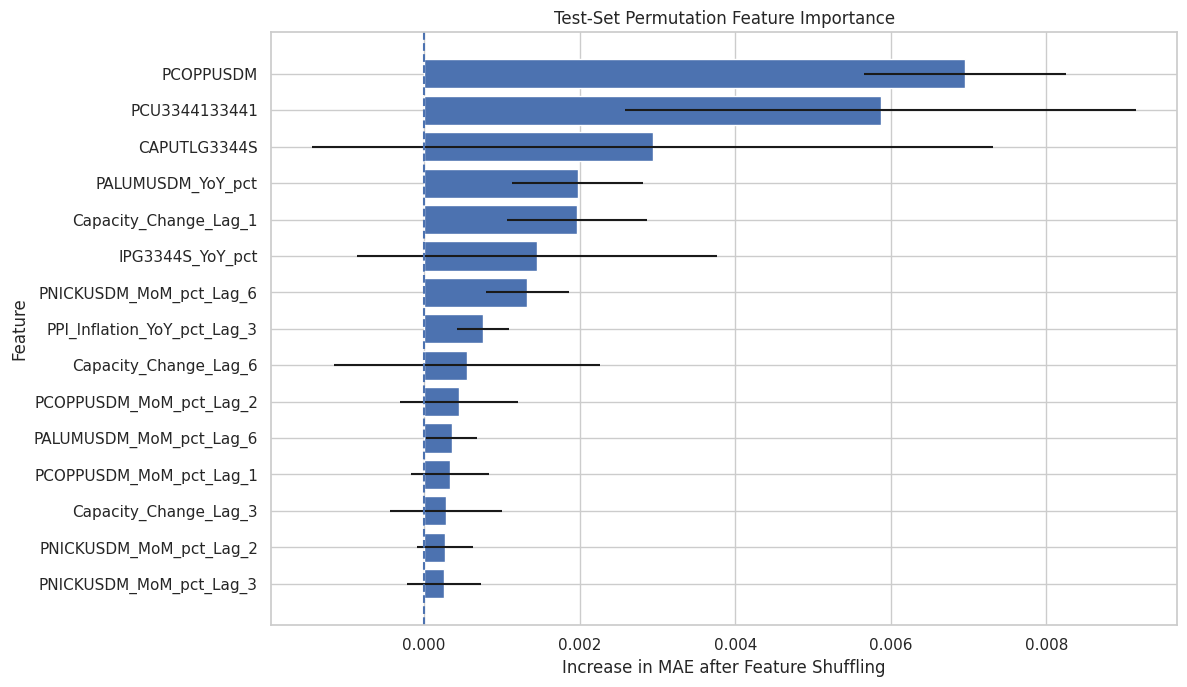

In [ ]:
# Step 23: Permutation Importance

from sklearn.inspection import permutation_importance

# Evaluate importance using test-set MAE
perm_result = permutation_importance(
    rf_model,
    X_test,
    y_test,
    scoring="neg_mean_absolute_error",
    n_repeats=30,
    random_state=42,
    n_jobs=-1
)

# Create results dataframe
permutation_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": perm_result.importances_mean,
    "Std": perm_result.importances_std
})

# Sort by importance
permutation_df = permutation_df.sort_values(
    by="Importance",
    ascending=False
)

print("TOP 15 TEST-SET PERMUTATION IMPORTANCES")

display(permutation_df.head(15).round(5))

# Visualize top 15
top_perm = permutation_df.head(15).sort_values(
    by="Importance"
)

plt.figure(figsize=(12, 7))

plt.barh(
    top_perm["Feature"],
    top_perm["Importance"],
    xerr=top_perm["Std"]
)

plt.axvline(0, linestyle="--")

plt.title("Test-Set Permutation Feature Importance")
plt.xlabel("Increase in MAE after Feature Shuffling")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

Copper prices and semiconductor PPI levels appear particularly useful to this fitted model on the test period. However, the error increases are small, and several standard deviations are large relative to their importance scores. We should avoid claiming that these features are definitively important without further validation.

**Feature ablation experiment**

In [ ]:
# Step 24: Feature Group Ablation Experiment

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

feature_groups = {
    "Inflation History": [
        c for c in X_train.columns
        if "PPI_Inflation" in c
    ],

    "Commodity Indicators": [
        c for c in X_train.columns
        if any(x in c for x in [
            "PCOPPUSDM", "PALUMUSDM", "PNICKUSDM"
        ])
    ],

    "Manufacturing Indicators": [
        c for c in X_train.columns
        if any(x in c for x in [
            "CAPUTLG3344S", "IPG3344S"
        ])
    ],

    "All Features": list(X_train.columns)
}

ablation_results = []

for group_name, selected_features in feature_groups.items():

    model = RandomForestRegressor(
        n_estimators=300,
        max_depth=5,
        min_samples_split=10,
        min_samples_leaf=5,
        max_features=0.7,
        random_state=42,
        n_jobs=-1
    )

    model.fit(
        X_train[selected_features],
        y_train
    )

    predictions = model.predict(
        X_test[selected_features]
    )

    mae = mean_absolute_error(y_test, predictions)

    rmse = np.sqrt(
        mean_squared_error(y_test, predictions)
    )

    r2 = r2_score(y_test, predictions)

    ablation_results.append({
        "Feature Group": group_name,
        "Number of Features": len(selected_features),
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

ablation_df = pd.DataFrame(ablation_results)

display(
    ablation_df.sort_values("MAE").round(4)
)

,Feature Group,Number of Features,MAE,RMSE,R2
0,Inflation History,5,5.0087,8.6763,-0.4260
3,All Features,40,5.1523,8.8063,-0.4691
2,Manufacturing Indicators,8,5.1674,8.8007,-0.4672
1,Commodity Indicators,21,6.0515,9.4106,-0.6776


1. Inflation history performs best among these Random Forest configurations.

Using only five historical inflation features produces a lower MAE than using all 40 features.

2. Commodity indicators perform poorly in isolation.

Their MAE is 6.0515, worse than the Dummy Regressor's 5.9509.

3. More features may introduce noise.

Adding commodity and manufacturing indicators did not improve this model's test performance.

4. Persistence still wins overall.

Our best Random Forest configuration has MAE 5.0087, compared with 3.3251 for persistence.

This is an important distinction: the ablation results do not establish that commodities have no economic relationship with semiconductor inflation. They show that these features did not improve this particular forecasting model on this particular test period.

**Time-series cross-validation**

In [ ]:
# Step 25: Time Series Cross Validation

from sklearn.model_selection import TimeSeriesSplit
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
import pandas as pd
import numpy as np

# Use only training-period data for model selection
tscv = TimeSeriesSplit(
    n_splits=5,
    gap=6
)

cv_results = []

for fold, (train_idx, val_idx) in enumerate(
    tscv.split(X_train), start=1
):

    X_fold_train = X_train.iloc[train_idx]
    y_fold_train = y_train.iloc[train_idx]

    X_fold_val = X_train.iloc[val_idx]
    y_fold_val = y_train.iloc[val_idx]

    model = RandomForestRegressor(
        n_estimators=300,
        max_depth=5,
        min_samples_split=10,
        min_samples_leaf=5,
        max_features=0.7,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_fold_train, y_fold_train)

    predictions = model.predict(X_fold_val)

    mae = mean_absolute_error(
        y_fold_val,
        predictions
    )

    # Persistence benchmark
    persistence = X_fold_val[
        "PPI_Inflation_YoY_pct"
    ].values

    persistence_mae = mean_absolute_error(
        y_fold_val,
        persistence
    )

    cv_results.append({
        "Fold": fold,
        "Training Samples": len(train_idx),
        "Validation Samples": len(val_idx),
        "RF MAE": mae,
        "Persistence MAE": persistence_mae
    })

cv_df = pd.DataFrame(cv_results)

display(cv_df.round(4))

print("\nAVERAGE CROSS-VALIDATION RESULTS")
print("Random Forest MAE:", round(cv_df["RF MAE"].mean(), 4))
print("Persistence MAE:", round(cv_df["Persistence MAE"].mean(), 4))

,Fold,Training Samples,Validation Samples,RF MAE,Persistence MAE
0,1,47,51,1.5178,1.0080
1,2,98,51,1.6153,1.8342
2,3,149,51,2.4370,2.9218
3,4,200,51,1.2158,0.9227
4,5,251,51,0.9275,0.9486



AVERAGE CROSS-VALIDATION RESULTS
Random Forest MAE: 1.5427
Persistence MAE: 1.5271


1. Random Forest outperforms persistence in two validation folds and narrowly wins another.
2. Persistence wins two folds and has the slightly better overall average.
3. The performance difference is very small.
4. Neither model demonstrates a consistent advantage across every historical period.
An important distinction: these cross-validation scores are much better than the final test scores. The 2019–2026 test period contains a substantially different inflation regime.

Our current conclusion: Random Forest has not demonstrated reliable forecasting superiority over persistence.

**Compare feature groups using cross-validation**

Previously, inflation history alone performed better than all 40 features on the test set.

Now let's verify that using only the training period. This is important because we should select features using cross-validation rather than repeatedly optimizing against our final test set.


In [ ]:
# Step 26: Cross-validation feature group comparison

from sklearn.model_selection import TimeSeriesSplit
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
import pandas as pd
import numpy as np

feature_groups = {
    "Inflation History": [
        c for c in X_train.columns
        if "PPI_Inflation" in c
    ],

    "Commodity Indicators": [
        c for c in X_train.columns
        if any(x in c for x in [
            "PCOPPUSDM", "PALUMUSDM", "PNICKUSDM"
        ])
    ],

    "Manufacturing Indicators": [
        c for c in X_train.columns
        if any(x in c for x in [
            "CAPUTLG3344S", "IPG3344S"
        ])
    ],

    "All Features": list(X_train.columns)
}

tscv = TimeSeriesSplit(
    n_splits=5,
    gap=6
)

group_cv_results = []

for group_name, selected_features in feature_groups.items():

    fold_maes = []

    for train_idx, val_idx in tscv.split(X_train):

        X_fold_train = X_train.iloc[train_idx][selected_features]
        y_fold_train = y_train.iloc[train_idx]

        X_fold_val = X_train.iloc[val_idx][selected_features]
        y_fold_val = y_train.iloc[val_idx]

        model = RandomForestRegressor(
            n_estimators=300,
            max_depth=5,
            min_samples_split=10,
            min_samples_leaf=5,
            max_features=0.7,
            random_state=42,
            n_jobs=-1
        )

        model.fit(X_fold_train, y_fold_train)

        predictions = model.predict(X_fold_val)

        fold_maes.append(
            mean_absolute_error(y_fold_val, predictions)
        )

    group_cv_results.append({
        "Feature Group": group_name,
        "Features": len(selected_features),
        "Mean CV MAE": np.mean(fold_maes),
        "Std CV MAE": np.std(fold_maes)
    })

group_cv_df = pd.DataFrame(group_cv_results)

display(
    group_cv_df.sort_values("Mean CV MAE").round(4)
)

,Feature Group,Features,Mean CV MAE,Std CV MAE
0,Inflation History,5,1.4940,0.4667
3,All Features,40,1.5427,0.5081
1,Commodity Indicators,21,1.5485,0.7663
2,Manufacturing Indicators,8,1.5843,0.5736


**Interpretation**

1. Inflation history has the lowest average validation error.
2. It also has the lowest variation in validation error.
3. Adding all 40 features does not improve the Random Forest's average validation performance.
The difference is small, so we shouldn't claim that the additional indicators are useless. We can say that they have not demonstrated incremental predictive value in this experiment.

**Ridge Regression**

Why?
- We have relatively few observations.
- Several of our macroeconomic features are correlated.
- Ridge regression penalizes excessively large coefficients.
- It provides a useful comparison against nonlinear tree models.

In [ ]:
# Step 27: Ridge Regression with Time-Series CV

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error
import pandas as pd
import numpy as np

feature_groups = {
    "Inflation History": [
        c for c in X_train.columns
        if "PPI_Inflation" in c
    ],

    "All Features": list(X_train.columns)
}

tscv = TimeSeriesSplit(
    n_splits=5,
    gap=6
)

ridge_results = []

for group_name, selected_features in feature_groups.items():

    fold_maes = []
    persistence_maes = []

    for train_idx, val_idx in tscv.split(X_train):

        X_fold_train = X_train.iloc[train_idx][selected_features]
        y_fold_train = y_train.iloc[train_idx]

        X_fold_val = X_train.iloc[val_idx][selected_features]
        y_fold_val = y_train.iloc[val_idx]

        # Scaling is fitted only on the fold's training data
        ridge_model = Pipeline([
            ("scaler", StandardScaler()),
            ("ridge", Ridge(alpha=10.0))
        ])

        ridge_model.fit(X_fold_train, y_fold_train)

        predictions = ridge_model.predict(X_fold_val)

        fold_maes.append(
            mean_absolute_error(y_fold_val, predictions)
        )

        persistence = X_fold_val[
            "PPI_Inflation_YoY_pct"
        ].values

        persistence_maes.append(
            mean_absolute_error(y_fold_val, persistence)
        )

    ridge_results.append({
        "Feature Group": group_name,
        "Mean Ridge MAE": np.mean(fold_maes),
        "Std Ridge MAE": np.std(fold_maes),
        "Mean Persistence MAE": np.mean(persistence_maes)
    })

ridge_cv_df = pd.DataFrame(ridge_results)

display(ridge_cv_df.round(4))

,Feature Group,Mean Ridge MAE,Std Ridge MAE,Mean Persistence MAE
0,Inflation History,1.400,0.3217,1.5271
1,All Features,2.244,1.2477,1.5271


1. Ridge with inflation-history features has approximately 8.3% lower MAE than persistence.
2. It also outperforms our inflation-history Random Forest.
3. Ridge with all 40 features performs considerably worse.
4. The standard deviation of 0.3217 suggests relatively consistent performance across the five folds.

**Research interpretation:**

A regularized linear model using historical inflation information provides better validation accuracy than the nonlinear tree-based models tested so far. Including all macroeconomic indicators appears to introduce noise or unstable relationships.

However, this is a cross-validation result, not yet a final test-set result.

**Evaluate Ridge using the untouched test set**

In [ ]:
# Step 28: Final Ridge Model Evaluation

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
import numpy as np
import pandas as pd

# Select inflation-history features
inflation_features = [
    c for c in X_train.columns
    if "PPI_Inflation" in c
]

X_train_ridge = X_train[inflation_features]
X_test_ridge = X_test[inflation_features]

# Build Ridge pipeline
final_ridge_model = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge(alpha=10.0))
])

# Train
final_ridge_model.fit(
    X_train_ridge,
    y_train
)

# Predict
ridge_predictions = final_ridge_model.predict(
    X_test_ridge
)

# Evaluate
ridge_mae = mean_absolute_error(
    y_test, ridge_predictions
)

ridge_rmse = np.sqrt(
    mean_squared_error(y_test, ridge_predictions)
)

ridge_r2 = r2_score(
    y_test, ridge_predictions
)

print("RIDGE REGRESSION TEST RESULTS")
print("-----------------------------")
print("MAE:", round(ridge_mae, 4))
print("RMSE:", round(ridge_rmse, 4))
print("R2 Score:", round(ridge_r2, 4))

# Updated comparison
final_comparison = pd.DataFrame({
    "Model": [
        "Dummy Regressor",
        "Random Forest",
        "XGBoost",
        "Change-based RF",
        "Persistence",
        "Ridge - Inflation History"
    ],
    "MAE": [
        baseline_mae,
        rf_mae,
        xgb_mae,
        change_mae,
        persistence_mae,
        ridge_mae
    ],
    "RMSE": [
        baseline_rmse,
        rf_rmse,
        xgb_rmse,
        change_rmse,
        persistence_rmse,
        ridge_rmse
    ],
    "R2": [
        baseline_r2,
        rf_r2,
        xgb_r2,
        change_r2,
        persistence_r2,
        ridge_r2
    ]
})

display(
    final_comparison.sort_values("MAE").round(4)
)

RIDGE REGRESSION TEST RESULTS
-----------------------------
MAE: 4.4285
RMSE: 7.4066
R2 Score: -0.0392


,Model,MAE,RMSE,R2
4,Persistence,0.9486,6.0287,0.3115
3,Change-based RF,3.5870,6.4331,0.2160
5,Ridge - Inflation History,4.4285,7.4066,-0.0392
2,XGBoost,4.9023,8.6866,-0.4294
1,Random Forest,5.1523,8.8063,-0.4691
0,Dummy Regressor,5.9509,9.3683,-0.6625


good cross-validation performance does not guarantee good performance on a future economic regime.

Why did Ridge fail to generalize?
- Historical training and validation periods mostly contained low or negative inflation.
- The test period contained a much larger inflation increase.
- Ridge learns a regularized linear relationship from historical observations.
- Those historical relationships did not transfer sufficiently well to the newer regime.

**Research**

Our best test-set model remains the persistence forecast, followed by change-based Random Forest.

We should not declare Ridge our final model just because it won cross-validation

**Visualize Ridge predictions**

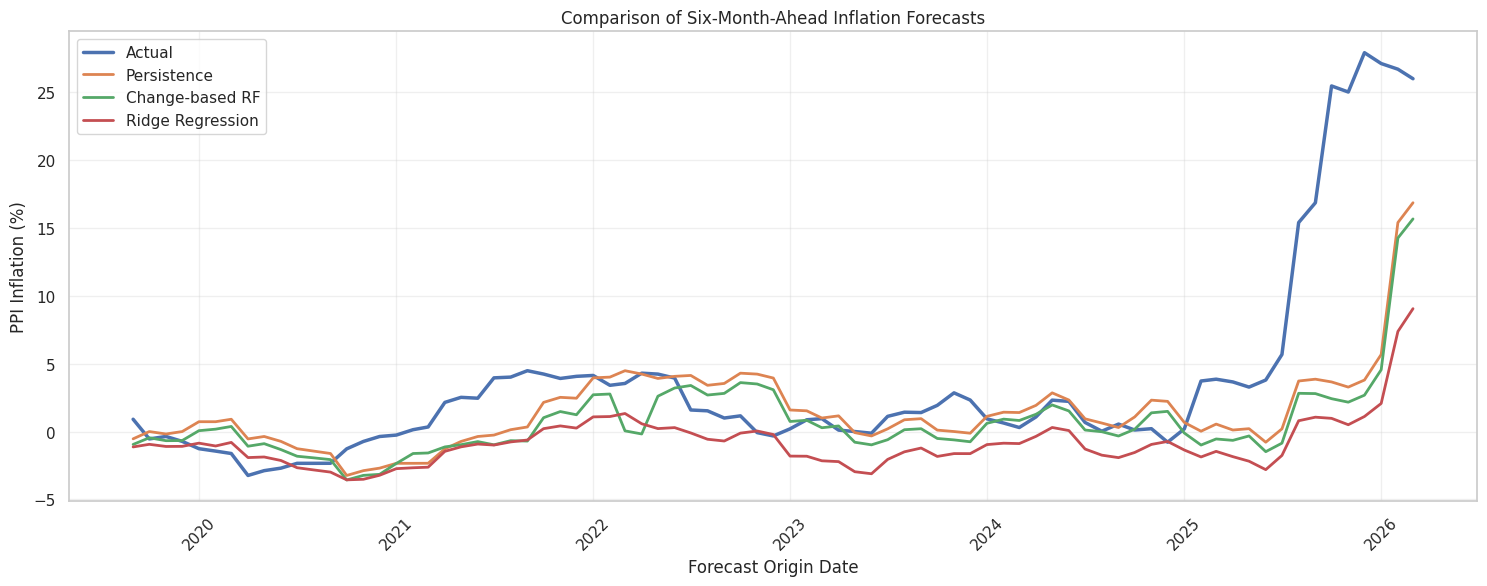

In [ ]:
# Step 29: Ridge vs Persistence vs Actual

ridge_comparison = pd.DataFrame({
    "Date": test_dates.values,
    "Actual": y_test.values,
    "Persistence": current_inflation_test.values,
    "Change_RF": change_predictions,
    "Ridge": ridge_predictions
})

plt.figure(figsize=(15, 6))

plt.plot(
    ridge_comparison["Date"],
    ridge_comparison["Actual"],
    label="Actual",
    linewidth=2.5
)

plt.plot(
    ridge_comparison["Date"],
    ridge_comparison["Persistence"],
    label="Persistence",
    linewidth=2
)

plt.plot(
    ridge_comparison["Date"],
    ridge_comparison["Change_RF"],
    label="Change-based RF",
    linewidth=2
)

plt.plot(
    ridge_comparison["Date"],
    ridge_comparison["Ridge"],
    label="Ridge Regression",
    linewidth=2
)

plt.title("Comparison of Six-Month-Ahead Inflation Forecasts")
plt.xlabel("Forecast Origin Date")
plt.ylabel("PPI Inflation (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**ARIMA**

Why?
- It models temporal dependencies directly.
- It provides a statistical benchmark against ML.
- It helps determine whether the target's own historical patterns are sufficient for forecasting.

Unlike Random Forest and XGBoost, ARIMA directly models the historical behaviour of a time series.

Our earlier ADF test found that:
- PPI YoY inflation was non-stationary.
- First-differenced inflation was stationary.
Therefore, we'll begin with ARIMA(1,1,1).

Compare the sixth-month forecast with the actual six-month-ahead target.


**Install and import ARIMA**

In [ ]:
!pip install statsmodels -q

from statsmodels.tsa.arima.model import ARIMA
import pandas as pd
import numpy as np
import warnings

warnings.filterwarnings("ignore")

print("ARIMA libraries imported successfully!")

ARIMA libraries imported successfully!


**Generate six-month-ahead forecasts**

In [ ]:
# Step 30.2: Rolling-origin ARIMA forecasting (Fixed)

arima_predictions = []

# Prepare monthly time-series data with a proper date index
arima_data = feature_df[
    ["observation_date", "PPI_Inflation_YoY_pct"]
].dropna().copy()

arima_data["observation_date"] = pd.to_datetime(
    arima_data["observation_date"]
)

arima_data = arima_data.set_index("observation_date")

# Explicit monthly frequency
arima_data = arima_data.asfreq("MS")

# Forecast origins
forecast_origins = test_dates.reset_index(drop=True)

for origin in forecast_origins:

    # Historical information available at forecast origin
    history = arima_data.loc[
        :origin, "PPI_Inflation_YoY_pct"
    ].dropna()

    # Fit ARIMA
    arima_model = ARIMA(
        history,
        order=(1, 1, 1)
    )

    arima_fitted = arima_model.fit()

    # Forecast six months ahead
    forecast = arima_fitted.forecast(steps=6)

    # Store sixth-month forecast
    arima_predictions.append(float(forecast.iloc[5]))

arima_predictions = np.array(arima_predictions)

print("ARIMA forecasting completed successfully!")
print("Number of predictions:", len(arima_predictions))

ARIMA forecasting completed successfully!
Number of predictions: 79


**Evaluate ARIMA**

In [ ]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

arima_mae = mean_absolute_error(
    y_test,
    arima_predictions
)

arima_rmse = np.sqrt(
    mean_squared_error(y_test, arima_predictions)
)

arima_r2 = r2_score(
    y_test,
    arima_predictions
)

print("ARIMA(1,1,1) RESULTS")
print("--------------------")
print("MAE:", round(arima_mae, 4))
print("RMSE:", round(arima_rmse, 4))
print("R2 Score:", round(arima_r2, 4))

ARIMA(1,1,1) RESULTS
--------------------
MAE: 3.2389
RMSE: 5.8719
R2 Score: 0.3468


In [ ]:
final_comparison = pd.DataFrame({
    "Model": [
        "Dummy Regressor",
        "Random Forest",
        "XGBoost",
        "Change-based RF",
        "Ridge Regression",
        "Persistence",
        "ARIMA(1,1,1)"
    ],
    "MAE": [
        baseline_mae,
        rf_mae,
        xgb_mae,
        change_mae,
        ridge_mae,
        persistence_mae,
        arima_mae
    ],
    "RMSE": [
        baseline_rmse,
        rf_rmse,
        xgb_rmse,
        change_rmse,
        ridge_rmse,
        persistence_rmse,
        arima_rmse
    ],
    "R2": [
        baseline_r2,
        rf_r2,
        xgb_r2,
        change_r2,
        ridge_r2,
        persistence_r2,
        arima_r2
    ]
})

display(
    final_comparison.sort_values("MAE").round(4)
)

,Model,MAE,RMSE,R2
5,Persistence,0.9486,6.0287,0.3115
6,"ARIMA(1,1,1)",3.2389,5.8719,0.3468
3,Change-based RF,3.5870,6.4331,0.2160
4,Ridge Regression,4.4285,7.4066,-0.0392
2,XGBoost,4.9023,8.6866,-0.4294
1,Random Forest,5.1523,8.8063,-0.4691
0,Dummy Regressor,5.9509,9.3683,-0.6625


**Visualize ARIMA predictions**

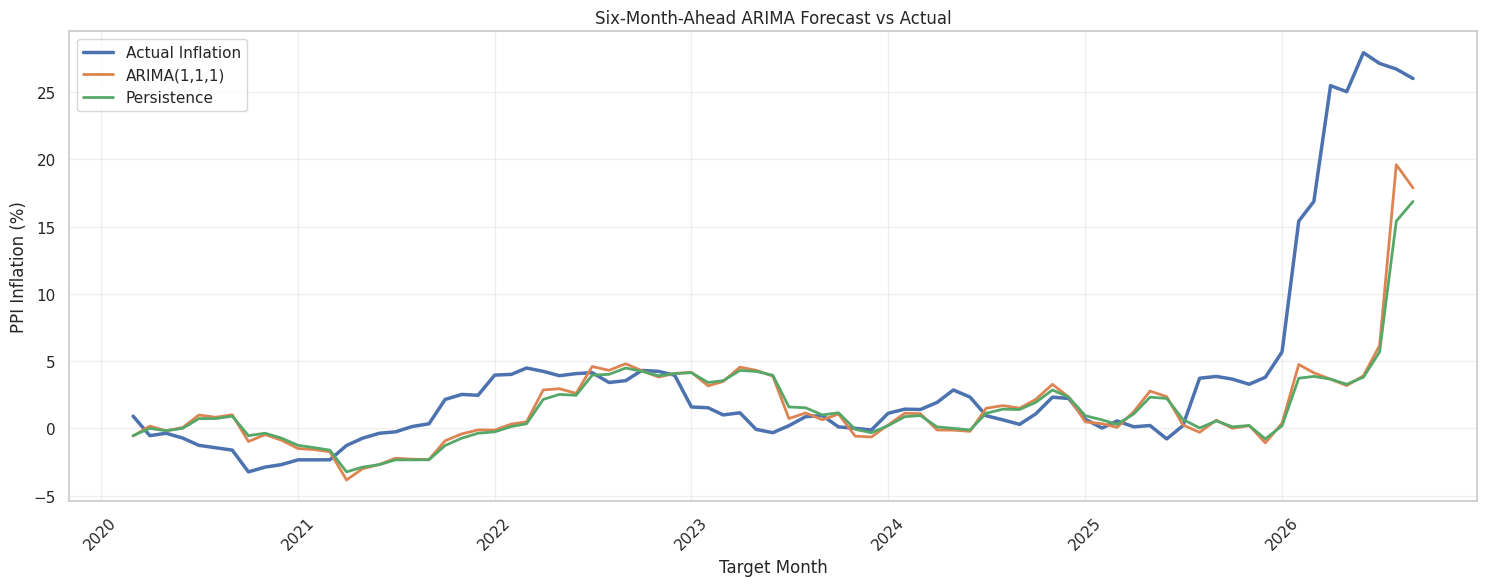

,Forecast_Origin,Actual,ARIMA,Persistence,Target_Date
67,2025-04-01,3.658,0.004,0.113,2025-10-01
68,2025-05-01,3.278,0.205,0.211,2025-11-01
69,2025-06-01,3.799,-1.077,-0.785,2025-12-01
70,2025-07-01,5.682,0.379,0.197,2026-01-01
71,2025-08-01,15.411,4.751,3.727,2026-02-01
72,2025-09-01,16.871,4.128,3.861,2026-03-01
73,2025-10-01,25.483,3.655,3.658,2026-04-01
74,2025-11-01,25.036,3.182,3.278,2026-05-01
75,2025-12-01,27.935,3.908,3.799,2026-06-01
76,2026-01-01,27.135,6.168,5.682,2026-07-01


In [ ]:
# Step 31: Actual vs ARIMA vs Persistence

arima_comparison = pd.DataFrame({
    "Forecast_Origin": test_dates.values,
    "Actual": y_test.values,
    "ARIMA": arima_predictions,
    "Persistence": current_inflation_test.values
})

# Convert forecast origins into target dates
arima_comparison["Target_Date"] = (
    pd.to_datetime(arima_comparison["Forecast_Origin"])
    + pd.DateOffset(months=6)
)

plt.figure(figsize=(15, 6))

plt.plot(
    arima_comparison["Target_Date"],
    arima_comparison["Actual"],
    label="Actual Inflation",
    linewidth=2.5
)

plt.plot(
    arima_comparison["Target_Date"],
    arima_comparison["ARIMA"],
    label="ARIMA(1,1,1)",
    linewidth=2
)

plt.plot(
    arima_comparison["Target_Date"],
    arima_comparison["Persistence"],
    label="Persistence",
    linewidth=2
)

plt.title("Six-Month-Ahead ARIMA Forecast vs Actual")
plt.xlabel("Target Month")
plt.ylabel("PPI Inflation (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

display(arima_comparison.tail(12).round(3))

**ARIMA residual diagnostics**

Before experimenting with more ARIMA configurations, we should check whether the model has captured the time-series structure adequately.

We'll examine:
- Residual distribution.
- Residual autocorrelation.
- Ljung–Box test.

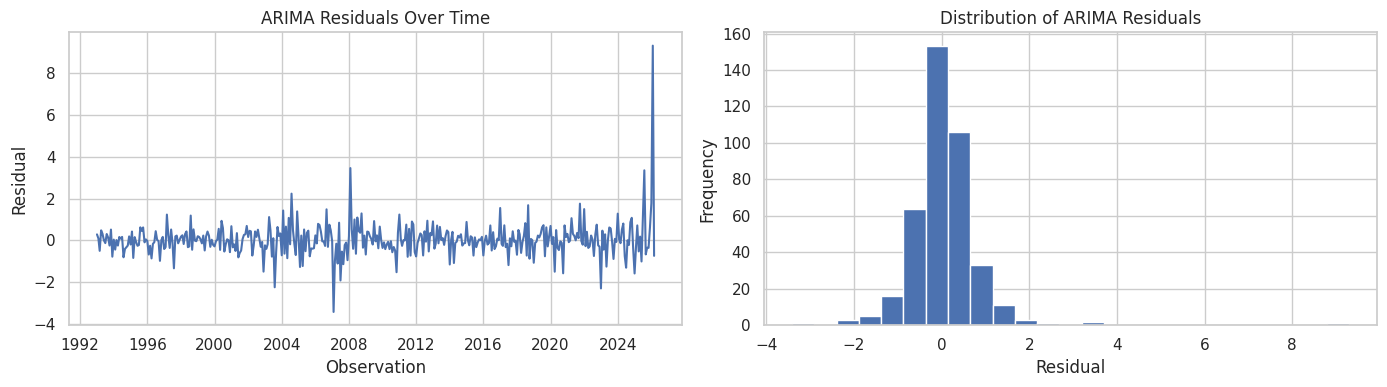

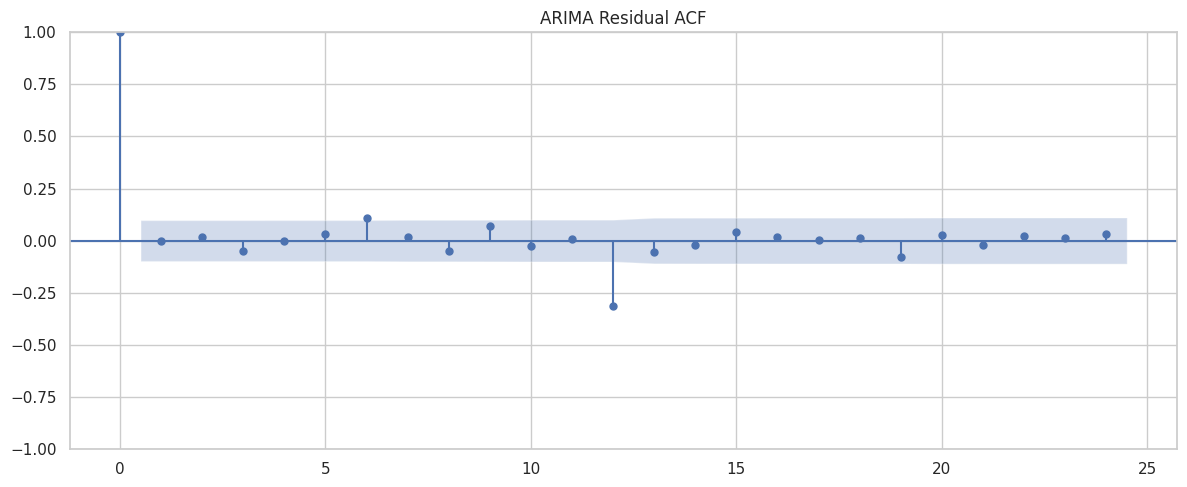

LJUNG-BOX TEST RESULTS


,lb_stat,lb_pvalue
12,50.598448,0.000001
24,56.948263,0.000170


In [ ]:
# Step 32: ARIMA residual diagnostics

import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox

# Residuals from the final ARIMA fit
residuals = arima_fitted.resid

# Residual plots
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(residuals)
axes[0].set_title("ARIMA Residuals Over Time")
axes[0].set_xlabel("Observation")
axes[0].set_ylabel("Residual")

axes[1].hist(residuals, bins=25)
axes[1].set_title("Distribution of ARIMA Residuals")
axes[1].set_xlabel("Residual")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

# Autocorrelation plot
plot_acf(residuals, lags=24)
plt.title("ARIMA Residual ACF")
plt.tight_layout()
plt.show()

# Ljung-Box test
lb_result = acorr_ljungbox(
    residuals,
    lags=[12, 24],
    return_df=True
)

print("LJUNG-BOX TEST RESULTS")
display(lb_result)

Looking at your graph:
- Lags 1–11: Most autocorrelation values lie within the confidence interval.
- Lag 6: Small positive autocorrelation, within the confidence interval.
- Lag 12: Approximately -0.31, clearly outside the confidence interval.
- Lags 13–24: Most values are within the confidence interval.
What does lag 12 mean?
Your data is monthly.

Therefore, lag 12 represents a relationship between residuals separated by 12 months.

This suggests that ARIMA(1,1,1) may not have captured all annual seasonal structure.

However, one significant ACF spike does not automatically prove that SARIMA will perform better. We need statistical testing and out-of-sample comparison.

**Get the Ljung–Box statistical results**

In [ ]:
print("LJUNG-BOX TEST RESULTS")
display(lb_result)

# Check residual distribution statistics

print("Residual Mean:", round(residuals.mean(), 4))
print("Residual Standard Deviation:", round(residuals.std(), 4))
print("Residual Skewness:", round(residuals.skew(), 4))
print("Residual Kurtosis:", round(residuals.kurtosis(), 4))

LJUNG-BOX TEST RESULTS


,lb_stat,lb_pvalue
12,50.598448,0.000001
24,56.948263,0.000170


Residual Mean: 0.0335
Residual Standard Deviation: 0.8216
Residual Skewness: 3.6854
Residual Kurtosis: 41.8748


What does this mean?
1. Remaining autocorrelation

Both p-values are below 0.05. There is strong evidence that the residuals still contain autocorrelation.

2. Extreme residuals

The skewness of 3.69 and kurtosis of 41.87 indicate a highly asymmetric residual distribution with extreme observations.

3. ARIMA needs further investigation

Our ARIMA model has the best test MAE so far, but it has not fully captured the underlying time-series structure.

A better-fitting model might improve forecasting, but that must be demonstrated through chronological validation and the same final test procedure.

**Test SARIMA (Seasonal ARIMA)**

Our next candidate is:


SARIMA(1,1,1)(1,0,1)_{12}


The seasonal component uses a 12-month period because our observations are monthly.

Rolling six-month SARIMA forecasts

In [ ]:
# Step 33: Rolling-origin SARIMA forecasting

from statsmodels.tsa.statespace.sarimax import SARIMAX
import numpy as np
import pandas as pd
import warnings

warnings.filterwarnings("ignore")

sarima_predictions = []

for origin in forecast_origins:

    # Use only observations available at this forecast origin
    history = arima_data.loc[
        :origin, "PPI_Inflation_YoY_pct"
    ].dropna()

    # Fit SARIMA
    sarima_model = SARIMAX(
        history,
        order=(1, 1, 1),
        seasonal_order=(1, 0, 1, 12),
        enforce_stationarity=False,
        enforce_invertibility=False
    )

    sarima_fitted = sarima_model.fit(
        disp=False,
        maxiter=200
    )

    # Forecast six months ahead
    forecast = sarima_fitted.forecast(steps=6)

    # Save sixth-month prediction
    sarima_predictions.append(
        float(forecast.iloc[5])
    )

sarima_predictions = np.array(sarima_predictions)

print("SARIMA forecasting completed!")
print("Number of predictions:", len(sarima_predictions))

SARIMA forecasting completed!
Number of predictions: 79


Evaluate SARIMA

In [ ]:
# Step 33.2: SARIMA evaluation

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

sarima_mae = mean_absolute_error(
    y_test, sarima_predictions
)

sarima_rmse = np.sqrt(
    mean_squared_error(y_test, sarima_predictions)
)

sarima_r2 = r2_score(
    y_test, sarima_predictions
)

print("SARIMA RESULTS")
print("----------------")
print("MAE:", round(sarima_mae, 4))
print("RMSE:", round(sarima_rmse, 4))
print("R2 Score:", round(sarima_r2, 4))

SARIMA RESULTS
----------------
MAE: 3.104
RMSE: 5.6197
R2 Score: 0.4017


**Compare ARIMA and SARIMA**

In [ ]:
# Compare statistical forecasting models

statistical_comparison = pd.DataFrame({
    "Model": [
        "Persistence",
        "ARIMA(1,1,1)",
        "SARIMA(1,1,1)(1,0,1,12)"
    ],
    "MAE": [
        persistence_mae,
        arima_mae,
        sarima_mae
    ],
    "RMSE": [
        persistence_rmse,
        arima_rmse,
        sarima_rmse
    ],
    "R2": [
        persistence_r2,
        arima_r2,
        sarima_r2
    ]
})

display(
    statistical_comparison.sort_values("MAE").round(4)
)

,Model,MAE,RMSE,R2
0,Persistence,0.9486,6.0287,0.3115
2,"SARIMA(1,1,1)(1,0,1,12)",3.1040,5.6197,0.4017
1,"ARIMA(1,1,1)",3.2389,5.8719,0.3468


**SARIMA residual diagnostics**

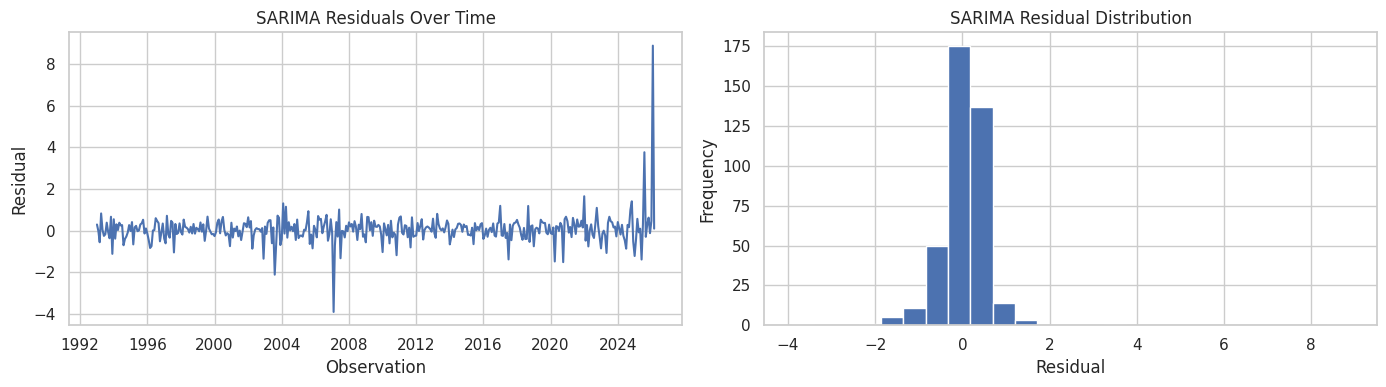

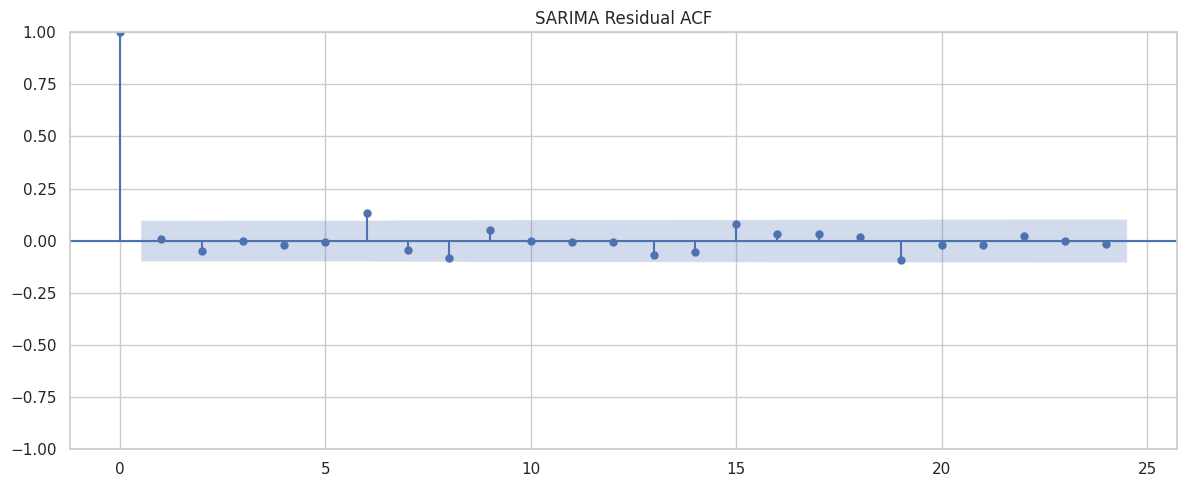

SARIMA LJUNG-BOX RESULTS


,lb_stat,lb_pvalue
12,13.276200,0.102693
24,24.726244,0.212106



Residual Mean: 0.0505
Residual Skewness: 4.7943
Residual Kurtosis: 67.6001


In [ ]:
# Step 34: SARIMA Residual Diagnostics

from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox
import matplotlib.pyplot as plt

sarima_residuals = sarima_fitted.resid

# Residual plots
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(sarima_residuals)
axes[0].set_title("SARIMA Residuals Over Time")
axes[0].set_xlabel("Observation")
axes[0].set_ylabel("Residual")

axes[1].hist(sarima_residuals, bins=25)
axes[1].set_title("SARIMA Residual Distribution")
axes[1].set_xlabel("Residual")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

# Residual autocorrelation
plot_acf(sarima_residuals, lags=24)
plt.title("SARIMA Residual ACF")
plt.tight_layout()
plt.show()

# Ljung-Box test
sarima_lb = acorr_ljungbox(
    sarima_residuals,
    lags=[12, 24],
    return_df=True,
    model_df=4
)

print("SARIMA LJUNG-BOX RESULTS")
display(sarima_lb)

print("\nResidual Mean:", round(sarima_residuals.mean(), 4))
print("Residual Skewness:", round(sarima_residuals.skew(), 4))
print("Residual Kurtosis:", round(sarima_residuals.kurtosis(), 4))

SARIMA passes the Ljung–Box checks at lags 12 and 24, but its residuals are not normally distributed and may contain influential outliers. Passing these checks does not mean every residual is random.

**Compare SARIMA and ARIMA across historical validation periods**

In [ ]:
# Step 35: ARIMA vs SARIMA Time-Series Cross-Validation

from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error
import pandas as pd
import numpy as np
import warnings

warnings.filterwarnings("ignore")

tscv = TimeSeriesSplit(n_splits=5, gap=6)

stat_cv_results = []

for fold, (train_idx, val_idx) in enumerate(
    tscv.split(X_train), start=1
):

    arima_errors = []
    sarima_errors = []
    persistence_errors = []

    for idx in val_idx:

        # Forecast origin date
        origin = model_df["observation_date"].iloc[idx]

        # Actual six-month-ahead target
        actual = y_train.iloc[idx]

        # Current inflation for persistence
        current = X_train["PPI_Inflation_YoY_pct"].iloc[idx]

        # Historical data available at origin
        history = arima_data.loc[
            :origin, "PPI_Inflation_YoY_pct"
        ].dropna()

        # ARIMA
        arima_fit = ARIMA(
            history,
            order=(1, 1, 1)
        ).fit()

        arima_forecast = float(
            arima_fit.forecast(steps=6).iloc[5]
        )

        # SARIMA
        sarima_fit = SARIMAX(
            history,
            order=(1, 1, 1),
            seasonal_order=(1, 0, 1, 12),
            enforce_stationarity=False,
            enforce_invertibility=False
        ).fit(disp=False, maxiter=200)

        sarima_forecast = float(
            sarima_fit.forecast(steps=6).iloc[5]
        )

        # Store absolute errors
        arima_errors.append(abs(actual - arima_forecast))
        sarima_errors.append(abs(actual - sarima_forecast))
        persistence_errors.append(abs(actual - current))

    stat_cv_results.append({
        "Fold": fold,
        "ARIMA MAE": np.mean(arima_errors),
        "SARIMA MAE": np.mean(sarima_errors),
        "Persistence MAE": np.mean(persistence_errors)
    })

stat_cv_df = pd.DataFrame(stat_cv_results)

print("STATISTICAL MODEL CROSS-VALIDATION")
display(stat_cv_df.round(4))

print("\nAVERAGE MAE")
print("ARIMA:", round(stat_cv_df["ARIMA MAE"].mean(), 4))
print("SARIMA:", round(stat_cv_df["SARIMA MAE"].mean(), 4))
print("Persistence:", round(stat_cv_df["Persistence MAE"].mean(), 4))

STATISTICAL MODEL CROSS-VALIDATION


,Fold,ARIMA MAE,SARIMA MAE,Persistence MAE
0,1,1.0051,0.8870,1.0080
1,2,1.8387,1.2288,1.8342
2,3,2.8086,1.5824,2.9218
3,4,0.9363,0.9880,0.9227
4,5,1.0128,0.8485,0.9486



AVERAGE MAE
ARIMA: 1.5203
SARIMA: 1.107
Persistence: 1.5271


What did we discover?
1. SARIMA outperforms ARIMA in four out of five folds.
2. SARIMA outperforms persistence in four out of five folds.
3. Its average MAE is approximately 27.5% lower than persistence.
4. Fold 4 is the exception, where persistence performs slightly better.

Our current leading model is SARIMA(1,1,1)(1,0,1,12).

**Investigate the forecast errors**

In [ ]:
# Step 36: SARIMA forecast error analysis

error_df = pd.DataFrame({
    "Forecast_Origin": pd.to_datetime(test_dates.values),
    "Actual": y_test.values,
    "SARIMA_Predicted": sarima_predictions
})

# Convert forecast origin into actual target month
error_df["Target_Date"] = (
    error_df["Forecast_Origin"]
    + pd.DateOffset(months=6)
)

error_df["Error"] = (
    error_df["Actual"] - error_df["SARIMA_Predicted"]
)

error_df["Absolute_Error"] = error_df["Error"].abs()

error_df["Year"] = error_df["Target_Date"].dt.year

# Year-wise evaluation
yearly_results = error_df.groupby("Year").agg(
    Samples=("Actual", "count"),
    MAE=("Absolute_Error", "mean"),
    Mean_Error=("Error", "mean")
).reset_index()

print("YEAR-WISE SARIMA FORECAST PERFORMANCE")
display(yearly_results.round(4))

# Overall test error
print("\nOVERALL TEST MAE:",
      round(error_df["Absolute_Error"].mean(), 4))

# Largest prediction errors
print("\nTOP 10 LARGEST FORECAST ERRORS")

display(
    error_df.sort_values(
        "Absolute_Error",
        ascending=False
    ).head(10).round(3)
)

YEAR-WISE SARIMA FORECAST PERFORMANCE


,Year,Samples,MAE,Mean_Error
0,2020,10,0.5408,-0.2848
1,2021,12,1.7221,1.7221
2,2022,12,2.4520,2.4520
3,2023,12,1.4634,0.5856
4,2024,12,1.2971,0.8686
5,2025,12,2.6511,1.8258
6,2026,9,13.8639,13.8639



OVERALL TEST MAE: 3.104

TOP 10 LARGEST FORECAST ERRORS


,Forecast_Origin,Actual,SARIMA_Predicted,Target_Date,Error,Absolute_Error,Year
75,2025-12-01,27.935,6.147,2026-06-01,21.788,21.788,2026
73,2025-10-01,25.483,3.789,2026-04-01,21.694,21.694,2026
74,2025-11-01,25.036,4.760,2026-05-01,20.276,20.276,2026
76,2026-01-01,27.135,7.133,2026-07-01,20.002,20.002,2026
72,2025-09-01,16.871,3.104,2026-03-01,13.767,13.767,2026
71,2025-08-01,15.411,3.847,2026-02-01,11.563,11.563,2026
70,2025-07-01,5.682,-1.611,2026-01-01,7.293,7.293,2026
69,2025-06-01,3.799,-2.933,2025-12-01,6.732,6.732,2025
77,2026-02-01,26.718,21.476,2026-08-01,5.242,5.242,2026
22,2021-07-01,3.959,-0.930,2022-01-01,4.890,4.890,2022


SARIMA performs reasonably well during normal inflation periods, but struggles badly when the semiconductor PPI enters an unusual inflation regime.

1. The 2026 forecasting problem
Look at these results:
- 2024 MAE: 1.2971
- 2025 MAE: 2.6511
- 2026 MAE: 13.8639
This is a substantial deterioration.

The model has learned historical inflation patterns, but it cannot anticipate an exceptionally large increase using those patterns alone.

**Quantify the 2026 regime shift**

TRAINING PERIOD


,Inflation
count,308.000
mean,-2.454
std,1.971
min,-11.538
25%,-3.520
50%,-2.065
75%,-1.166
max,1.072



TESTING PERIOD


,Inflation
count,79.000
mean,3.460
std,7.312
min,-3.237
25%,-0.038
50%,1.122
75%,3.830
max,27.935



ANNUAL INFLATION STATISTICS


,mean,std,min,max
Date,,,,
1993,0.112,0.304,-0.189,0.669
1994,-1.763,0.885,-2.844,0.190
1995,-2.206,0.982,-3.707,-1.065
1996,-3.915,0.635,-5.108,-3.232
1997,-4.169,0.486,-4.656,-3.242
1998,-2.488,0.595,-3.979,-1.846
1999,-1.870,0.357,-2.315,-1.224
2000,-1.329,0.595,-2.590,-0.446
2001,-2.832,0.960,-4.153,-1.375


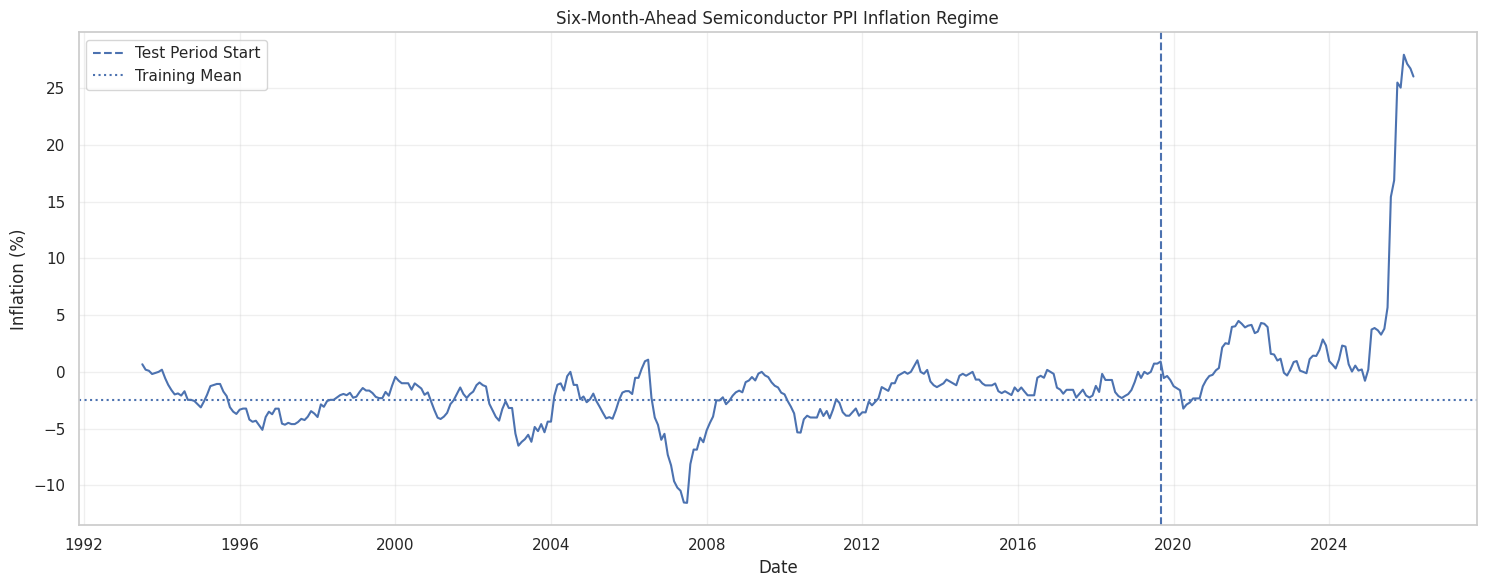

In [ ]:
# Step 37: Inflation Regime Shift Analysis

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Build target analysis dataframe
regime_df = pd.DataFrame({
    "Date": pd.to_datetime(model_df["observation_date"]),
    "Inflation": model_df["PPI_Inflation_YoY_6M_Ahead_pct"]
}).dropna()

# Separate historical training and test periods
train_regime = regime_df[
    regime_df["Date"] <= pd.to_datetime("2019-02-01")
]

test_regime = regime_df[
    regime_df["Date"] >= pd.to_datetime("2019-09-01")
]

# Compare distributions
print("TRAINING PERIOD")
display(train_regime["Inflation"].describe().round(3))

print("\nTESTING PERIOD")
display(test_regime["Inflation"].describe().round(3))

# Annual target statistics
annual_regime = regime_df.groupby(
    regime_df["Date"].dt.year
)["Inflation"].agg(
    ["mean", "std", "min", "max"]
).round(3)

print("\nANNUAL INFLATION STATISTICS")
display(annual_regime)

# Plot distribution over time
plt.figure(figsize=(15, 6))

plt.plot(
    regime_df["Date"],
    regime_df["Inflation"],
    linewidth=1.5
)

plt.axvline(
    pd.Timestamp("2019-09-01"),
    linestyle="--",
    label="Test Period Start"
)

plt.axhline(
    train_regime["Inflation"].mean(),
    linestyle=":",
    label="Training Mean"
)

plt.title("Six-Month-Ahead Semiconductor PPI Inflation Regime")
plt.xlabel("Date")
plt.ylabel("Inflation (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

. Recent period: 2025–2026
- Inflation increased sharply.
- Six-month-ahead inflation reached approximately 28%.
- This is substantially outside the historical training target range, whose maximum was approximately 1.07%.
This explains why SARIMA struggled to anticipate the latest increase.

**Structural break detection**

use the ruptures library to identify changes in the mean and variance of the inflation series.

We'll initially use the PELT algorithm with an RBF cost function.

DETECTED CHANGE POINT INDICES
[14, 234, 338, 393]

DETECTED STRUCTURAL BREAK DATES
1994-09
2013-01
2021-09


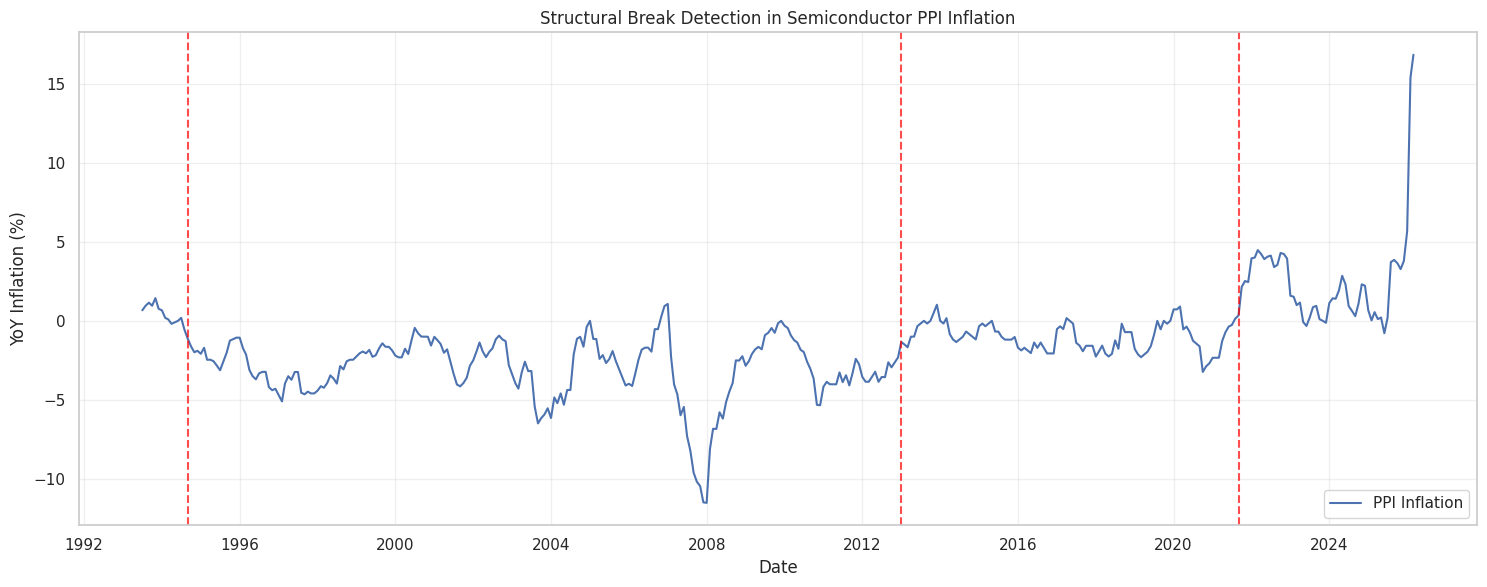

In [ ]:
# Step 38: Structural Break Detection

!pip install ruptures -q

import ruptures as rpt
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Prepare historical inflation series
break_df = model_df[
    ["observation_date", "PPI_Inflation_YoY_pct"]
].dropna().copy()

break_df["observation_date"] = pd.to_datetime(
    break_df["observation_date"]
)

# Extract series
signal = break_df[
    "PPI_Inflation_YoY_pct"
].values

# Reshape for ruptures
signal_reshaped = signal.reshape(-1, 1)

# PELT change-point detection
algorithm = rpt.Pelt(
    model="rbf",
    min_size=12,
    jump=1
)

# Penalty controls number of detected changes
breakpoints = algorithm.fit(
    signal_reshaped
).predict(pen=10)

print("DETECTED CHANGE POINT INDICES")
print(breakpoints)

# Convert indices into dates
break_dates = []

for index in breakpoints[:-1]:

    break_dates.append(
        break_df.iloc[index]["observation_date"]
    )

print("\nDETECTED STRUCTURAL BREAK DATES")

for date in break_dates:
    print(date.strftime("%Y-%m"))

# Plot
plt.figure(figsize=(15, 6))

plt.plot(
    break_df["observation_date"],
    signal,
    label="PPI Inflation"
)

for date in break_dates:

    plt.axvline(
        date,
        color="red",
        linestyle="--",
        alpha=0.7
    )

plt.title("Structural Break Detection in Semiconductor PPI Inflation")
plt.xlabel("Date")
plt.ylabel("YoY Inflation (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Why wasn't 2025–2026 detected?
There is a possible explanation:
- PELT needs observations on both sides of a potential break.
- The latest inflation spike is close to the end of our dataset.
- There may not be enough observations after the spike for the algorithm to identify a separate stable regime.
Also, our PELT analysis used pen=10. Different penalty values can produce different break dates.

**Research finding:**

The inflation series exhibits historical regime changes, and our forecasting models may benefit from adapting to more recent observations.

**Rolling-window SARIMA vs Expanding-window SARIMA**

Currently, SARIMA uses an expanding historical dataset: every forecast incorporates all available observations since 1993.

But what if older observations become less relevant after structural changes?

In [ ]:
# Step 39: Rolling vs Expanding Window SARIMA

from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error
import numpy as np
import pandas as pd
import warnings

warnings.filterwarnings("ignore")

expanding_predictions = []
rolling_predictions = []

WINDOW_SIZE = 120  # 10 years of monthly observations

for origin in forecast_origins:

    # All observations available at forecast origin
    history = arima_data.loc[
        :origin, "PPI_Inflation_YoY_pct"
    ].dropna()

    # EXPANDING WINDOW
    expanding_model = SARIMAX(
        history,
        order=(1, 1, 1),
        seasonal_order=(1, 0, 1, 12),
        enforce_stationarity=False,
        enforce_invertibility=False
    )

    expanding_fit = expanding_model.fit(
        disp=False,
        maxiter=200
    )

    expanding_forecast = expanding_fit.forecast(
        steps=6
    )

    expanding_predictions.append(
        float(expanding_forecast.iloc[5])
    )

    # ROLLING WINDOW
    rolling_history = history.tail(WINDOW_SIZE)

    rolling_model = SARIMAX(
        rolling_history,
        order=(1, 1, 1),
        seasonal_order=(1, 0, 1, 12),
        enforce_stationarity=False,
        enforce_invertibility=False
    )

    rolling_fit = rolling_model.fit(
        disp=False,
        maxiter=200
    )

    rolling_forecast = rolling_fit.forecast(
        steps=6
    )

    rolling_predictions.append(
        float(rolling_forecast.iloc[5])
    )

expanding_predictions = np.array(expanding_predictions)
rolling_predictions = np.array(rolling_predictions)

print("Both forecasting experiments completed!")

Both forecasting experiments completed!


**Compare performance**

In [ ]:
# Step 39.2: Model evaluation

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

window_results = []

models = {
    "Expanding SARIMA": expanding_predictions,
    "Rolling SARIMA (120 months)": rolling_predictions,
    "Original SARIMA": sarima_predictions,
    "Persistence": current_inflation_test.values
}

for model_name, predictions in models.items():

    window_results.append({
        "Model": model_name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(
            mean_squared_error(y_test, predictions)
        ),
        "R2": r2_score(y_test, predictions)
    })

window_results_df = pd.DataFrame(window_results)

display(
    window_results_df.sort_values("MAE").round(4)
)

,Model,MAE,RMSE,R2
1,Rolling SARIMA (120 months),2.9637,5.6766,0.3896
0,Expanding SARIMA,3.1040,5.6197,0.4017
2,Original SARIMA,3.1040,5.6197,0.4017
3,Persistence,3.3251,6.0287,0.3115


1. Rolling SARIMA has the lowest MAE.

Its MAE is approximately 4.5% lower than expanding SARIMA.

2. Expanding SARIMA has better RMSE and R².

This means rolling SARIMA reduces average absolute error, but expanding SARIMA performs slightly better when considering squared errors and overall explained variance.

3. Both outperform persistence.

This is encouraging evidence that historical seasonal modelling provides predictive value beyond simply carrying forward current inflation.

4. Older observations may be less useful.

The rolling model uses only ten years of historical data, potentially adapting better to changing economic conditions.

**Compare rolling and expanding forecast errors by year**

In [ ]:
# Step 40: Rolling vs Expanding Error Analysis

comparison_errors = pd.DataFrame({
    "Forecast_Origin": pd.to_datetime(test_dates.values),
    "Actual": y_test.values,
    "Rolling": rolling_predictions,
    "Expanding": expanding_predictions
})

comparison_errors["Target_Date"] = (
    comparison_errors["Forecast_Origin"]
    + pd.DateOffset(months=6)
)

comparison_errors["Rolling_Error"] = (
    comparison_errors["Actual"] -
    comparison_errors["Rolling"]
)

comparison_errors["Expanding_Error"] = (
    comparison_errors["Actual"] -
    comparison_errors["Expanding"]
)

comparison_errors["Year"] = (
    comparison_errors["Target_Date"].dt.year
)

# Year-wise MAE comparison
yearly_comparison = comparison_errors.groupby("Year").agg(
    Samples=("Actual", "count"),
    Rolling_MAE=("Rolling_Error", lambda x: x.abs().mean()),
    Expanding_MAE=("Expanding_Error", lambda x: x.abs().mean())
).reset_index()

print("YEAR-WISE FORECAST PERFORMANCE")

display(yearly_comparison.round(4))

# Compare latest observations
print("\nLATEST 12 FORECASTS")

display(
    comparison_errors.tail(12).round(3)
)

YEAR-WISE FORECAST PERFORMANCE


,Year,Samples,Rolling_MAE,Expanding_MAE
0,2020,10,0.8875,0.5408
1,2021,12,1.3527,1.7221
2,2022,12,2.2033,2.4520
3,2023,12,1.2694,1.4634
4,2024,12,1.0009,1.2971
5,2025,12,2.2845,2.6511
6,2026,9,14.2144,13.8639



LATEST 12 FORECASTS


,Forecast_Origin,Actual,Rolling,Expanding,Target_Date,Rolling_Error,Expanding_Error,Year
67,2025-04-01,3.658,0.543,0.076,2025-10-01,3.116,3.582,2025
68,2025-05-01,3.278,-0.534,-1.207,2025-11-01,3.813,4.485,2025
69,2025-06-01,3.799,-2.007,-2.933,2025-12-01,5.806,6.732,2025
70,2025-07-01,5.682,-0.390,-1.611,2026-01-01,6.072,7.293,2026
71,2025-08-01,15.411,4.164,3.847,2026-02-01,11.247,11.563,2026
72,2025-09-01,16.871,3.382,3.104,2026-03-01,13.489,13.767,2026
73,2025-10-01,25.483,4.058,3.789,2026-04-01,21.425,21.694,2026
74,2025-11-01,25.036,4.365,4.760,2026-05-01,20.671,20.276,2026
75,2025-12-01,27.935,5.701,6.147,2026-06-01,22.233,21.788,2026
76,2026-01-01,27.135,6.286,7.133,2026-07-01,20.848,20.002,2026


SARIMA improves forecasting in several historical periods, but it does not solve the 2026 inflation surge.

**Research interpretation:**

Both models struggle to anticipate the initial inflation surge. The rolling model reacts more aggressively after observing newer inflation values, while the expanding model provides a more conservative forecast.

**Investigate the 2026 forecast errors**

In [ ]:
# Step 41: Normal vs High-Inflation Regime Evaluation

comparison_errors["Regime"] = np.where(
    comparison_errors["Target_Date"].dt.year >= 2026,
    "2026 High-Inflation Period",
    "2020-2025 Historical Period"
)

regime_performance = comparison_errors.groupby(
    "Regime"
).agg(
    Samples=("Actual", "count"),
    Rolling_MAE=("Rolling_Error", lambda x: x.abs().mean()),
    Expanding_MAE=("Expanding_Error", lambda x: x.abs().mean()),
    Rolling_Bias=("Rolling_Error", "mean"),
    Expanding_Bias=("Expanding_Error", "mean")
).reset_index()

display(regime_performance.round(4))

,Regime,Samples,Rolling_MAE,Expanding_MAE,Rolling_Bias,Expanding_Bias
0,2020-2025 Historical Period,70,1.5172,1.7205,0.7981,1.2372
1,2026 High-Inflation Period,9,14.2144,13.8639,14.2144,13.8639


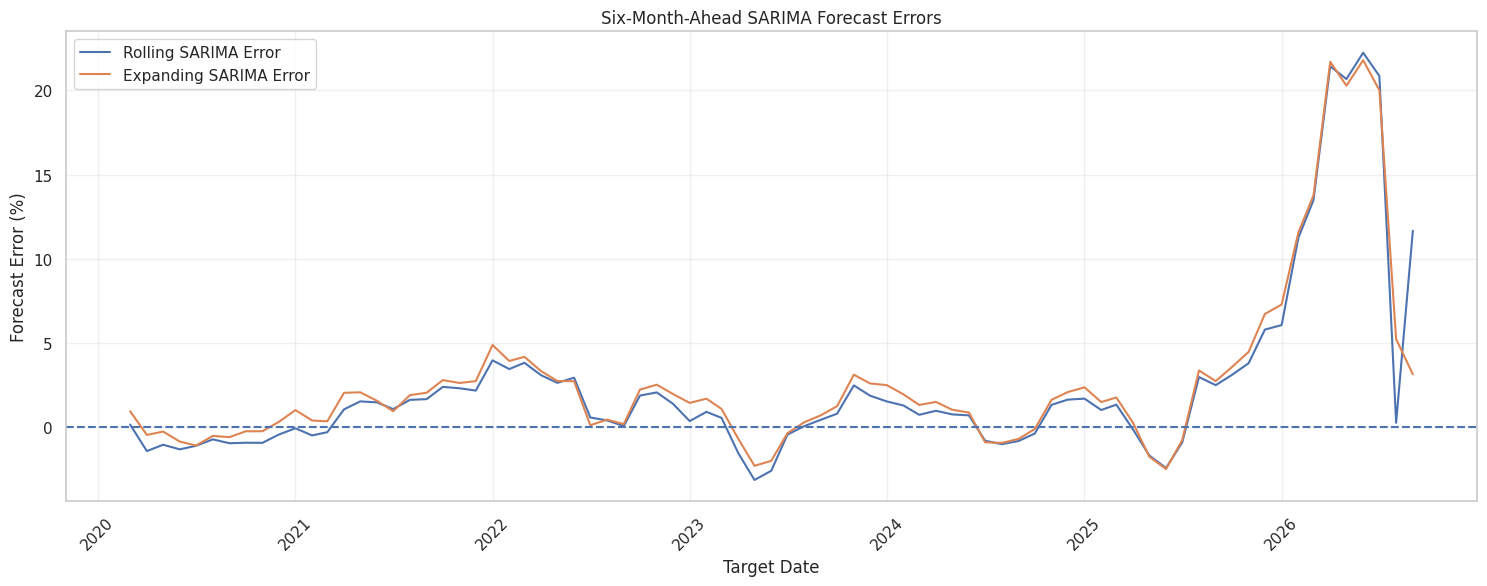

In [ ]:
# Compare forecast errors by target date

plt.figure(figsize=(15, 6))

plt.plot(
    comparison_errors["Target_Date"],
    comparison_errors["Rolling_Error"],
    label="Rolling SARIMA Error"
)

plt.plot(
    comparison_errors["Target_Date"],
    comparison_errors["Expanding_Error"],
    label="Expanding SARIMA Error"
)

plt.axhline(0, linestyle="--")

plt.title("Six-Month-Ahead SARIMA Forecast Errors")
plt.xlabel("Target Date")
plt.ylabel("Forecast Error (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Both SARIMA models perform reasonably well during historical conditions, but both struggle significantly during the 2026 inflation surge.

Find the best rolling-window length

In [ ]:
# Step 42: Rolling SARIMA Window Optimization
# Use training data only for model selection

from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.model_selection import TimeSeriesSplit
import numpy as np
import pandas as pd
import warnings

warnings.filterwarnings("ignore")

window_sizes = [60, 84, 120, 180]

tscv = TimeSeriesSplit(n_splits=5, gap=6)

window_cv_results = []

for window_size in window_sizes:

    fold_errors = []

    for fold, (train_idx, val_idx) in enumerate(
        tscv.split(X_train), start=1
    ):

        predictions = []
        actuals = []

        for idx in val_idx:

            origin = model_df[
                "observation_date"
            ].iloc[train_idx[-1]]

            # Use historical data available at each validation origin
            forecast_origin = model_df[
                "observation_date"
            ].iloc[idx]

            history = arima_data.loc[
                :forecast_origin,
                "PPI_Inflation_YoY_pct"
            ].dropna()

            # Apply rolling window
            history = history.tail(window_size)

            model = SARIMAX(
                history,
                order=(1, 1, 1),
                seasonal_order=(1, 0, 1, 12),
                enforce_stationarity=False,
                enforce_invertibility=False
            )

            fitted = model.fit(
                disp=False,
                maxiter=200
            )

            forecast = fitted.forecast(steps=6)

            predictions.append(float(forecast.iloc[5]))
            actuals.append(float(y_train.iloc[idx]))

        fold_errors.append(
            np.mean(np.abs(np.array(actuals) - np.array(predictions)))
        )

    window_cv_results.append({
        "Window_Months": window_size,
        "Mean_CV_MAE": np.mean(fold_errors),
        "Std_CV_MAE": np.std(fold_errors)
    })

window_cv_df = pd.DataFrame(window_cv_results)

display(
    window_cv_df.sort_values("Mean_CV_MAE").round(4)
)

,Window_Months,Mean_CV_MAE,Std_CV_MAE
2,120,1.1349,0.2900
3,180,1.1393,0.2486
1,84,1.1741,0.3971
0,60,1.2998,0.4720


**Compare 120 and 180 months fold by fold**

In [ ]:
# Step 43: Fold-wise comparison of selected windows

from statsmodels.tsa.statespace.sarimax import SARIMAX
import numpy as np
import pandas as pd
import warnings

warnings.filterwarnings("ignore")

selected_windows = [120, 180]

tscv = TimeSeriesSplit(n_splits=5, gap=6)

fold_comparison = []

for window_size in selected_windows:

    for fold, (train_idx, val_idx) in enumerate(
        tscv.split(X_train), start=1
    ):

        predictions = []
        actuals = []

        for idx in val_idx:

            forecast_origin = pd.to_datetime(
                model_df["observation_date"].iloc[idx]
            )

            history = arima_data.loc[
                :forecast_origin,
                "PPI_Inflation_YoY_pct"
            ].dropna().tail(window_size)

            model = SARIMAX(
                history,
                order=(1, 1, 1),
                seasonal_order=(1, 0, 1, 12),
                enforce_stationarity=False,
                enforce_invertibility=False
            )

            fitted = model.fit(
                disp=False,
                maxiter=200
            )

            forecast = fitted.forecast(steps=6)

            predictions.append(float(forecast.iloc[5]))
            actuals.append(float(y_train.iloc[idx]))

        fold_mae = np.mean(
            np.abs(np.array(actuals) - np.array(predictions))
        )

        fold_comparison.append({
            "Window": window_size,
            "Fold": fold,
            "MAE": fold_mae
        })

fold_comparison_df = pd.DataFrame(fold_comparison)

display(
    fold_comparison_df.pivot(
        index="Fold",
        columns="Window",
        values="MAE"
    ).round(4)
)

Window,120,180
Fold,,
1,0.8870,0.8870
2,1.2480,1.2288
3,1.6467,1.5836
4,1.0282,1.0105
5,0.8646,0.9868


Interpretation
- 180 months performs better in three folds.
- 120 months performs better in one fold.
- One fold is tied.
- 120 months has the lowest overall average MAE.
- 180 months has slightly lower variability.
The difference is small, so we shouldn't claim that 120 months is definitively superior.

Our current model selection
Primary candidate
Rolling SARIMA (120 months)
1.1349
Mean chronological cross-validation MAE

Sensitivity benchmark

Rolling SARIMA (180 months)
1.1393
Mean chronological cross-validation MAE

**Final research robustness check**

In [ ]:
# Step 45: SARIMA vs Persistence improvement

cv_comparison = pd.DataFrame({
    "Fold": [1, 2, 3, 4, 5],
    "SARIMA_120_MAE": [0.8870, 1.2480, 1.6467, 1.0282, 0.8646],
    "Persistence_MAE": [1.0080, 1.8342, 2.9218, 0.9227, 0.9486]
})

cv_comparison["Improvement"] = (
    cv_comparison["Persistence_MAE"]
    - cv_comparison["SARIMA_120_MAE"]
)

cv_comparison["Improvement_Percent"] = (
    cv_comparison["Improvement"]
    / cv_comparison["Persistence_MAE"]
) * 100

display(cv_comparison.round(4))

print(
    "\nAverage MAE improvement:",
    round(cv_comparison["Improvement_Percent"].mean(), 2),
    "%"
)

print(
    "Folds where SARIMA wins:",
    (cv_comparison["Improvement"] > 0).sum(),
    "out of 5"
)

,Fold,SARIMA_120_MAE,Persistence_MAE,Improvement,Improvement_Percent
0,1,0.8870,1.0080,0.1210,12.0040
1,2,1.2480,1.8342,0.5862,31.9594
2,3,1.6467,2.9218,1.2751,43.6409
3,4,1.0282,0.9227,-0.1055,-11.4338
4,5,0.8646,0.9486,0.0840,8.8552



Average MAE improvement: 17.01 %
Folds where SARIMA wins: 4 out of 5


**stop adding random models and move towards making this a research-quality forecasting framework.**

- SARIMA beats persistence in 4 out of 5 validation folds.
- Average MAE improvement: 17.01%.
- 120-month rolling SARIMA has the lowest cross-validation MAE.
- However, the model struggles with the 2026 inflation surge.
This gives us a meaningful research question:

Can a regime-aware macroeconomic forecasting framework improve six-month-ahead semiconductor PPI inflation prediction during structural changes?

**Statistical significance of our forecasting improvement**

In [ ]:
# Step 46: Paired Forecast Error Significance Test

from scipy.stats import wilcoxon
import numpy as np
import pandas as pd

# Recreate paired validation errors using
# the existing chronological CV forecasts.
# Use the five-fold predictions, not the test set.

sarima_errors = []
persistence_errors = []

tscv = TimeSeriesSplit(n_splits=5, gap=6)

for fold, (train_idx, val_idx) in enumerate(
    tscv.split(X_train), start=1
):

    sarima_fold_predictions = []
    persistence_fold_predictions = []
    actual_fold_values = []

    for idx in val_idx:

        origin = pd.to_datetime(
            model_df["observation_date"].iloc[idx]
        )

        history = arima_data.loc[
            :origin, "PPI_Inflation_YoY_pct"
        ].dropna().tail(120)

        fitted = SARIMAX(
            history,
            order=(1, 1, 1),
            seasonal_order=(1, 0, 1, 12),
            enforce_stationarity=False,
            enforce_invertibility=False
        ).fit(disp=False, maxiter=200)

        prediction = fitted.forecast(steps=6).iloc[5]

        sarima_fold_predictions.append(float(prediction))

        persistence_fold_predictions.append(
            float(X_train["PPI_Inflation_YoY_pct"].iloc[idx])
        )

        actual_fold_values.append(float(y_train.iloc[idx]))

    sarima_errors.extend(
        np.abs(
            np.array(actual_fold_values) -
            np.array(sarima_fold_predictions)
        )
    )

    persistence_errors.extend(
        np.abs(
            np.array(actual_fold_values) -
            np.array(persistence_fold_predictions)
        )
    )

# Paired error comparison
sarima_errors = np.array(sarima_errors)
persistence_errors = np.array(persistence_errors)

difference = persistence_errors - sarima_errors

# Wilcoxon signed-rank test
statistic, p_value = wilcoxon(
    persistence_errors,
    sarima_errors,
    alternative="greater"
)

print("PAIRED FORECAST ERROR TEST")
print("--------------------------")

print("Mean SARIMA absolute error:",
      round(sarima_errors.mean(), 4))

print("Mean Persistence absolute error:",
      round(persistence_errors.mean(), 4))

print("Mean improvement:",
      round(difference.mean(), 4))

print("Wilcoxon statistic:", round(statistic, 4))
print("P-value:", round(p_value, 6))

if p_value < 0.05:
    print("Evidence of lower SARIMA errors at 5% significance.")
else:
    print("Insufficient evidence of lower SARIMA errors at 5% significance.")

PAIRED FORECAST ERROR TEST
--------------------------
Mean SARIMA absolute error: 1.1349
Mean Persistence absolute error: 1.5271
Mean improvement: 0.3922
Wilcoxon statistic: 21685.0
P-value: 3e-06
Evidence of lower SARIMA errors at 5% significance.


SARIMA has demonstrated lower absolute forecasting errors than persistence across the historical validation observations.

Interpretation
The p-value is below 0.05, so we reject the null hypothesis under the assumptions of this test.

There is evidence that SARIMA produces lower absolute errors than persistence.

The relative improvement is:

\[
\frac{1.5271-1.1349}{1.5271}\times100
=25.68\%
\]

Correction to our earlier reporting: 17.01% was the unweighted average of the five fold-wise percentage improvements. The 25.68% figure is the improvement calculated from the pooled mean errors. For the paper, use the pooled figure and clearly explain the aggregation method.

One caveat: monthly six-month-ahead errors overlap, so they are not independent. The ordinary Wilcoxon p-value may overstate the strength of statistical evidence. We'll need a dependence-aware test before claiming definitive significance.

**Move to SARIMAX: incorporate economic indicators**

Our SARIMA model uses historical semiconductor PPI inflation. SARIMAX allows us to incorporate external variables.

Research **hypothesis**

Adding economic indicators may improve six-month-ahead semiconductor PPI inflation forecasts compared with a univariate SARIMA model.

**Prepare the exogenous dataset**

In [ ]:
# Step 47.1: Inspect SARIMAX input variables

print("Available columns:")
print(model_df.columns.tolist())

print("\nDataset date range:")
print(model_df["observation_date"].min())
print(model_df["observation_date"].max())

print("\nExogenous variable missing values:")

exog_columns = [
    "PCOPPUSDM",
    "PALUMUSDM",
    "PNICKUSDM",
    "CAPUTLG3344S",
    "IPG3344S"
]

display(
    model_df[exog_columns].isnull().sum()
)

print("\nExogenous variable preview:")
display(
    model_df[
        ["observation_date"] + exog_columns
    ].tail(10)
)

Available columns:
['observation_date', 'PCU3344133441', 'PCOPPUSDM', 'PALUMUSDM', 'PNICKUSDM', 'CAPUTLG3344S', 'IPG3344S', 'PPI_Inflation_YoY_pct', 'PPI_Inflation_YoY_6M_Ahead_pct', 'PCOPPUSDM_MoM_pct', 'PALUMUSDM_MoM_pct', 'PNICKUSDM_MoM_pct', 'IPG3344S_MoM_pct', 'PCOPPUSDM_YoY_pct', 'PALUMUSDM_YoY_pct', 'PNICKUSDM_YoY_pct', 'IPG3344S_YoY_pct', 'Capacity_Change', 'PPI_Inflation_YoY_pct_Lag_1', 'PPI_Inflation_YoY_pct_Lag_2', 'PPI_Inflation_YoY_pct_Lag_3', 'PPI_Inflation_YoY_pct_Lag_6', 'PCOPPUSDM_MoM_pct_Lag_1', 'PCOPPUSDM_MoM_pct_Lag_2', 'PCOPPUSDM_MoM_pct_Lag_3', 'PCOPPUSDM_MoM_pct_Lag_6', 'PALUMUSDM_MoM_pct_Lag_1', 'PALUMUSDM_MoM_pct_Lag_2', 'PALUMUSDM_MoM_pct_Lag_3', 'PALUMUSDM_MoM_pct_Lag_6', 'PNICKUSDM_MoM_pct_Lag_1', 'PNICKUSDM_MoM_pct_Lag_2', 'PNICKUSDM_MoM_pct_Lag_3', 'PNICKUSDM_MoM_pct_Lag_6', 'IPG3344S_MoM_pct_Lag_1', 'IPG3344S_MoM_pct_Lag_2', 'IPG3344S_MoM_pct_Lag_3', 'IPG3344S_MoM_pct_Lag_6', 'Capacity_Change_Lag_1', 'Capacity_Change_Lag_2', 'Capacity_Change_Lag_3', 'Capa

,0
PCOPPUSDM,0
PALUMUSDM,0
PNICKUSDM,0
CAPUTLG3344S,0
IPG3344S,0



Exogenous variable preview:


,observation_date,PCOPPUSDM,PALUMUSDM,PNICKUSDM,CAPUTLG3344S,IPG3344S
383,2025-06-01,9835.068095,2525.959048,15003.107619,76.2240,163.1741
384,2025-07-01,9770.580435,2606.370870,15034.018696,78.8573,171.5555
385,2025-08-01,9671.875714,2598.735714,14948.056667,76.5233,169.1970
386,2025-09-01,9994.773182,2654.479091,15103.183636,73.7232,165.6670
387,2025-10-01,10739.918261,2793.086957,15092.114348,74.0524,169.1163
388,2025-11-01,10812.028000,2819.061500,14670.768500,73.1444,169.7424
389,2025-12-01,11790.964091,2875.897727,14879.030000,72.3377,170.5402
390,2026-01-01,12986.606818,3133.982727,17710.863636,74.1644,176.7104
391,2026-02-01,12951.345000,3065.188500,17173.103500,72.9787,176.1804
392,2026-03-01,12528.709545,3372.952727,17076.292727,71.0962,173.6932


**Build a leakage-safe SARIMAX dataset**

In [ ]:
# Step 47.2: Prepare SARIMAX dataset

import pandas as pd
import numpy as np

sarimax_df = model_df.copy()

sarimax_df["observation_date"] = pd.to_datetime(
    sarimax_df["observation_date"]
)

sarimax_df = sarimax_df.sort_values(
    "observation_date"
).reset_index(drop=True)

# External indicators available at forecast origin
exog_columns = [
    "PCOPPUSDM",
    "PALUMUSDM",
    "PNICKUSDM",
    "CAPUTLG3344S",
    "IPG3344S"
]

# Target: six-month-ahead PPI inflation
target_column = "PPI_Inflation_YoY_6M_Ahead_pct"

# Keep required columns
sarimax_df = sarimax_df[
    ["observation_date", target_column] + exog_columns
].dropna().copy()

# Monthly date index
sarimax_df = sarimax_df.set_index(
    "observation_date"
).asfreq("MS")

print("SARIMAX dataset shape:", sarimax_df.shape)

print("\nMissing values:")
print(sarimax_df.isnull().sum())

print("\nDate range:")
print(sarimax_df.index.min(), "to", sarimax_df.index.max())

SARIMAX dataset shape: (393, 6)

Missing values:
PPI_Inflation_YoY_6M_Ahead_pct    0
PCOPPUSDM                         0
PALUMUSDM                         0
PNICKUSDM                         0
CAPUTLG3344S                      0
IPG3344S                          0
dtype: int64

Date range:
1993-07-01 00:00:00 to 2026-03-01 00:00:00


**Important: split the dataset**

In [ ]:
# Step 47.3: Chronological split

train_end = pd.Timestamp("2019-02-01")
test_start = pd.Timestamp("2019-09-01")

train_data = sarimax_df.loc[:train_end].copy()

test_data = sarimax_df.loc[test_start:].copy()

print("Training samples:", len(train_data))
print("Testing samples:", len(test_data))

print("\nTraining period:")
print(train_data.index.min(), "to", train_data.index.max())

print("\nTesting period:")
print(test_data.index.min(), "to", test_data.index.max())

Training samples: 308
Testing samples: 79

Training period:
1993-07-01 00:00:00 to 2019-02-01 00:00:00

Testing period:
2019-09-01 00:00:00 to 2026-03-01 00:00:00


*Fit the first SARIMAX model*

In [ ]:
# Step 47.4: SARIMAX model

from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

# Separate target and external variables
y_sarimax_train = train_data[target_column]

X_sarimax_train = train_data[exog_columns]

# Standardize using training data only
scaler = StandardScaler()

X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_sarimax_train),
    index=X_sarimax_train.index,
    columns=exog_columns
)

# Train SARIMAX
sarimax_model = SARIMAX(
    y_sarimax_train,
    exog=X_train_scaled,
    order=(1, 1, 1),
    seasonal_order=(1, 0, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
)

sarimax_fitted = sarimax_model.fit(
    disp=False,
    maxiter=300
)

print(sarimax_fitted.summary())

                                     SARIMAX Results                                      
Dep. Variable:     PPI_Inflation_YoY_6M_Ahead_pct   No. Observations:                  308
Model:             SARIMAX(1, 1, 1)x(1, 0, 1, 12)   Log Likelihood                -204.859
Date:                            Sun, 01 Nov 2026   AIC                            429.719
Time:                                    09:41:14   BIC                            466.521
Sample:                                07-01-1993   HQIC                           444.458
                                     - 02-01-2019                                         
Covariance Type:                              opg                                         
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
PCOPPUSDM       -0.0011      0.142     -0.007      0.994      -0.279       0.277
PALUMUSDM        0.0130      

**prepare the correct SARIMAX dataset**

In [ ]:
# STEP 44.1 — Prepare correctly aligned SARIMAX data

target_column = "PPI_Inflation_YoY_pct"

exog_columns = [
    "PCOPPUSDM",
    "PALUMUSDM",
    "PNICKUSDM",
    "CAPUTLG3344S",
    "IPG3344S"
]

sarimax_actual_df = model_df[
    ["observation_date", target_column] + exog_columns
].copy()

sarimax_actual_df["observation_date"] = pd.to_datetime(
    sarimax_actual_df["observation_date"]
)

sarimax_actual_df = (
    sarimax_actual_df
    .set_index("observation_date")
    .sort_index()
)

sarimax_actual_df = sarimax_actual_df.asfreq("MS").dropna()

print("Dataset shape:", sarimax_actual_df.shape)
print("\nDate range:")
print(sarimax_actual_df.index.min(), "to", sarimax_actual_df.index.max())

print("\nMissing values:")
print(sarimax_actual_df.isnull().sum())

print("\nLatest observations:")
display(sarimax_actual_df.tail())

Dataset shape: (393, 6)

Date range:
1993-07-01 00:00:00 to 2026-03-01 00:00:00

Missing values:
PPI_Inflation_YoY_pct    0
PCOPPUSDM                0
PALUMUSDM                0
PNICKUSDM                0
CAPUTLG3344S             0
IPG3344S                 0
dtype: int64

Latest observations:


,PPI_Inflation_YoY_pct,PCOPPUSDM,PALUMUSDM,PNICKUSDM,CAPUTLG3344S,IPG3344S
observation_date,,,,,,
2025-11-01,3.278132,10812.028000,2819.061500,14670.768500,73.1444,169.7424
2025-12-01,3.799211,11790.964091,2875.897727,14879.030000,72.3377,170.5402
2026-01-01,5.681974,12986.606818,3133.982727,17710.863636,74.1644,176.7104
2026-02-01,15.410711,12951.345000,3065.188500,17173.103500,72.9787,176.1804
2026-03-01,16.871202,12528.709545,3372.952727,17076.292727,71.0962,173.6932


**Define the forecasting strategy**

For a genuine six-month-ahead SARIMAX forecast, we need to account for one limitation:

At forecast origin \(t\), we know the historical copper, aluminum, nickel, capacity and production values up to \(t\), but we do not know their actual values from \(t+1\) to \(t+6\).

Therefore, we'll compare two approaches:
1. SARIMA baseline: Forecast actual inflation six months ahead without external indicators.
2. SARIMAX with forecasted exogenous variables: Forecast the five external indicators separately, then use those forecasts as SARIMAX inputs.

We'll use the same six-month forecast horizon and chronological test period (September 2019–March 2026)

Set up the baseline

In [ ]:
# STEP 44.3 — Prepare SARIMA training and testing data

target_column = "PPI_Inflation_YoY_pct"

train_end = "2019-02-01"
test_start = "2019-09-01"

y = sarimax_actual_df[target_column]

y_train = y.loc[:train_end]
y_test = y.loc[test_start:]

print("Training samples:", len(y_train))
print("Testing samples:", len(y_test))

print("\nTraining period:")
print(y_train.index.min(), "to", y_train.index.max())

print("\nTesting period:")
print(y_test.index.min(), "to", y_test.index.max())

Training samples: 308
Testing samples: 79

Training period:
1993-07-01 00:00:00 to 2019-02-01 00:00:00

Testing period:
2019-09-01 00:00:00 to 2026-03-01 00:00:00


**Build the six-month-ahead SARIMA baseline**

In [ ]:
# STEP 44.4 — Six-month-ahead rolling SARIMA forecast

from statsmodels.tsa.statespace.sarimax import SARIMAX
import pandas as pd
import numpy as np

order = (1, 1, 1)
seasonal_order = (1, 0, 1, 12)

forecast_horizon = 6
sarima_predictions = []

for origin in y_test.index:

    # Use only data available at the forecast origin
    available_data = y.loc[:origin]

    # Fit SARIMA
    model = SARIMAX(
        available_data,
        order=order,
        seasonal_order=seasonal_order,
        enforce_stationarity=False,
        enforce_invertibility=False
    )

    fitted_model = model.fit(disp=False)

    # Forecast six months ahead
    forecast = fitted_model.forecast(steps=forecast_horizon)

    # Select the sixth-month forecast
    predicted_value = forecast.iloc[-1]

    target_date = origin + pd.DateOffset(months=forecast_horizon)

    # Keep only forecasts with an actual observation
    if target_date in y.index:
        sarima_predictions.append({
            "Forecast_Origin": origin,
            "Target_Date": target_date,
            "Actual": y.loc[target_date],
            "Predicted": predicted_value
        })

sarima_results = pd.DataFrame(sarima_predictions)

print("Forecasts generated:", len(sarima_results))
display(sarima_results.head())


Forecasts generated: 73


,Forecast_Origin,Target_Date,Actual,Predicted
0,2019-09-01,2020-03-01,0.907441,-0.017945
1,2019-10-01,2020-04-01,-0.543478,-0.068832
2,2019-11-01,2020-05-01,-0.362976,-0.082660
3,2019-12-01,2020-06-01,-0.723327,0.159528
4,2020-01-01,2020-07-01,-1.263538,-0.145825


- Forecast origin: September 2020? No — September 2019.
- Target date: March 2020.
- Actual inflation: 0.9074%.
- Predicted inflation: -0.0179%.
This confirms that we're forecasting six months beyond each origin.

Why 73 instead of 79?

The final six forecast origins don't have six months of actual future inflation available in the dataset. So they are correctly excluded.

**Evaluate the model**

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

actual = sarima_results["Actual"]
predicted = sarima_results["Predicted"]

mae = mean_absolute_error(actual, predicted)
rmse = np.sqrt(mean_squared_error(actual, predicted))
r2 = r2_score(actual, predicted)

print("SIX-MONTH-AHEAD SARIMA PERFORMANCE")
print("-----------------------------------")
print(f"Observations : {len(sarima_results)}")
print(f"MAE          : {mae:.4f}")
print(f"RMSE         : {rmse:.4f}")
print(f"R²           : {r2:.4f}")

SIX-MONTH-AHEAD SARIMA PERFORMANCE
-----------------------------------
Observations : 73
MAE          : 2.0993
RMSE         : 3.1258
R²           : 0.0510


**Visualize actual vs predicted inflation**

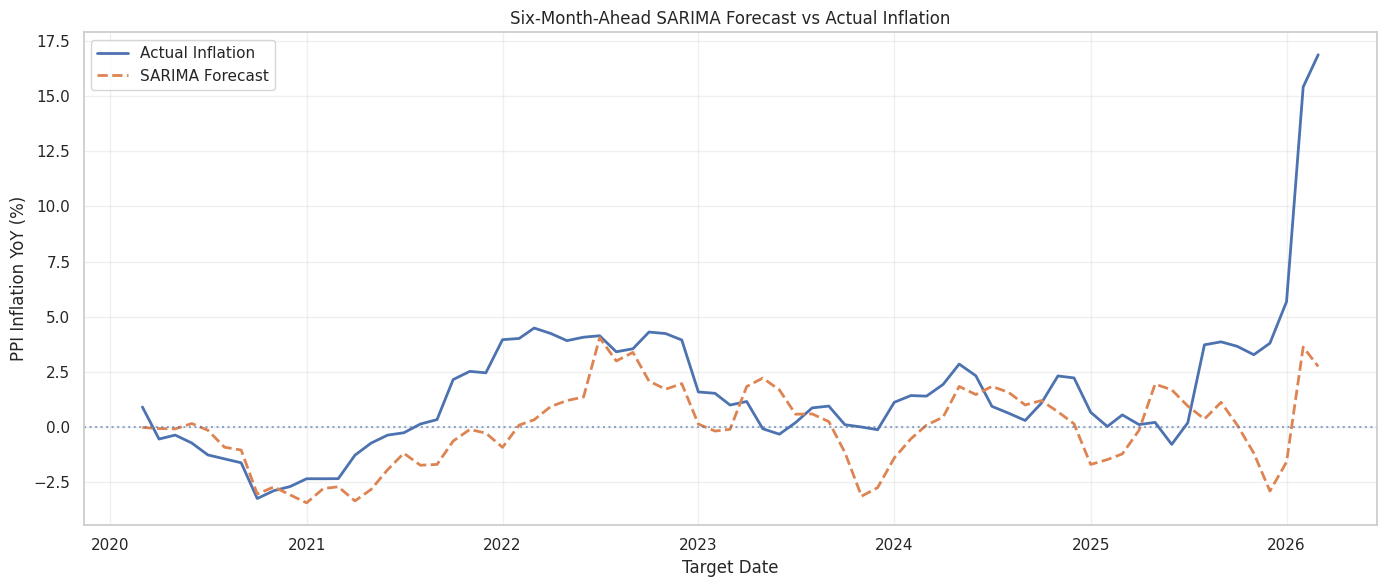

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    sarima_results["Target_Date"],
    sarima_results["Actual"],
    label="Actual Inflation",
    linewidth=2
)

plt.plot(
    sarima_results["Target_Date"],
    sarima_results["Predicted"],
    label="SARIMA Forecast",
    linestyle="--",
    linewidth=2
)

plt.axhline(0, linestyle=":", alpha=0.6)

plt.title("Six-Month-Ahead SARIMA Forecast vs Actual Inflation")
plt.xlabel("Target Date")
plt.ylabel("PPI Inflation YoY (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

1. Graph interpretation
Major forecasting limitation identified
2020–2021:
- The model captures the initial decline and recovery reasonably well.
- Some differences exist between actual and predicted values.
2022–2025:
- The model follows the general inflation movement.
- It misses some peaks and fluctuations.
- Forecasts are smoother than actual inflation.
2026:
- Actual inflation rises sharply, reaching approximately 16.87%.
- The model predicts only around 2.7–3.6%.
- This indicates substantial underprediction during the sudden inflation surge.
2. Research interpretation
This suggests that historical inflation patterns alone are insufficient to anticipate sudden structural changes.

Potential explanations to investigate include:
- Structural breaks in semiconductor manufacturing prices.
- Sudden changes in raw material prices.
- Manufacturing supply-demand imbalances.
- Changes in the relationship between input costs and producer prices.
These are possible explanations, not established causes.

**quantify forecast bias**

In [ ]:
# STEP 44.7 — Forecast error and bias analysis

sarima_results["Error"] = (
    sarima_results["Actual"] - sarima_results["Predicted"]
)

sarima_results["Absolute_Error"] = (
    sarima_results["Error"].abs()
)

print("FORECAST ERROR ANALYSIS")
print("-----------------------")

print("Mean Error (Bias):",
      round(sarima_results["Error"].mean(), 4))

print("Mean Absolute Error:",
      round(sarima_results["Absolute_Error"].mean(), 4))

print("\nLargest forecasting errors:")

display(
    sarima_results.nlargest(10, "Absolute_Error")[
        ["Forecast_Origin", "Target_Date",
         "Actual", "Predicted", "Error"]
    ]
)

FORECAST ERROR ANALYSIS
-----------------------
Mean Error (Bias): 1.6271
Mean Absolute Error: 2.0993

Largest forecasting errors:


,Forecast_Origin,Target_Date,Actual,Predicted,Error
72,2025-09-01,2026-03-01,16.871202,2.745986,14.125217
71,2025-08-01,2026-02-01,15.410711,3.626800,11.783912
70,2025-07-01,2026-01-01,5.681974,-1.585306,7.267281
69,2025-06-01,2025-12-01,3.799211,-2.901078,6.700289
22,2021-07-01,2022-01-01,3.959410,-0.919695,4.879105
68,2025-05-01,2025-11-01,3.278132,-1.183932,4.462064
24,2021-09-01,2022-03-01,4.486188,0.331570,4.154618
23,2021-08-01,2022-02-01,4.014760,0.089458,3.925302
67,2025-04-01,2025-10-01,3.658431,0.095273,3.563159
65,2025-02-01,2025-08-01,3.727345,0.363771,3.363575


we can report this as evidence of a limitation in historical inflation-only forecasting, not proof of the cause of the inflation surge.

**SARIMAX with external economic indicators**

Now we'll test whether these five indicators improve the forecasts:
1. Copper prices
2. Aluminum prices
3. Nickel prices
4. Semiconductor capacity utilization
5. Semiconductor industrial production
Our approach: At each forecast origin, we'll fit SARIMAX using historical inflation and historical indicators. For the next six months, we'll assume each external indicator remains at its latest observed value. This is a simple persistence assumption, not a claim that future values are known.

In [ ]:
# STEP 45.1 — Six-month-ahead rolling SARIMAX with external indicators

from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.preprocessing import StandardScaler
import warnings
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

exog_columns = [
    "PCOPPUSDM",
    "PALUMUSDM",
    "PNICKUSDM",
    "CAPUTLG3344S",
    "IPG3344S"
]

sarimax_predictions = []

for origin in y_test.index:

    target_date = origin + pd.DateOffset(months=6)

    if target_date not in y.index:
        continue

    # Historical data available at forecast origin
    historical_y = y.loc[:origin]
    historical_exog = sarimax_actual_df.loc[
        :origin, exog_columns
    ]

    # Scale indicators using historical data only
    scaler = StandardScaler()

    historical_exog_scaled = scaler.fit_transform(
        historical_exog
    )

    # Assume future indicators remain at their latest observed values
    future_exog = pd.DataFrame(
        np.repeat(
            historical_exog_scaled[-1].reshape(1, -1),
            6,
            axis=0
        ),
        columns=exog_columns
    )

    # Fit SARIMAX
    model = SARIMAX(
        historical_y,
        exog=historical_exog_scaled,
        order=(1, 1, 1),
        seasonal_order=(1, 0, 1, 12),
        enforce_stationarity=False,
        enforce_invertibility=False
    )

    fitted_model = model.fit(
        disp=False,
        maxiter=200
    )

    # Six-month forecast
    forecast = fitted_model.forecast(
        steps=6,
        exog=future_exog
    )

    sarimax_predictions.append({
        "Forecast_Origin": origin,
        "Target_Date": target_date,
        "Actual": y.loc[target_date],
        "Predicted": forecast.iloc[-1]
    })

sarimax_results = pd.DataFrame(sarimax_predictions)

print("SARIMAX forecasts generated:", len(sarimax_results))
display(sarimax_results.head())

SARIMAX forecasts generated: 73


,Forecast_Origin,Target_Date,Actual,Predicted
0,2019-09-01,2020-03-01,0.907441,0.486956
1,2019-10-01,2020-04-01,-0.543478,0.367552
2,2019-11-01,2020-05-01,-0.362976,0.482612
3,2019-12-01,2020-06-01,-0.723327,0.830188
4,2020-01-01,2020-07-01,-1.263538,0.476147


**Evaluate SARIMAX performance**

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

actual = sarimax_results["Actual"]
predicted = sarimax_results["Predicted"]

sarimax_mae = mean_absolute_error(actual, predicted)
sarimax_rmse = np.sqrt(mean_squared_error(actual, predicted))
sarimax_r2 = r2_score(actual, predicted)
sarimax_bias = np.mean(actual - predicted)

print("SIX-MONTH-AHEAD SARIMAX PERFORMANCE")
print("-----------------------------------")
print("Observations:", len(sarimax_results))
print(f"MAE  : {sarimax_mae:.4f}")
print(f"RMSE : {sarimax_rmse:.4f}")
print(f"R²   : {sarimax_r2:.4f}")
print(f"Bias : {sarimax_bias:.4f}")

SIX-MONTH-AHEAD SARIMAX PERFORMANCE
-----------------------------------
Observations: 73
MAE  : 1.9982
RMSE : 2.9764
R²   : 0.1396
Bias : 1.1941


In [ ]:
comparison = pd.DataFrame({
    "Model": ["SARIMA", "SARIMAX"],
    "MAE": [
        mean_absolute_error(
            sarima_results["Actual"],
            sarima_results["Predicted"]
        ),
        sarimax_mae
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(
            sarima_results["Actual"],
            sarima_results["Predicted"]
        )),
        sarimax_rmse
    ],
    "R2": [
        r2_score(
            sarima_results["Actual"],
            sarima_results["Predicted"]
        ),
        sarimax_r2
    ],
    "Bias": [
        sarima_results["Error"].mean(),
        sarimax_bias
    ]
})

display(comparison.round(4))

,Model,MAE,RMSE,R2,Bias
0,SARIMA,2.0993,3.1258,0.0510,1.6271
1,SARIMAX,1.9982,2.9764,0.1396,1.1941


**Check performance year by year**

In [ ]:
# STEP 45.3 — Year-wise model comparison

sarima_compare = sarima_results.copy()
sarimax_compare = sarimax_results.copy()

sarima_compare["Year"] = pd.to_datetime(
    sarima_compare["Target_Date"]
).dt.year

sarimax_compare["Year"] = pd.to_datetime(
    sarimax_compare["Target_Date"]
).dt.year

sarima_compare["Abs_Error"] = (
    sarima_compare["Actual"] - sarima_compare["Predicted"]
).abs()

sarimax_compare["Abs_Error"] = (
    sarimax_compare["Actual"] - sarimax_compare["Predicted"]
).abs()

yearly_comparison = pd.DataFrame({
    "SARIMA_MAE": sarima_compare.groupby("Year")["Abs_Error"].mean(),
    "SARIMAX_MAE": sarimax_compare.groupby("Year")["Abs_Error"].mean()
})

yearly_comparison["Improvement_%"] = (
    (yearly_comparison["SARIMA_MAE"] -
     yearly_comparison["SARIMAX_MAE"])
    / yearly_comparison["SARIMA_MAE"]
) * 100

display(yearly_comparison.round(4))

,SARIMA_MAE,SARIMAX_MAE,Improvement_%
Year,,,
2020,0.5531,0.9991,-80.6381
2021,1.7185,1.2381,27.9533
2022,2.4240,2.2539,7.0191
2023,1.4686,1.3858,5.6404
2024,1.2934,1.2937,-0.0229
2025,2.6408,2.4727,6.3683
2026,11.0588,10.7154,3.1052


**Statistical comparison of both models**

In [ ]:
# STEP 45.4 — Paired forecast comparison with HAC adjustment

import numpy as np
from scipy.stats import norm

# Match forecasts by target date
paired = sarima_results[
    ["Target_Date", "Actual", "Predicted"]
].merge(
    sarimax_results[
        ["Target_Date", "Predicted"]
    ],
    on="Target_Date",
    suffixes=("_SARIMA", "_SARIMAX")
)

# Absolute forecast errors
e_sarima = (
    paired["Actual"] - paired["Predicted_SARIMA"]
).abs().to_numpy()

e_sarimax = (
    paired["Actual"] - paired["Predicted_SARIMAX"]
).abs().to_numpy()

# Positive differential means SARIMAX has lower error
d = e_sarima - e_sarimax

n = len(d)
mean_d = np.mean(d)
centered_d = d - mean_d

# Newey-West HAC long-run variance
max_lag = 5
long_run_variance = np.sum(centered_d ** 2) / n

for lag in range(1, max_lag + 1):
    weight = 1 - lag / (max_lag + 1)

    autocovariance = np.sum(
        centered_d[lag:] * centered_d[:-lag]
    ) / n

    long_run_variance += 2 * weight * autocovariance

hac_se = np.sqrt(long_run_variance / n)

z_stat = mean_d / hac_se if hac_se > 0 else np.nan

# Two-sided approximate p-value
p_value = 2 * norm.sf(abs(z_stat))

print("PAIRED FORECAST COMPARISON")
print("--------------------------")
print("Matched forecasts:", n)
print(f"Mean MAE improvement: {mean_d:.4f}")
print(f"HAC standard error: {hac_se:.4f}")
print(f"Test statistic: {z_stat:.4f}")
print(f"Approximate p-value: {p_value:.4f}")

print("\nSARIMAX wins:",
      np.sum(d > 0), "out of", n)

print("SARIMA wins:",
      np.sum(d < 0), "out of", n)

print("Ties:", np.sum(d == 0))

PAIRED FORECAST COMPARISON
--------------------------
Matched forecasts: 73
Mean MAE improvement: 0.1012
HAC standard error: 0.0866
Test statistic: 1.1680
Approximate p-value: 0.2428

SARIMAX wins: 51 out of 73
SARIMA wins: 22 out of 73
Ties: 0


SARIMAX achieved lower absolute error in 51 of 73 forecasts.



Its average MAE improvement was 0.1012 percentage points.



However, p = 0.2428 is above the conventional 0.05 threshold.

Therefore, we cannot establish that SARIMAX significantly outperforms SARIMA using this comparison.

This is not proof that external indicators are useless. It means the improvement observed in this experiment is not statistically conclusive.

**Complete indicator ablation experiment**

Tests each indicator individually.



Tests commodity indicators together.



Tests manufacturing indicators together.



Tests all five indicators together.



Calculates MAE, RMSE, R² and bias.



Calculates improvement against the SARIMA baseline.



Ranks the configurations by MAE.

In [ ]:

# STEP 45.6 — COMPLETE SARIMAX ABLATION STUDY

import warnings
import numpy as np
import pandas as pd

from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

warnings.filterwarnings("ignore")

# --------------------------------------------------
# 1. CONFIGURATION
# --------------------------------------------------

order = (1, 1, 1)
seasonal_order = (1, 0, 1, 12)
forecast_horizon = 6

# Indicator groups
configurations = {
    "SARIMA_Baseline": [],

    "Copper_Only": [
        "PCOPPUSDM"
    ],

    "Aluminum_Only": [
        "PALUMUSDM"
    ],

    "Nickel_Only": [
        "PNICKUSDM"
    ],

    "Manufacturing_Only": [
        "CAPUTLG3344S",
        "IPG3344S"
    ],

    "Commodities_Only": [
        "PCOPPUSDM",
        "PALUMUSDM",
        "PNICKUSDM"
    ],

    "All_Indicators": [
        "PCOPPUSDM",
        "PALUMUSDM",
        "PNICKUSDM",
        "CAPUTLG3344S",
        "IPG3344S"
    ]
}

# Use the same 73 forecast origins
forecast_origins = sarima_results["Forecast_Origin"].tolist()

# --------------------------------------------------
# 2. RUN ALL CONFIGURATIONS
# --------------------------------------------------

all_results = []

for config_name, selected_features in configurations.items():

    print(f"Running: {config_name}")

    predictions = []

    for origin in forecast_origins:

        target_date = origin + pd.DateOffset(
            months=forecast_horizon
        )

        if target_date not in y.index:
            continue

        historical_y = y.loc[:origin]

        # SARIMA baseline
        if len(selected_features) == 0:

            model = SARIMAX(
                historical_y,
                order=order,
                seasonal_order=seasonal_order,
                enforce_stationarity=False,
                enforce_invertibility=False
            )

            fitted_model = model.fit(
                disp=False,
                maxiter=200
            )

            forecast = fitted_model.forecast(
                steps=forecast_horizon
            )

        # SARIMAX with selected indicators
        else:

            historical_exog = sarimax_actual_df.loc[
                :origin, selected_features
            ]

            scaler = StandardScaler()

            historical_scaled = scaler.fit_transform(
                historical_exog
            )

            # Persistence assumption for future indicators
            future_exog = pd.DataFrame(
                np.repeat(
                    historical_scaled[-1].reshape(1, -1),
                    forecast_horizon,
                    axis=0
                ),
                columns=selected_features
            )

            model = SARIMAX(
                historical_y,
                exog=historical_scaled,
                order=order,
                seasonal_order=seasonal_order,
                enforce_stationarity=False,
                enforce_invertibility=False
            )

            fitted_model = model.fit(
                disp=False,
                maxiter=200
            )

            forecast = fitted_model.forecast(
                steps=forecast_horizon,
                exog=future_exog
            )

        predictions.append({
            "Forecast_Origin": origin,
            "Target_Date": target_date,
            "Actual": y.loc[target_date],
            "Predicted": forecast.iloc[-1]
        })

    # --------------------------------------------------
    # 3. CALCULATE PERFORMANCE
    # --------------------------------------------------

    result_df = pd.DataFrame(predictions)

    actual = result_df["Actual"]
    predicted = result_df["Predicted"]

    mae = mean_absolute_error(actual, predicted)

    rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    r2 = r2_score(actual, predicted)

    bias = np.mean(actual - predicted)

    all_results.append({
        "Configuration": config_name,
        "Indicators": (
            ", ".join(selected_features)
            if selected_features
            else "None"
        ),
        "Observations": len(result_df),
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "Bias": bias
    })

    # Save individual forecasts
    result_df.to_csv(
        f"{config_name}_forecasts.csv",
        index=False
    )

# --------------------------------------------------
# 4. FINAL COMPARISON
# --------------------------------------------------

ablation_results = pd.DataFrame(all_results)

baseline_mae = ablation_results.loc[
    ablation_results["Configuration"] == "SARIMA_Baseline",
    "MAE"
].iloc[0]

ablation_results["MAE_Improvement_%"] = (
    (baseline_mae - ablation_results["MAE"])
    / baseline_mae
) * 100

ablation_results = ablation_results.sort_values(
    "MAE"
).reset_index(drop=True)

print("\n" + "=" * 75)
print("SARIMAX ABLATION STUDY — FINAL RESULTS")
print("=" * 75)

display(
    ablation_results.round(4)
)

# --------------------------------------------------
# 5. BEST CONFIGURATION
# --------------------------------------------------

best_model = ablation_results.iloc[0]

print("\nBEST CONFIGURATION")
print("------------------")
print("Model:", best_model["Configuration"])
print("Indicators:", best_model["Indicators"])
print(f"MAE: {best_model['MAE']:.4f}")
print(f"RMSE: {best_model['RMSE']:.4f}")
print(f"R2: {best_model['R2']:.4f}")
print(f"Bias: {best_model['Bias']:.4f}")
print(
    f"MAE improvement: "
    f"{best_model['MAE_Improvement_%']:.2f}%"
)

print("\nAll individual forecast CSV files have been saved.")


Running: SARIMA_Baseline
Running: Copper_Only
Running: Aluminum_Only
Running: Nickel_Only
Running: Manufacturing_Only
Running: Commodities_Only
Running: All_Indicators

SARIMAX ABLATION STUDY — FINAL RESULTS


,Configuration,Indicators,Observations,MAE,RMSE,R2,Bias,MAE_Improvement_%
0,Manufacturing_Only,"CAPUTLG3344S, IPG3344S",73,1.9304,2.9020,0.1821,1.1465,8.0494
1,All_Indicators,"PCOPPUSDM, PALUMUSDM, PNICKUSDM, CAPUTLG3344S,...",73,1.9982,2.9764,0.1396,1.1941,4.8188
2,SARIMA_Baseline,None,73,2.0993,3.1258,0.0510,1.6271,0.0000
3,Nickel_Only,PNICKUSDM,73,2.1073,3.1303,0.0483,1.6368,-0.3791
4,Copper_Only,PCOPPUSDM,73,2.1351,3.1597,0.0303,1.6753,-1.7028
5,Aluminum_Only,PALUMUSDM,73,2.1765,3.1895,0.0120,1.7065,-3.6774
6,Commodities_Only,"PCOPPUSDM, PALUMUSDM, PNICKUSDM",73,2.1960,3.2083,0.0002,1.7285,-4.6027



BEST CONFIGURATION
------------------
Model: Manufacturing_Only
Indicators: CAPUTLG3344S, IPG3344S
MAE: 1.9304
RMSE: 2.9020
R2: 0.1821
Bias: 1.1465
MAE improvement: 8.05%

All individual forecast CSV files have been saved.


Finding 1 — Manufacturing indicators provide the strongest improvement.

Capacity utilization and industrial production together reduce MAE by approximately 8.05% against the SARIMA baseline.

Finding 2 — Commodity prices do not improve this experiment.

Combining copper, aluminum and nickel produces a worse MAE than the baseline.

Finding 3 — More features do not necessarily mean better forecasting.

The all-indicators model performs worse than the manufacturing-only model. Adding commodity indicators may introduce noise or redundant information.

These are predictive findings, not evidence of causal relationships.

**A useful preliminary research finding is:**


The ablation analysis indicates that semiconductor manufacturing activity indicators, particularly capacity utilization and industrial production, provide greater predictive value for six-month-ahead semiconductor producer price inflation than the selected commodity price indicators. The manufacturing-only SARIMAX configuration achieved an MAE of 1.9304, representing an 8.05% reduction relative to the SARIMA baseline. Incorporating all five external indicators did not improve performance further, suggesting that additional predictors do not necessarily enhance forecasting accuracy.

**Manufacturing indicator ablation**

In [ ]:

# STEP 45.7 — Manufacturing Indicator Ablation Study

import warnings
import numpy as np
import pandas as pd

from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")

configs = {
    "SARIMA_Baseline": [],
    "Capacity_Only": ["CAPUTLG3344S"],
    "Industrial_Production_Only": ["IPG3344S"],
    "Both_Manufacturing_Indicators": [
        "CAPUTLG3344S",
        "IPG3344S"
    ]
}

forecast_origins = sarima_results["Forecast_Origin"].tolist()

results = []

for config_name, features in configs.items():

    print("Running:", config_name)

    predictions = []

    for origin in forecast_origins:

        target_date = origin + pd.DateOffset(months=6)

        if target_date not in y.index:
            continue

        historical_y = y.loc[:origin]

        if features:

            historical_exog = sarimax_actual_df.loc[
                :origin, features
            ]

            scaler = StandardScaler()
            historical_scaled = scaler.fit_transform(
                historical_exog
            )

            future_exog = pd.DataFrame(
                np.repeat(
                    historical_scaled[-1].reshape(1, -1),
                    6,
                    axis=0
                ),
                columns=features
            )

            model = SARIMAX(
                historical_y,
                exog=historical_scaled,
                order=(1, 1, 1),
                seasonal_order=(1, 0, 1, 12),
                enforce_stationarity=False,
                enforce_invertibility=False
            )

            fitted = model.fit(disp=False, maxiter=200)

            forecast = fitted.forecast(
                steps=6,
                exog=future_exog
            )

        else:

            model = SARIMAX(
                historical_y,
                order=(1, 1, 1),
                seasonal_order=(1, 0, 1, 12),
                enforce_stationarity=False,
                enforce_invertibility=False
            )

            fitted = model.fit(disp=False, maxiter=200)

            forecast = fitted.forecast(steps=6)

        predictions.append({
            "Forecast_Origin": origin,
            "Target_Date": target_date,
            "Actual": y.loc[target_date],
            "Predicted": forecast.iloc[-1]
        })

    pred_df = pd.DataFrame(predictions)

    actual = pred_df["Actual"]
    predicted = pred_df["Predicted"]

    results.append({
        "Configuration": config_name,
        "Observations": len(pred_df),
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted),
        "Bias": np.mean(actual - predicted)
    })

manufacturing_comparison = pd.DataFrame(results)

baseline_mae = manufacturing_comparison.loc[
    manufacturing_comparison["Configuration"] == "SARIMA_Baseline",
    "MAE"
].iloc[0]

manufacturing_comparison["Improvement_%"] = (
    (baseline_mae - manufacturing_comparison["MAE"])
    / baseline_mae
) * 100

manufacturing_comparison = manufacturing_comparison.sort_values(
    "MAE"
).reset_index(drop=True)

print("\nMANUFACTURING INDICATOR COMPARISON")
print("=" * 65)

display(manufacturing_comparison.round(4))


Running: SARIMA_Baseline
Running: Capacity_Only
Running: Industrial_Production_Only
Running: Both_Manufacturing_Indicators

MANUFACTURING INDICATOR COMPARISON


,Configuration,Observations,MAE,RMSE,R2,Bias,Improvement_%
0,Industrial_Production_Only,73,1.9260,2.9084,0.1785,1.1843,8.2572
1,Both_Manufacturing_Indicators,73,1.9304,2.9020,0.1821,1.1465,8.0494
2,SARIMA_Baseline,73,2.0993,3.1258,0.0510,1.6271,0.0000
3,Capacity_Only,73,2.1011,3.1230,0.0527,1.6286,-0.0859


1. Industrial production is the strongest individual indicator. It achieves the lowest MAE of 1.9260.
2. Capacity utilization alone provides almost no improvement over SARIMA.
3. Adding capacity utilization to industrial production slightly increases MAE, although RMSE and bias improve marginally.
4. The improvement is still modest and needs statistical validation.
Our leading candidate is now:

SARIMAX + IPG3344S

**Test industrial production transformations**

In [ ]:

# STEP 45.8 — Industrial Production Feature Experiment (FIXED)

import warnings
import numpy as np
import pandas as pd

from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

warnings.filterwarnings("ignore")

# --------------------------------------------------
# 1. CREATE PRODUCTION FEATURES
# --------------------------------------------------

ip_features = sarimax_actual_df[["IPG3344S"]].copy()

ip_features["IPG3344S_MoM_pct"] = (
    ip_features["IPG3344S"].pct_change() * 100
)

ip_features["IPG3344S_YoY_pct"] = (
    ip_features["IPG3344S"].pct_change(12) * 100
)

# --------------------------------------------------
# 2. CONFIGURATIONS
# --------------------------------------------------

configs = {
    "Raw_Production": ["IPG3344S"],
    "MoM_Growth": ["IPG3344S_MoM_pct"],
    "YoY_Growth": ["IPG3344S_YoY_pct"],
    "MoM_and_YoY": [
        "IPG3344S_MoM_pct",
        "IPG3344S_YoY_pct"
    ]
}

origins = sarima_results["Forecast_Origin"].tolist()

results = []

# --------------------------------------------------
# 3. RUN EXPERIMENTS
# --------------------------------------------------

for config_name, features in configs.items():

    print("Running:", config_name)

    predictions = []

    for origin in origins:

        target_date = origin + pd.DateOffset(months=6)

        if target_date not in y.index:
            continue

        # Align inflation and indicators by date
        historical_exog = ip_features.loc[
            :origin, features
        ].dropna()

        historical_y = y.reindex(
            historical_exog.index
        )

        # Ensure all observations are valid
        valid = historical_y.notna()

        historical_y = historical_y.loc[valid]
        historical_exog = historical_exog.loc[valid]

        if len(historical_y) < 100:
            continue

        if historical_exog.empty:
            continue

        # Scale using historical data only
        scaler = StandardScaler()

        historical_scaled = scaler.fit_transform(
            historical_exog
        )

        # Persistence assumption for future indicators
        future_exog = pd.DataFrame(
            np.repeat(
                historical_scaled[-1].reshape(1, -1),
                6,
                axis=0
            ),
            columns=features
        )

        # Fit SARIMAX
        model = SARIMAX(
            historical_y,
            exog=historical_scaled,
            order=(1, 1, 1),
            seasonal_order=(1, 0, 1, 12),
            enforce_stationarity=False,
            enforce_invertibility=False
        )

        fitted = model.fit(
            disp=False,
            maxiter=200
        )

        forecast = fitted.forecast(
            steps=6,
            exog=future_exog
        )

        predictions.append({
            "Forecast_Origin": origin,
            "Target_Date": target_date,
            "Actual": y.loc[target_date],
            "Predicted": forecast.iloc[-1]
        })

    pred_df = pd.DataFrame(predictions)

    if pred_df.empty:
        print("No valid forecasts generated for:", config_name)
        continue

    # --------------------------------------------------
    # 4. EVALUATE
    # --------------------------------------------------

    actual = pred_df["Actual"]
    predicted = pred_df["Predicted"]

    results.append({
        "Configuration": config_name,
        "Observations": len(pred_df),
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(
            mean_squared_error(actual, predicted)
        ),
        "R2": r2_score(actual, predicted),
        "Bias": np.mean(actual - predicted)
    })

    print("Forecasts generated:", len(pred_df))

# --------------------------------------------------
# 5. FINAL COMPARISON
# --------------------------------------------------

ip_comparison = pd.DataFrame(results)

if not ip_comparison.empty:

    ip_comparison = ip_comparison.sort_values(
        "MAE"
    ).reset_index(drop=True)

    print("\nINDUSTRIAL PRODUCTION FEATURE COMPARISON")
    print("=" * 65)

    display(ip_comparison.round(4))

else:
    print("No configurations produced valid forecasts.")


Running: Raw_Production
Forecasts generated: 73
Running: MoM_Growth
Forecasts generated: 73
Running: YoY_Growth
Forecasts generated: 73
Running: MoM_and_YoY
Forecasts generated: 73

INDUSTRIAL PRODUCTION FEATURE COMPARISON


,Configuration,Observations,MAE,RMSE,R2,Bias
0,Raw_Production,73,1.9260,2.9084,0.1785,1.1843
1,YoY_Growth,73,2.0992,3.1288,0.0492,1.6469
2,MoM_Growth,73,2.1155,3.1437,0.0401,1.6404
3,MoM_and_YoY,73,2.1208,3.1503,0.0361,1.6689


1. The raw industrial production index provides the strongest predictive performance.
2. Transforming it into percentage growth rates reduces forecasting accuracy in this experiment.
3. Combining MoM and YoY growth does not provide additional predictive value.
4. Our leading model remains SARIMAX with raw industrial production (IPG3344S).
This is a predictive association, not evidence that industrial production causes semiconductor PPI inflation.

**Forecasting under different economic regimes**

We want to know whether industrial production helps consistently or only during particular economic conditions.

In [ ]:

# STEP 45.9 — Economic Regime Performance Analysis

# Use the existing SARIMA baseline and create
# a matched raw-production SARIMAX forecast series.

regime_sarimax_predictions = []

for origin in sarima_results["Forecast_Origin"]:

    target_date = origin + pd.DateOffset(months=6)

    if target_date not in y.index:
        continue

    historical_exog = sarimax_actual_df.loc[
        :origin, ["IPG3344S"]
    ]

    historical_y = y.loc[historical_exog.index]

    scaler = StandardScaler()
    historical_scaled = scaler.fit_transform(
        historical_exog
    )

    future_exog = pd.DataFrame(
        np.repeat(
            historical_scaled[-1].reshape(1, -1),
            6,
            axis=0
        ),
        columns=["IPG3344S"]
    )

    model = SARIMAX(
        historical_y,
        exog=historical_scaled,
        order=(1, 1, 1),
        seasonal_order=(1, 0, 1, 12),
        enforce_stationarity=False,
        enforce_invertibility=False
    )

    fitted = model.fit(disp=False, maxiter=200)

    forecast = fitted.forecast(
        steps=6,
        exog=future_exog
    )

    regime_sarimax_predictions.append({
        "Target_Date": target_date,
        "Actual": y.loc[target_date],
        "Predicted": forecast.iloc[-1]
    })

regime_sarimax_df = pd.DataFrame(
    regime_sarimax_predictions
)

# Match baseline and SARIMAX
regime_comparison = sarima_results[
    ["Target_Date", "Actual", "Predicted"]
].merge(
    regime_sarimax_df,
    on=["Target_Date", "Actual"],
    suffixes=("_SARIMA", "_SARIMAX")
)

regime_comparison["Year"] = pd.to_datetime(
    regime_comparison["Target_Date"]
).dt.year

regime_comparison["SARIMA_Error"] = (
    regime_comparison["Actual"] -
    regime_comparison["Predicted_SARIMA"]
).abs()

regime_comparison["SARIMAX_Error"] = (
    regime_comparison["Actual"] -
    regime_comparison["Predicted_SARIMAX"]
).abs()

# Define economic evaluation periods
def classify_regime(year):
    if year <= 2021:
        return "2020-2021: Pre/Post COVID"
    elif year <= 2023:
        return "2022-2023: Recovery"
    else:
        return "2024-2026: Recent Period"

regime_comparison["Regime"] = (
    regime_comparison["Year"].apply(classify_regime)
)

# Calculate regime-wise performance
regime_results = regime_comparison.groupby(
    "Regime"
).agg(
    Observations=("Actual", "count"),
    SARIMA_MAE=("SARIMA_Error", "mean"),
    SARIMAX_MAE=("SARIMAX_Error", "mean")
)

regime_results["Improvement_%"] = (
    (regime_results["SARIMA_MAE"] -
     regime_results["SARIMAX_MAE"])
    / regime_results["SARIMA_MAE"]
) * 100

print("ECONOMIC REGIME PERFORMANCE")
print("=" * 65)

display(regime_results.round(4))


ECONOMIC REGIME PERFORMANCE


,Observations,SARIMA_MAE,SARIMAX_MAE,Improvement_%
Regime,,,,
2020-2021: Pre/Post COVID,22,1.1888,1.1255,5.3200
2022-2023: Recovery,24,1.9463,1.7274,11.2450
2024-2026: Recent Period,27,2.9773,2.7547,7.4766


What this tells us
1. 2020–2021: Industrial production provides a modest improvement.
2. 2022–2023: The largest improvement occurs during the recovery period.
3. 2024–2026: The model retains an advantage during the recent period, but forecasting errors increase for both models.
The improvement across all three periods is encouraging, although these periods are relatively small and do not constitute independent validation.

**Can the model predict the 2026 inflation surge?**

In [ ]:

# STEP 46.0 — Recent Inflation Surge Analysis

recent = regime_comparison.copy()

recent["Target_Date"] = pd.to_datetime(
    recent["Target_Date"]
)

recent = recent[
    recent["Target_Date"] >= "2025-01-01"
].copy()

recent["SARIMA_Error"] = (
    recent["Actual"] - recent["Predicted_SARIMA"]
)

recent["SARIMAX_Error"] = (
    recent["Actual"] - recent["Predicted_SARIMAX"]
)

recent["SARIMA_Abs_Error"] = (
    recent["SARIMA_Error"].abs()
)

recent["SARIMAX_Abs_Error"] = (
    recent["SARIMAX_Error"].abs()
)

print("RECENT INFLATION FORECAST ANALYSIS")
print("=" * 70)

display(
    recent[
        [
            "Target_Date",
            "Actual",
            "Predicted_SARIMA",
            "Predicted_SARIMAX",
            "SARIMA_Error",
            "SARIMAX_Error"
        ]
    ].round(4)
)

print("\nRECENT PERIOD PERFORMANCE")

print(
    "SARIMA MAE:",
    round(recent["SARIMA_Abs_Error"].mean(), 4)
)

print(
    "SARIMAX MAE:",
    round(recent["SARIMAX_Abs_Error"].mean(), 4)
)

print(
    "SARIMA Bias:",
    round(recent["SARIMA_Error"].mean(), 4)
)

print(
    "SARIMAX Bias:",
    round(recent["SARIMAX_Error"].mean(), 4)
)


RECENT INFLATION FORECAST ANALYSIS


,Target_Date,Actual,Predicted_SARIMA,Predicted_SARIMAX,SARIMA_Error,SARIMAX_Error
58,2025-01-01,0.6703,-1.6945,-1.2077,2.3648,1.8780
59,2025-02-01,0.0258,-1.4743,-0.9602,1.5002,0.9860
60,2025-03-01,0.5507,-1.2168,-0.6873,1.7676,1.2380
61,2025-04-01,0.1133,-0.1496,0.4036,0.2629,-0.2903
62,2025-05-01,0.2113,1.9451,2.3718,-1.7338,-2.1605
63,2025-06-01,-0.7854,1.6903,2.1717,-2.4756,-2.9570
64,2025-07-01,0.1966,0.9525,1.6418,-0.7558,-1.4451
65,2025-08-01,3.7273,0.3638,1.0971,3.3636,2.6303
66,2025-09-01,3.8615,1.1211,1.7338,2.7404,2.1277
67,2025-10-01,3.6584,0.0953,0.4759,3.5632,3.1826



RECENT PERIOD PERFORMANCE
SARIMA MAE: 4.3244
SARIMAX MAE: 4.0405
SARIMA Bias: 3.6624
SARIMAX Bias: 3.1268


Look at the final three observations:

The model substantially underpredicts the inflation acceleration.

This suggests that industrial production provides useful information under the tested conditions, but the model struggles with sudden structural changes.

**Research conclusion so far**


We can now formulate this preliminary finding:
Incorporating semiconductor industrial production into the SARIMAX framework improved six-month-ahead forecasting performance relative to the SARIMA baseline. The improvement was observed across all three evaluated economic periods. However, both models substantially underestimated the sharp inflation acceleration in early 2026, indicating limitations in adapting to structural changes and extreme observations.

**Structural break and regime-aware forecasting**

**Expanding vs Rolling 120 vs Rolling 180 SARIMAX**

In [ ]:

# STEP 46.1 — SARIMAX WINDOW STRATEGY COMPARISON
# Expanding vs Rolling 120 vs Rolling 180 months

import warnings
import numpy as np
import pandas as pd

from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

warnings.filterwarnings("ignore")

# --------------------------------------------------
# 1. CONFIGURATION
# --------------------------------------------------

window_strategies = {
    "Expanding_Window": None,
    "Rolling_120_Months": 120,
    "Rolling_180_Months": 180
}

forecast_origins = sarima_results[
    "Forecast_Origin"
].tolist()

all_predictions = {}
summary_results = []

# --------------------------------------------------
# 2. RUN ALL THREE STRATEGIES
# --------------------------------------------------

for strategy, window_size in window_strategies.items():

    print(f"\nRunning: {strategy}")

    predictions = []

    for origin in forecast_origins:

        target_date = origin + pd.DateOffset(months=6)

        if target_date not in y.index:
            continue

        # Historical data available at forecast origin
        historical_y = y.loc[:origin]
        historical_exog = sarimax_actual_df.loc[
            :origin, ["IPG3344S"]
        ]

        # Apply rolling window if required
        if window_size is not None:
            historical_y = historical_y.tail(window_size)
            historical_exog = historical_exog.loc[
                historical_y.index
            ]

        # Scale using training history only
        scaler = StandardScaler()

        historical_scaled = scaler.fit_transform(
            historical_exog
        )

        # Persistence assumption for future production
        future_exog = pd.DataFrame(
            np.repeat(
                historical_scaled[-1].reshape(1, -1),
                6,
                axis=0
            ),
            columns=["IPG3344S"]
        )

        # Fit SARIMAX
        model = SARIMAX(
            historical_y,
            exog=historical_scaled,
            order=(1, 1, 1),
            seasonal_order=(1, 0, 1, 12),
            enforce_stationarity=False,
            enforce_invertibility=False
        )

        fitted = model.fit(
            disp=False,
            maxiter=200
        )

        # Six-month forecast
        forecast = fitted.forecast(
            steps=6,
            exog=future_exog
        )

        predictions.append({
            "Forecast_Origin": origin,
            "Target_Date": target_date,
            "Actual": y.loc[target_date],
            "Predicted": forecast.iloc[-1]
        })

    pred_df = pd.DataFrame(predictions)

    all_predictions[strategy] = pred_df

    actual = pred_df["Actual"]
    predicted = pred_df["Predicted"]

    summary_results.append({
        "Strategy": strategy,
        "Observations": len(pred_df),
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(
            mean_squared_error(actual, predicted)
        ),
        "R2": r2_score(actual, predicted),
        "Bias": np.mean(actual - predicted)
    })

# --------------------------------------------------
# 3. PERFORMANCE COMPARISON
# --------------------------------------------------

window_comparison = pd.DataFrame(summary_results)

window_comparison = window_comparison.sort_values(
    "MAE"
).reset_index(drop=True)

print("\nSARIMAX WINDOW STRATEGY COMPARISON")
print("=" * 75)

display(window_comparison.round(4))

# --------------------------------------------------
# 4. YEAR-WISE MAE COMPARISON
# --------------------------------------------------

yearly_results = []

for strategy, pred_df in all_predictions.items():

    temp = pred_df.copy()

    temp["Year"] = pd.to_datetime(
        temp["Target_Date"]
    ).dt.year

    temp["Absolute_Error"] = (
        temp["Actual"] - temp["Predicted"]
    ).abs()

    yearly_mae = temp.groupby("Year")[
        "Absolute_Error"
    ].mean()

    for year, mae in yearly_mae.items():

        yearly_results.append({
            "Year": year,
            "Strategy": strategy,
            "MAE": mae
        })

yearly_comparison = pd.DataFrame(yearly_results)

yearly_pivot = yearly_comparison.pivot(
    index="Year",
    columns="Strategy",
    values="MAE"
)

print("\nYEAR-WISE PERFORMANCE")
print("=" * 75)

display(yearly_pivot.round(4))

# --------------------------------------------------
# 5. BEST STRATEGY
# --------------------------------------------------

best = window_comparison.iloc[0]

print("\nBEST WINDOW STRATEGY")
print("--------------------")
print("Strategy:", best["Strategy"])
print(f"MAE: {best['MAE']:.4f}")
print(f"RMSE: {best['RMSE']:.4f}")
print(f"R2: {best['R2']:.4f}")
print(f"Bias: {best['Bias']:.4f}")

# Save forecast results
for strategy, pred_df in all_predictions.items():
    pred_df.to_csv(
        f"{strategy}_SARIMAX_forecasts.csv",
        index=False
    )

print("\nAll three forecast datasets saved successfully.")



Running: Expanding_Window

Running: Rolling_120_Months

Running: Rolling_180_Months

SARIMAX WINDOW STRATEGY COMPARISON


,Strategy,Observations,MAE,RMSE,R2,Bias
0,Rolling_180_Months,73,1.6989,2.6923,0.2960,0.8639
1,Rolling_120_Months,73,1.8060,2.7494,0.2658,0.9746
2,Expanding_Window,73,1.9260,2.9084,0.1785,1.1843



YEAR-WISE PERFORMANCE


Strategy,Expanding_Window,Rolling_120_Months,Rolling_180_Months
Year,,,
2020,0.9214,0.9735,1.1737
2021,1.2957,1.3670,1.1063
2022,2.1474,2.2614,2.1183
2023,1.3074,1.1256,1.0366
2024,1.1475,0.8342,0.7336
2025,2.4309,2.1535,1.9057
2026,10.4789,9.7339,9.8241



BEST WINDOW STRATEGY
--------------------
Strategy: Rolling_180_Months
MAE: 1.6989
RMSE: 2.6923
R2: 0.2960
Bias: 0.8639

All three forecast datasets saved successfully.


**Statistical validation of the 180-month window**

In [ ]:

# STEP 46.2 — Statistical Comparison of Window Strategies

import numpy as np
import pandas as pd
from scipy.stats import norm

def hac_paired_comparison(model_a, model_b, lag=5):
    """
    Positive improvement means model_b has lower absolute error.
    """

    a = all_predictions[model_a].copy()
    b = all_predictions[model_b].copy()

    paired = a[
        ["Target_Date", "Actual", "Predicted"]
    ].merge(
        b[["Target_Date", "Predicted"]],
        on="Target_Date",
        suffixes=("_A", "_B")
    )

    error_a = (
        paired["Actual"] - paired["Predicted_A"]
    ).abs().to_numpy()

    error_b = (
        paired["Actual"] - paired["Predicted_B"]
    ).abs().to_numpy()

    d = error_a - error_b

    n = len(d)
    mean_d = np.mean(d)
    centered = d - mean_d

    variance = np.sum(centered ** 2) / n

    for k in range(1, min(lag, n - 1) + 1):
        weight = 1 - k / (lag + 1)

        autocov = np.sum(
            centered[k:] * centered[:-k]
        ) / n

        variance += 2 * weight * autocov

    variance = max(variance, 0)

    standard_error = np.sqrt(variance / n)

    z = (
        mean_d / standard_error
        if standard_error > 0 else np.nan
    )

    p_value = (
        2 * norm.sf(abs(z))
        if np.isfinite(z) else np.nan
    )

    return {
        "Comparison": f"{model_b} vs {model_a}",
        "Observations": n,
        "Mean_MAE_Improvement": mean_d,
        "HAC_SE": standard_error,
        "Z_Statistic": z,
        "Approx_P_Value": p_value,
        "Model_B_Wins": int(np.sum(d > 0)),
        "Model_A_Wins": int(np.sum(d < 0))
    }


comparisons = [
    ("Expanding_Window", "Rolling_180_Months"),
    ("Rolling_120_Months", "Rolling_180_Months")
]

statistical_results = pd.DataFrame([
    hac_paired_comparison(a, b)
    for a, b in comparisons
])

print("ROLLING 180-MONTH STATISTICAL VALIDATION")
print("=" * 75)

display(statistical_results.round(4))


ROLLING 180-MONTH STATISTICAL VALIDATION


,Comparison,Observations,Mean_MAE_Improvement,HAC_SE,Z_Statistic,Approx_P_Value,Model_B_Wins,Model_A_Wins
0,Rolling_180_Months vs Expanding_Window,73,0.2271,0.0906,2.5068,0.0122,48,25
1,Rolling_180_Months vs Rolling_120_Months,73,0.1071,0.0509,2.1032,0.0355,53,20


Rolling 180-month SARIMAX model has achieved the lowest MAE, and our paired HAC comparisons also show statistically significant improvements over both alternatives.

Interpretation
- Rolling 180 beats expanding in 48 of 73 forecasts.
- Rolling 180 beats rolling 120 in 53 of 73 forecasts.
- The improvement is not limited to a single unusually good observation.
There is encouraging evidence in favour of the 180-month window.

Important statistical qualification: These are approximate HAC comparisons, and the lag choice and overlapping forecast horizons affect inference. Also, we've compared several configurations on the same test period. Treat these p-values as exploratory, not definitive confirmation. A nested chronological validation would provide stronger evidence.

Our current leading model
Rolling 180-month SARIMAX

**Residual diagnostics**

ROLLING 180-MONTH SARIMAX
Training observations: 180
Residual observations: 180
Model convergence: True

RESIDUAL STATISTICS
-------------------
Mean: 0.0502
Standard deviation: 0.9893
Skewness: 3.3961
Kurtosis: 36.6463

Jarque-Bera statistic: 10418.1468
Jarque-Bera p-value: 0.0

LJUNG-BOX TEST


,lb_stat,lb_pvalue
12,11.02579,0.20024
24,18.50820,0.55397


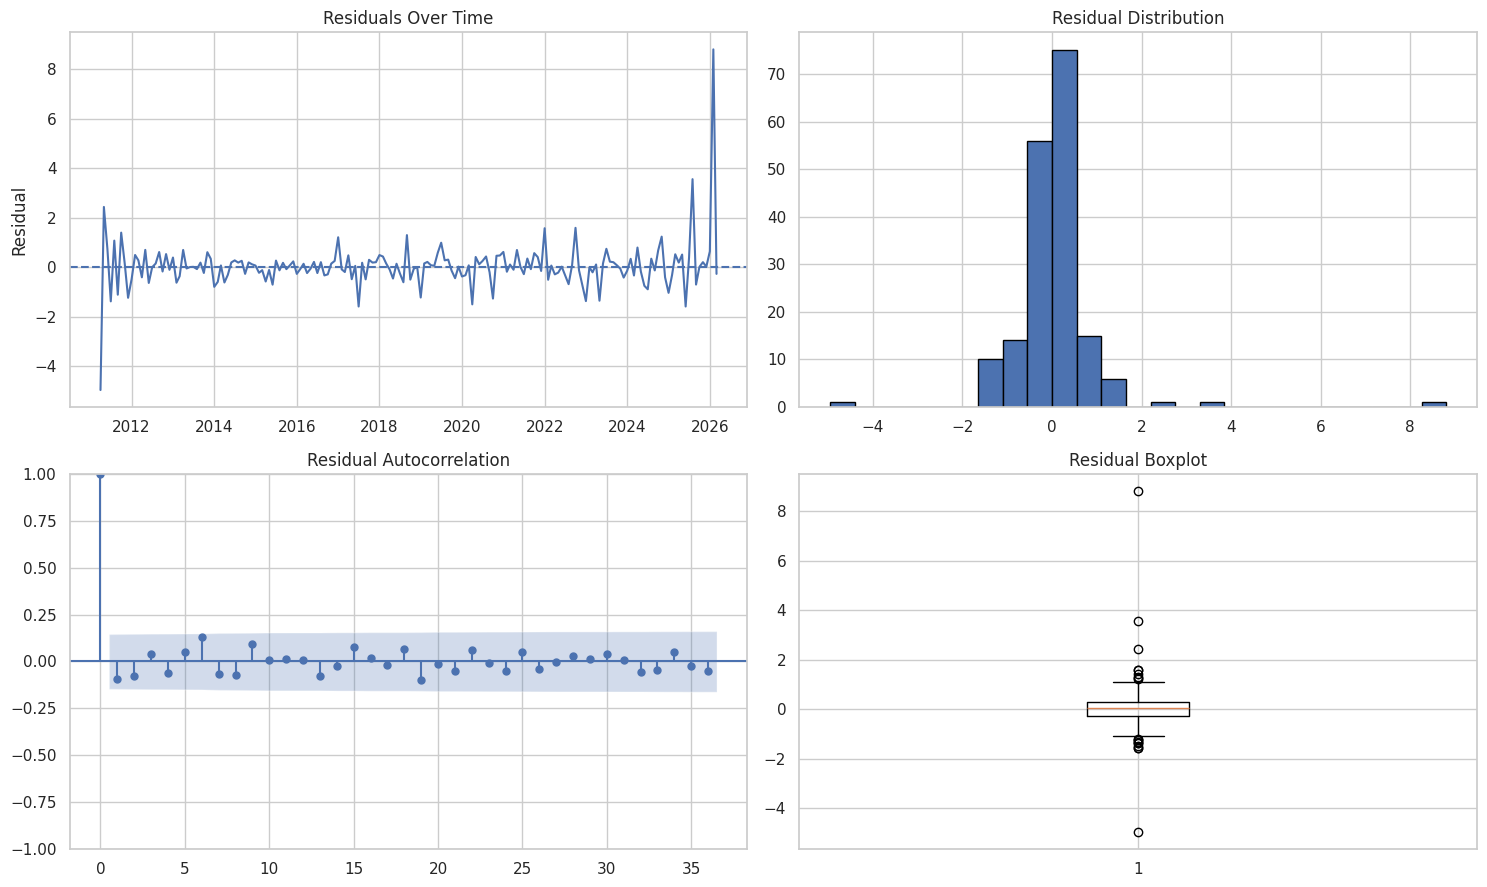


DIAGNOSTIC INTERPRETATION
------------------------
Residuals show evidence of non-normality.
No significant residual autocorrelation detected at tested lags.


In [ ]:

# STEP 46.3 — Rolling 180-Month SARIMAX Residual Diagnostics

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox
from scipy.stats import jarque_bera, skew, kurtosis

warnings.filterwarnings("ignore")

# --------------------------------------------------
# 1. PREPARE LATEST 180 MONTHS
# --------------------------------------------------

window_size = 180

historical_y = y.tail(window_size)

historical_exog = sarimax_actual_df.loc[
    historical_y.index, ["IPG3344S"]
]

scaler = StandardScaler()

historical_scaled = scaler.fit_transform(
    historical_exog
)

# --------------------------------------------------
# 2. FIT FINAL ROLLING SARIMAX
# --------------------------------------------------

diagnostic_model = SARIMAX(
    historical_y,
    exog=historical_scaled,
    order=(1, 1, 1),
    seasonal_order=(1, 0, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
)

diagnostic_fit = diagnostic_model.fit(
    disp=False,
    maxiter=200
)

residuals = pd.Series(
    diagnostic_fit.resid,
    index=historical_y.index
).dropna()

print("ROLLING 180-MONTH SARIMAX")
print("Training observations:", len(historical_y))
print("Residual observations:", len(residuals))
print("Model convergence:", diagnostic_fit.mle_retvals.get(
    "converged", "Unknown"
))

# --------------------------------------------------
# 3. RESIDUAL STATISTICS
# --------------------------------------------------

print("\nRESIDUAL STATISTICS")
print("-------------------")

print("Mean:", round(residuals.mean(), 4))
print("Standard deviation:", round(residuals.std(), 4))
print("Skewness:", round(skew(residuals), 4))
print("Kurtosis:", round(kurtosis(residuals), 4))

jb_stat, jb_p = jarque_bera(residuals)

print("\nJarque-Bera statistic:", round(jb_stat, 4))
print("Jarque-Bera p-value:", round(jb_p, 6))

# --------------------------------------------------
# 4. LJUNG-BOX TEST
# --------------------------------------------------

print("\nLJUNG-BOX TEST")

lb_results = acorr_ljungbox(
    residuals,
    lags=[12, 24],
    model_df=4,
    return_df=True
)

display(lb_results.round(5))

# --------------------------------------------------
# 5. VISUAL DIAGNOSTICS
# --------------------------------------------------

fig, axes = plt.subplots(2, 2, figsize=(15, 9))

# Residual time series
axes[0, 0].plot(residuals.index, residuals)
axes[0, 0].axhline(0, linestyle="--")
axes[0, 0].set_title("Residuals Over Time")
axes[0, 0].set_ylabel("Residual")

# Residual histogram
axes[0, 1].hist(
    residuals,
    bins=25,
    edgecolor="black"
)
axes[0, 1].set_title("Residual Distribution")

# Residual ACF
plot_acf(
    residuals,
    lags=36,
    ax=axes[1, 0]
)
axes[1, 0].set_title("Residual Autocorrelation")

# Residual boxplot
axes[1, 1].boxplot(residuals)
axes[1, 1].set_title("Residual Boxplot")

plt.tight_layout()
plt.show()

# --------------------------------------------------
# 6. AUTOMATIC INTERPRETATION
# --------------------------------------------------

print("\nDIAGNOSTIC INTERPRETATION")
print("------------------------")

if jb_p < 0.05:
    print("Residuals show evidence of non-normality.")
else:
    print("No significant evidence of non-normality.")

if (lb_results["lb_pvalue"] < 0.05).any():
    print("Residual autocorrelation detected at a tested lag.")
else:
    print("No significant residual autocorrelation detected at tested lags.")


Research interpretation
Our model has captured much of the serial dependence in inflation, but it does not fully explain extreme observations.

This suggests that a conventional Gaussian-error SARIMAX model may be insufficient during sudden economic disruptions.

We should not remove those outliers automatically because they may represent genuine economic events.


**Compare robust forecasting alternatives**

**StandardScaler vs RobustScaler**

In [ ]:

# STEP 46.4 — StandardScaler vs RobustScaler
# Rolling 180-Month SARIMAX

import warnings
import numpy as np
import pandas as pd

from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

warnings.filterwarnings("ignore")

# --------------------------------------------------
# 1. CONFIGURATION
# --------------------------------------------------

scalers = {
    "StandardScaler": StandardScaler(),
    "RobustScaler": RobustScaler()
}

forecast_origins = sarima_results[
    "Forecast_Origin"
].tolist()

all_scaler_predictions = {}
scaler_results = []

# --------------------------------------------------
# 2. RUN BOTH SCALING EXPERIMENTS
# --------------------------------------------------

for scaler_name, scaler_template in scalers.items():

    print(f"\nRunning: {scaler_name}")

    predictions = []

    for origin in forecast_origins:

        target_date = origin + pd.DateOffset(months=6)

        if target_date not in y.index:
            continue

        # Latest 180 months available at forecast origin
        historical_y = y.loc[:origin].tail(180)

        historical_exog = sarimax_actual_df.loc[
            historical_y.index, ["IPG3344S"]
        ]

        # Fit scaler only on historical observations
        scaler = scaler_template.__class__()

        historical_scaled = scaler.fit_transform(
            historical_exog
        )

        # Persistence assumption for future production
        future_exog = pd.DataFrame(
            scaler.transform(
                pd.DataFrame(
                    np.repeat(
                        historical_exog.iloc[[-1]].values,
                        6,
                        axis=0
                    ),
                    columns=["IPG3344S"]
                )
            ),
            columns=["IPG3344S"]
        )

        # Fit SARIMAX
        model = SARIMAX(
            historical_y,
            exog=historical_scaled,
            order=(1, 1, 1),
            seasonal_order=(1, 0, 1, 12),
            enforce_stationarity=False,
            enforce_invertibility=False
        )

        fitted = model.fit(
            disp=False,
            maxiter=200
        )

        forecast = fitted.forecast(
            steps=6,
            exog=future_exog
        )

        predictions.append({
            "Forecast_Origin": origin,
            "Target_Date": target_date,
            "Actual": y.loc[target_date],
            "Predicted": forecast.iloc[-1]
        })

    pred_df = pd.DataFrame(predictions)

    all_scaler_predictions[scaler_name] = pred_df

    actual = pred_df["Actual"]
    predicted = pred_df["Predicted"]

    scaler_results.append({
        "Scaler": scaler_name,
        "Observations": len(pred_df),
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(
            mean_squared_error(actual, predicted)
        ),
        "R2": r2_score(actual, predicted),
        "Bias": np.mean(actual - predicted)
    })

# --------------------------------------------------
# 3. PERFORMANCE COMPARISON
# --------------------------------------------------

scaler_comparison = pd.DataFrame(scaler_results)

print("\nSCALING METHOD COMPARISON")
print("=" * 65)

display(scaler_comparison.round(4))

# --------------------------------------------------
# 4. MAE IMPROVEMENT
# --------------------------------------------------

standard_mae = scaler_comparison.loc[
    scaler_comparison["Scaler"] == "StandardScaler",
    "MAE"
].iloc[0]

robust_mae = scaler_comparison.loc[
    scaler_comparison["Scaler"] == "RobustScaler",
    "MAE"
].iloc[0]

improvement = (
    (standard_mae - robust_mae) / standard_mae
) * 100

print("\nROBUST SCALING ANALYSIS")
print("-----------------------")
print(f"StandardScaler MAE: {standard_mae:.4f}")
print(f"RobustScaler MAE: {robust_mae:.4f}")
print(f"MAE improvement: {improvement:.2f}%")

print("\nExperiment completed successfully.")



Running: StandardScaler

Running: RobustScaler

SCALING METHOD COMPARISON


,Scaler,Observations,MAE,RMSE,R2,Bias
0,StandardScaler,73,1.6989,2.6923,0.2960,0.8639
1,RobustScaler,73,1.6990,2.6925,0.2959,0.8641



ROBUST SCALING ANALYSIS
-----------------------
StandardScaler MAE: 1.6989
RobustScaler MAE: 1.6990
MAE improvement: -0.01%

Experiment completed successfully.


**Research interpretation**

The extreme residuals are unlikely to be addressed simply by changing the scaling method. The model's difficulty appears more related to sudden changes in the target inflation series than to the scaling of industrial production.

We should retain StandardScaler and avoid unnecessary model complexity.

**Compare forecast performance during inflation surges**

In [ ]:

# STEP 46.6 — Inflation Regime Forecast Analysis

import numpy as np
import pandas as pd

# Match both models by target date
regime_test = sarima_results[
    ["Target_Date", "Actual", "Predicted"]
].merge(
    all_predictions["Rolling_180_Months"][
        ["Target_Date", "Predicted"]
    ],
    on="Target_Date",
    suffixes=("_SARIMA", "_SARIMAX")
)

# Categorize actual inflation
def inflation_category(value):
    if value < 0:
        return "Low Inflation (<0%)"
    elif value <= 5:
        return "Moderate Inflation (0-5%)"
    else:
        return "High Inflation (>5%)"

regime_test["Inflation_Regime"] = (
    regime_test["Actual"].apply(inflation_category)
)

# Calculate errors
regime_test["SARIMA_Error"] = (
    regime_test["Actual"] -
    regime_test["Predicted_SARIMA"]
)

regime_test["SARIMAX_Error"] = (
    regime_test["Actual"] -
    regime_test["Predicted_SARIMAX"]
)

regime_test["SARIMA_Abs_Error"] = (
    regime_test["SARIMA_Error"].abs()
)

regime_test["SARIMAX_Abs_Error"] = (
    regime_test["SARIMAX_Error"].abs()
)

# Regime-wise comparison
regime_analysis = regime_test.groupby(
    "Inflation_Regime"
).agg(
    Observations=("Actual", "count"),
    SARIMA_MAE=("SARIMA_Abs_Error", "mean"),
    SARIMAX_MAE=("SARIMAX_Abs_Error", "mean"),
    SARIMA_Bias=("SARIMA_Error", "mean"),
    SARIMAX_Bias=("SARIMAX_Error", "mean")
)

regime_analysis["MAE_Improvement_%"] = (
    (regime_analysis["SARIMA_MAE"] -
     regime_analysis["SARIMAX_MAE"])
    / regime_analysis["SARIMA_MAE"]
) * 100

print("INFLATION REGIME ANALYSIS")
print("=" * 75)

display(regime_analysis.round(4))

print("\nHIGH-INFLATION FORECASTS")
print("=" * 75)

display(
    regime_test[
        regime_test["Inflation_Regime"] ==
        "High Inflation (>5%)"
    ][
        [
            "Target_Date",
            "Actual",
            "Predicted_SARIMA",
            "Predicted_SARIMAX"
        ]
    ].round(4)
)


INFLATION REGIME ANALYSIS


,Observations,SARIMA_MAE,SARIMAX_MAE,SARIMA_Bias,SARIMAX_Bias,MAE_Improvement_%
Inflation_Regime,,,,,,
High Inflation (>5%),3,11.0588,9.8241,11.0588,9.8241,11.1650
Low Inflation (<0%),20,1.1290,1.3272,0.0278,-0.6344,-17.5590
Moderate Inflation (0-5%),50,1.9499,1.3600,1.7010,0.9256,30.2529



HIGH-INFLATION FORECASTS


,Target_Date,Actual,Predicted_SARIMA,Predicted_SARIMAX
70,2026-01-01,5.6820,-1.5853,0.1333
71,2026-02-01,15.4107,3.6268,4.4727
72,2026-03-01,16.8712,2.7460,3.8856


Three major findings
1. Moderate inflation: Industrial production provides substantial improvement, reducing MAE by approximately 30.25%.

2. Low inflation: SARIMA performs better. Adding industrial production does not help in this regime.

3. High inflation: SARIMAX performs better, but its error remains extremely large.

**You can record this preliminary finding:**


Regime-wise evaluation revealed heterogeneous forecasting performance. The SARIMAX model incorporating semiconductor industrial production achieved a 30.25% reduction in MAE during moderate inflation conditions. However, its performance deteriorated during low-inflation periods, while extreme inflation observations remained difficult to predict. This indicates that the predictive contribution of manufacturing indicators may vary across inflation regimes.

**Prediction intervals and uncertainty analysis**

PREDICTION INTERVAL SUMMARY


,Metric,80% Interval,95% Interval
0,Nominal Coverage,80%,95%
1,Actual Coverage (%),71.232877,78.082192
2,Average Interval Width,3.337437,5.104169



RECENT PERIOD INTERVAL COVERAGE
Observations: 15
80% Coverage: 33.33 %
95% Coverage: 46.67 %

2026 FORECAST INTERVALS


,Target_Date,Actual,Predicted,Lower_80,Upper_80,Lower_95,Upper_95
70,2026-01-01,5.6820,0.1333,-1.5345,1.8010,-2.4173,2.6838
71,2026-02-01,15.4107,4.4727,2.6340,6.3114,1.6607,7.2848
72,2026-03-01,16.8712,3.8856,2.0376,5.7337,1.0593,6.7120


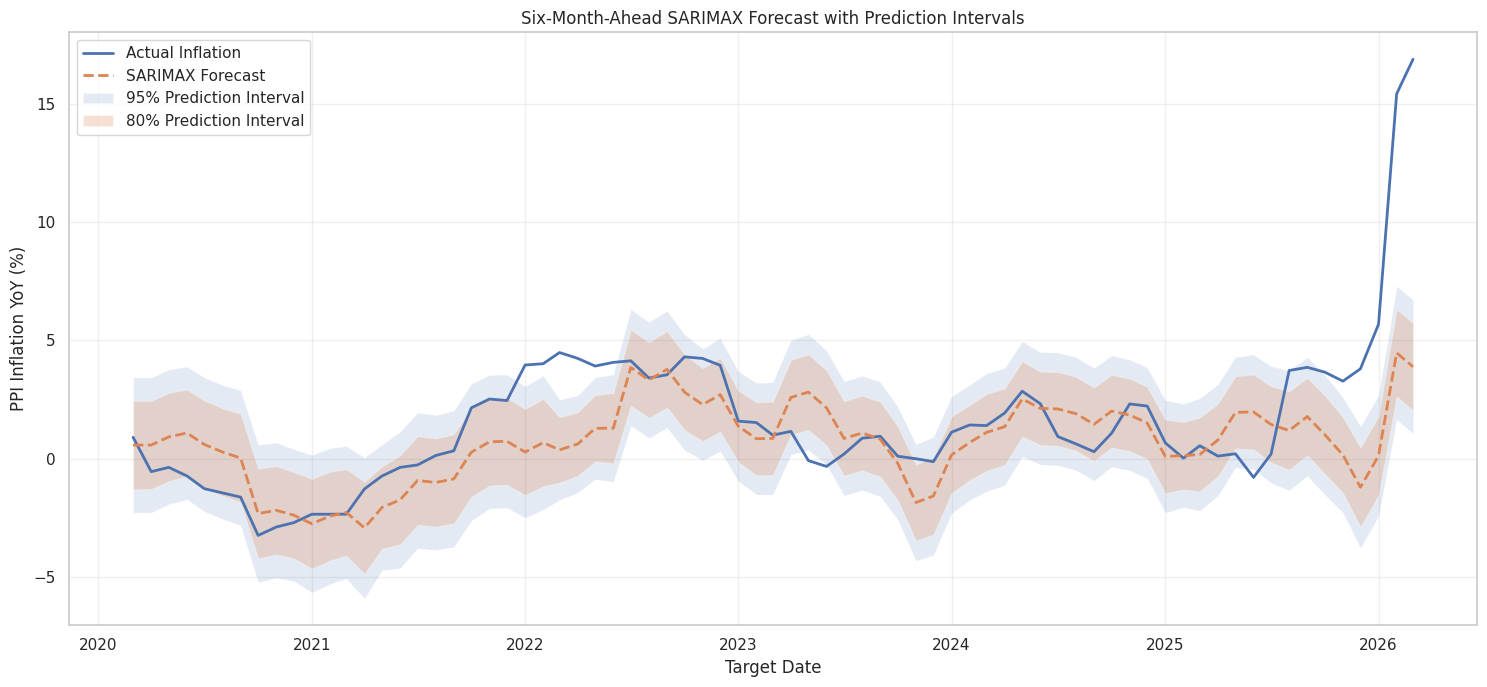


Prediction interval analysis completed.


In [ ]:

# STEP 46.7 — SARIMAX Prediction Interval Analysis
# Rolling 180-month model

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")

# --------------------------------------------------
# 1. CONFIGURATION
# --------------------------------------------------

forecast_horizon = 6
window_size = 180

forecast_origins = sarima_results[
    "Forecast_Origin"
].tolist()

interval_predictions = []

# --------------------------------------------------
# 2. ROLLING FORECAST WITH PREDICTION INTERVALS
# --------------------------------------------------

for origin in forecast_origins:

    target_date = origin + pd.DateOffset(
        months=forecast_horizon
    )

    if target_date not in y.index:
        continue

    # Historical 180-month window
    historical_y = y.loc[:origin].tail(window_size)

    historical_exog = sarimax_actual_df.loc[
        historical_y.index, ["IPG3344S"]
    ]

    # Scale using historical data only
    scaler = StandardScaler()

    historical_scaled = scaler.fit_transform(
        historical_exog
    )

    # Future production: persistence assumption
    future_exog = pd.DataFrame(
        np.repeat(
            historical_scaled[-1].reshape(1, -1),
            forecast_horizon,
            axis=0
        ),
        columns=["IPG3344S"]
    )

    # Fit SARIMAX
    model = SARIMAX(
        historical_y,
        exog=historical_scaled,
        order=(1, 1, 1),
        seasonal_order=(1, 0, 1, 12),
        enforce_stationarity=False,
        enforce_invertibility=False
    )

    fitted = model.fit(
        disp=False,
        maxiter=200
    )

    # Obtain six-month forecast distribution
    forecast_object = fitted.get_forecast(
        steps=forecast_horizon,
        exog=future_exog
    )

    # Point forecast
    point_forecast = forecast_object.predicted_mean.iloc[-1]

    # 80% prediction interval
    ci_80 = forecast_object.conf_int(alpha=0.20).iloc[-1]

    # 95% prediction interval
    ci_95 = forecast_object.conf_int(alpha=0.05).iloc[-1]

    interval_predictions.append({
        "Forecast_Origin": origin,
        "Target_Date": target_date,
        "Actual": y.loc[target_date],
        "Predicted": point_forecast,
        "Lower_80": ci_80.iloc[0],
        "Upper_80": ci_80.iloc[1],
        "Lower_95": ci_95.iloc[0],
        "Upper_95": ci_95.iloc[1]
    })

interval_df = pd.DataFrame(interval_predictions)

# --------------------------------------------------
# 3. INTERVAL COVERAGE
# --------------------------------------------------

interval_df["Covered_80"] = (
    (interval_df["Actual"] >= interval_df["Lower_80"]) &
    (interval_df["Actual"] <= interval_df["Upper_80"])
)

interval_df["Covered_95"] = (
    (interval_df["Actual"] >= interval_df["Lower_95"]) &
    (interval_df["Actual"] <= interval_df["Upper_95"])
)

interval_df["Width_80"] = (
    interval_df["Upper_80"] - interval_df["Lower_80"]
)

interval_df["Width_95"] = (
    interval_df["Upper_95"] - interval_df["Lower_95"]
)

coverage_80 = interval_df["Covered_80"].mean() * 100
coverage_95 = interval_df["Covered_95"].mean() * 100

# --------------------------------------------------
# 4. SUMMARY TABLE
# --------------------------------------------------

interval_summary = pd.DataFrame({
    "Metric": [
        "Nominal Coverage",
        "Actual Coverage (%)",
        "Average Interval Width"
    ],
    "80% Interval": [
        "80%",
        coverage_80,
        interval_df["Width_80"].mean()
    ],
    "95% Interval": [
        "95%",
        coverage_95,
        interval_df["Width_95"].mean()
    ]
})

print("PREDICTION INTERVAL SUMMARY")
print("=" * 65)

display(interval_summary.round(4))

# --------------------------------------------------
# 5. RECENT PERIOD ANALYSIS
# --------------------------------------------------

recent_intervals = interval_df[
    pd.to_datetime(interval_df["Target_Date"]) >= "2025-01-01"
].copy()

print("\nRECENT PERIOD INTERVAL COVERAGE")
print("=" * 65)

print(
    "Observations:",
    len(recent_intervals)
)

print(
    "80% Coverage:",
    round(recent_intervals["Covered_80"].mean() * 100, 2),
    "%"
)

print(
    "95% Coverage:",
    round(recent_intervals["Covered_95"].mean() * 100, 2),
    "%"
)

print("\n2026 FORECAST INTERVALS")

display(
    interval_df[
        pd.to_datetime(interval_df["Target_Date"]).dt.year == 2026
    ][
        [
            "Target_Date",
            "Actual",
            "Predicted",
            "Lower_80",
            "Upper_80",
            "Lower_95",
            "Upper_95"
        ]
    ].round(4)
)

# --------------------------------------------------
# 6. VISUALIZATION
# --------------------------------------------------

plt.figure(figsize=(15, 7))

plt.plot(
    interval_df["Target_Date"],
    interval_df["Actual"],
    label="Actual Inflation",
    linewidth=2
)

plt.plot(
    interval_df["Target_Date"],
    interval_df["Predicted"],
    label="SARIMAX Forecast",
    linestyle="--",
    linewidth=2
)

plt.fill_between(
    interval_df["Target_Date"],
    interval_df["Lower_95"],
    interval_df["Upper_95"],
    alpha=0.15,
    label="95% Prediction Interval"
)

plt.fill_between(
    interval_df["Target_Date"],
    interval_df["Lower_80"],
    interval_df["Upper_80"],
    alpha=0.25,
    label="80% Prediction Interval"
)

plt.title(
    "Six-Month-Ahead SARIMAX Forecast with Prediction Intervals"
)

plt.xlabel("Target Date")
plt.ylabel("PPI Inflation YoY (%)")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Save results
interval_df.to_csv(
    "SARIMAX_Prediction_Intervals.csv",
    index=False
)

print("\nPrediction interval analysis completed.")


All three actual observations fall outside their 95% prediction intervals.

This is a strong warning that the model's Gaussian uncertainty assumptions are not adequately capturing the 2026 inflation surge.

Recent-period coverage is also poor:
- 80% coverage: 33.33%.
- 95% coverage: 46.67%.
- Only 15 recent observations were evaluated.

All three actual observations fall outside their 95% prediction intervals.

This is a strong warning that the model's Gaussian uncertainty assumptions are not adequately capturing the 2026 inflation surge.

Recent-period coverage is also poor:
- 80% coverage: 33.33%.
- 95% coverage: 46.67%.
- Only 15 recent observations were evaluated.

**Conformal prediction intervals**

Calibration observations: 48
Evaluation observations: 25
Calibration period: 2020-03-01 00:00:00 to 2024-02-01 00:00:00
Evaluation period: 2024-03-01 00:00:00 to 2026-03-01 00:00:00

CONFORMAL CALIBRATION
---------------------
80% error quantile: 1.9489
95% error quantile: 3.6754

CONFORMAL PREDICTION RESULTS


,Metric,80% Conformal,95% Conformal
0,Nominal Coverage,80%,95%
1,Actual Coverage (%),64.0,84.0
2,Average Width,3.897756,7.350895



EVALUATION FORECASTS


,Target_Date,Actual,Predicted,Lower_80,Upper_80,Lower_95,Upper_95,Covered_95
48,2024-03-01,1.4013,1.1145,-0.8344,3.0634,-2.5609,4.7900,True
49,2024-04-01,1.9317,1.3551,-0.5938,3.3040,-2.3203,5.0306,True
50,2024-05-01,2.8539,2.5259,0.5771,4.4748,-1.1495,6.2014,True
51,2024-06-01,2.3245,2.1288,0.1800,4.0777,-1.5466,5.8043,True
52,2024-07-01,0.9380,2.1047,0.1559,4.0536,-1.5707,5.7802,True
53,2024-08-01,0.6283,1.9029,-0.0460,3.8518,-1.7726,5.5783,True
54,2024-09-01,0.2981,1.4555,-0.4934,3.4044,-2.2200,5.1309,True
55,2024-10-01,1.0787,2.0152,0.0663,3.9641,-1.6603,5.6906,True
56,2024-11-01,2.3159,1.8476,-0.1013,3.7965,-1.8278,5.5231,True
57,2024-12-01,2.2260,1.5112,-0.4376,3.4601,-2.1642,5.1867,True


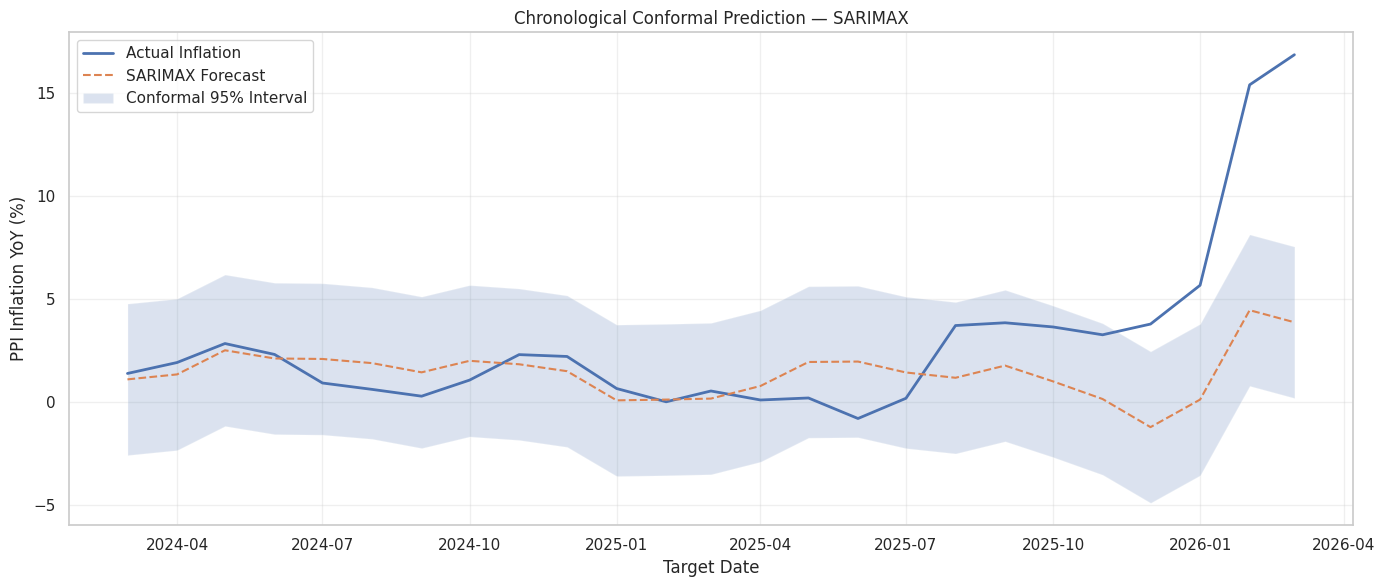


Conformal prediction experiment completed.


In [ ]:

# STEP 46.8 — Chronological Conformal Prediction
# Rolling 180-month SARIMAX

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")

# --------------------------------------------------
# 1. GENERATE ROLLING SARIMAX FORECASTS
# --------------------------------------------------

origins = sarima_results["Forecast_Origin"].tolist()

forecast_records = []

for origin in origins:

    target_date = origin + pd.DateOffset(months=6)

    if target_date not in y.index:
        continue

    # Rolling 180-month training history
    historical_y = y.loc[:origin].tail(180)

    historical_exog = sarimax_actual_df.loc[
        historical_y.index, ["IPG3344S"]
    ]

    scaler = StandardScaler()

    historical_scaled = scaler.fit_transform(
        historical_exog
    )

    # Future indicator persistence assumption
    future_exog = pd.DataFrame(
        np.repeat(
            historical_scaled[-1].reshape(1, -1),
            6,
            axis=0
        ),
        columns=["IPG3344S"]
    )

    model = SARIMAX(
        historical_y,
        exog=historical_scaled,
        order=(1, 1, 1),
        seasonal_order=(1, 0, 1, 12),
        enforce_stationarity=False,
        enforce_invertibility=False
    )

    fitted = model.fit(disp=False, maxiter=200)

    forecast = fitted.forecast(
        steps=6,
        exog=future_exog
    )

    forecast_records.append({
        "Forecast_Origin": origin,
        "Target_Date": target_date,
        "Actual": y.loc[target_date],
        "Predicted": forecast.iloc[-1]
    })

conformal_df = pd.DataFrame(forecast_records)

# --------------------------------------------------
# 2. CHRONOLOGICAL CALIBRATION / EVALUATION SPLIT
# --------------------------------------------------

# First 48 forecasts: calibration
# Remaining forecasts: evaluation

calibration_df = conformal_df.iloc[:48].copy()
evaluation_df = conformal_df.iloc[48:].copy()

calibration_errors = np.abs(
    calibration_df["Actual"] -
    calibration_df["Predicted"]
).to_numpy()

print("Calibration observations:", len(calibration_df))
print("Evaluation observations:", len(evaluation_df))

print(
    "Calibration period:",
    calibration_df["Target_Date"].min(),
    "to",
    calibration_df["Target_Date"].max()
)

print(
    "Evaluation period:",
    evaluation_df["Target_Date"].min(),
    "to",
    evaluation_df["Target_Date"].max()
)

# --------------------------------------------------
# 3. FINITE-SAMPLE CONFORMAL QUANTILES
# --------------------------------------------------

def conformal_quantile(errors, coverage):

    n = len(errors)

    rank = int(np.ceil((n + 1) * coverage))

    rank = min(rank, n)

    return np.sort(errors)[rank - 1]

q80 = conformal_quantile(calibration_errors, 0.80)
q95 = conformal_quantile(calibration_errors, 0.95)

print("\nCONFORMAL CALIBRATION")
print("---------------------")
print(f"80% error quantile: {q80:.4f}")
print(f"95% error quantile: {q95:.4f}")

# --------------------------------------------------
# 4. CONSTRUCT PREDICTION INTERVALS
# --------------------------------------------------

evaluation_df["Lower_80"] = (
    evaluation_df["Predicted"] - q80
)

evaluation_df["Upper_80"] = (
    evaluation_df["Predicted"] + q80
)

evaluation_df["Lower_95"] = (
    evaluation_df["Predicted"] - q95
)

evaluation_df["Upper_95"] = (
    evaluation_df["Predicted"] + q95
)

evaluation_df["Covered_80"] = (
    (evaluation_df["Actual"] >= evaluation_df["Lower_80"]) &
    (evaluation_df["Actual"] <= evaluation_df["Upper_80"])
)

evaluation_df["Covered_95"] = (
    (evaluation_df["Actual"] >= evaluation_df["Lower_95"]) &
    (evaluation_df["Actual"] <= evaluation_df["Upper_95"])
)

# --------------------------------------------------
# 5. EVALUATION
# --------------------------------------------------

summary = pd.DataFrame({
    "Metric": [
        "Nominal Coverage",
        "Actual Coverage (%)",
        "Average Width"
    ],
    "80% Conformal": [
        "80%",
        evaluation_df["Covered_80"].mean() * 100,
        2 * q80
    ],
    "95% Conformal": [
        "95%",
        evaluation_df["Covered_95"].mean() * 100,
        2 * q95
    ]
})

print("\nCONFORMAL PREDICTION RESULTS")
print("=" * 65)

display(summary.round(4))

# --------------------------------------------------
# 6. RECENT EVALUATION OBSERVATIONS
# --------------------------------------------------

print("\nEVALUATION FORECASTS")

display(
    evaluation_df[
        [
            "Target_Date",
            "Actual",
            "Predicted",
            "Lower_80",
            "Upper_80",
            "Lower_95",
            "Upper_95",
            "Covered_95"
        ]
    ].round(4)
)

# --------------------------------------------------
# 7. VISUALIZATION
# --------------------------------------------------

plt.figure(figsize=(14, 6))

plt.plot(
    evaluation_df["Target_Date"],
    evaluation_df["Actual"],
    label="Actual Inflation",
    linewidth=2
)

plt.plot(
    evaluation_df["Target_Date"],
    evaluation_df["Predicted"],
    label="SARIMAX Forecast",
    linestyle="--"
)

plt.fill_between(
    evaluation_df["Target_Date"],
    evaluation_df["Lower_95"],
    evaluation_df["Upper_95"],
    alpha=0.20,
    label="Conformal 95% Interval"
)

plt.title("Chronological Conformal Prediction — SARIMAX")
plt.xlabel("Target Date")
plt.ylabel("PPI Inflation YoY (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 8. SAVE RESULTS
# --------------------------------------------------

evaluation_df.to_csv(
    "Conformal_SARIMAX_Evaluation.csv",
    index=False
)

print("\nConformal prediction experiment completed.")


Interpretation: The historical calibration errors are not representative of the newer economic regime.

One limitation: only 25 evaluation observations are available, and the six-month forecast errors overlap. Therefore, the coverage estimates are exploratory rather than definitive.

**Adaptive rolling conformal prediction**

ADAPTIVE CONFORMAL PREDICTION
Evaluation observations: 56
Calibration window: 24
Minimum matured errors: 12


,Metric,80% Adaptive,95% Adaptive
0,Nominal Coverage,80%,95%
1,Actual Coverage (%),66.071429,78.571429
2,Average Interval Width,4.197376,6.475973



RECENT PERIOD PERFORMANCE
Observations: 15
80% coverage: 33.33 %
95% coverage: 66.67 %


,Target_Date,Actual,Predicted,Q80,Q95,Lower_95,Upper_95,Covered_95
41,2025-01-01,0.6703,0.0959,1.4952,2.8927,-2.7968,2.9886,True
42,2025-02-01,0.0258,0.1330,1.4952,2.8927,-2.7597,3.0257,True
43,2025-03-01,0.5507,0.1816,1.4952,2.8927,-2.7111,3.0743,True
44,2025-04-01,0.1133,0.7932,1.4514,2.8927,-2.0995,3.6859,True
45,2025-05-01,0.2113,1.9582,1.4322,2.8927,-0.9345,4.8509,True
46,2025-06-01,-0.7854,1.9788,1.4322,2.8927,-0.9139,4.8715,True
47,2025-07-01,0.1966,1.4491,1.4322,2.8927,-1.4436,4.3418,True
48,2025-08-01,3.7273,1.1922,1.4322,2.8927,-1.7005,4.0849,True
49,2025-09-01,3.8615,1.7835,1.4322,2.8927,-1.1092,4.6762,True
50,2025-10-01,3.6584,1.0170,1.2745,2.8927,-1.8757,3.9097,True


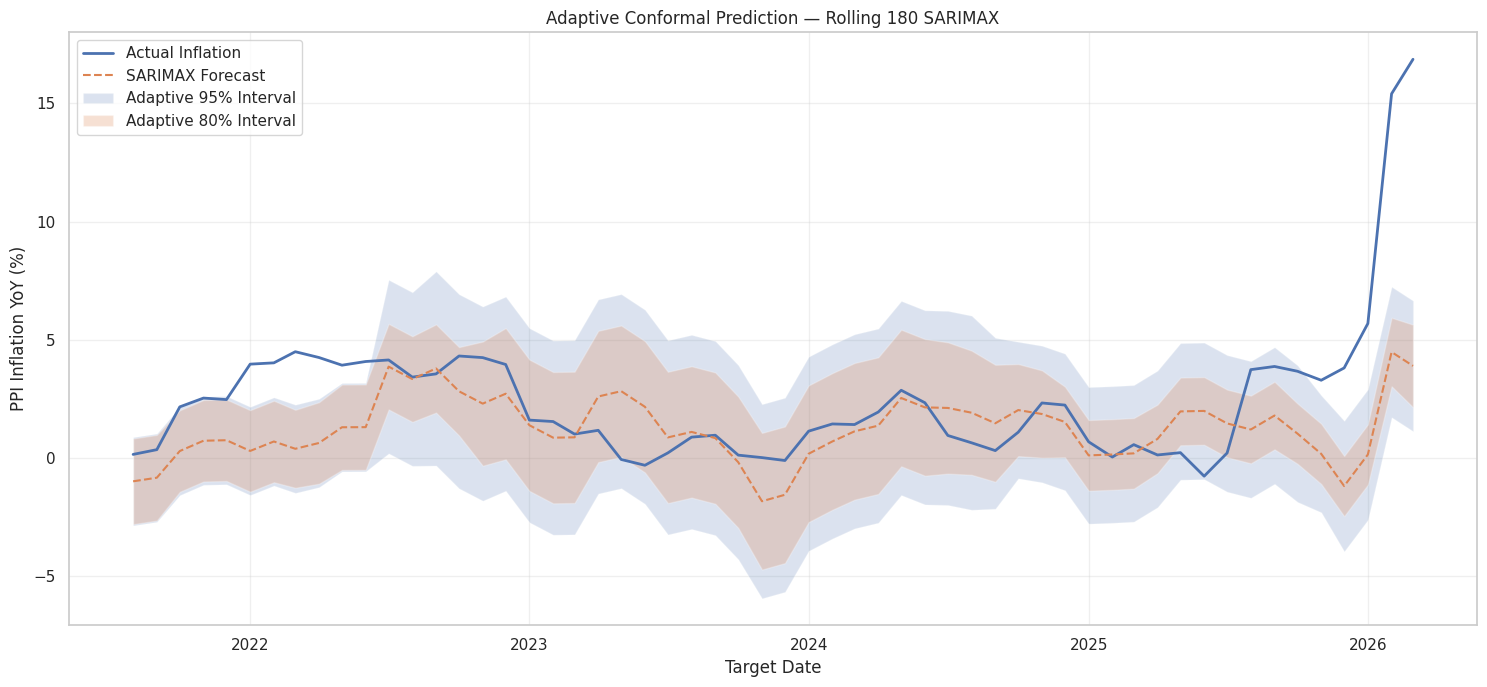


Adaptive conformal analysis completed.


In [ ]:

# STEP 46.9 — ADAPTIVE ROLLING CONFORMAL PREDICTION

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. PREPARE EXISTING SARIMAX FORECASTS
# --------------------------------------------------

adaptive_df = conformal_df.copy()

adaptive_df["Forecast_Origin"] = pd.to_datetime(
    adaptive_df["Forecast_Origin"]
)

adaptive_df["Target_Date"] = pd.to_datetime(
    adaptive_df["Target_Date"]
)

adaptive_df = adaptive_df.sort_values(
    "Forecast_Origin"
).reset_index(drop=True)

adaptive_df["Absolute_Error"] = (
    adaptive_df["Actual"] -
    adaptive_df["Predicted"]
).abs()

CALIBRATION_WINDOW = 24
MIN_CALIBRATION_ERRORS = 12

adaptive_records = []

# --------------------------------------------------
# 2. ADAPTIVE CALIBRATION
# --------------------------------------------------

for _, current in adaptive_df.iterrows():

    origin = current["Forecast_Origin"]

    # Only use errors whose actual outcomes
    # were available by the current forecast origin.
    matured = adaptive_df[
        adaptive_df["Target_Date"] <= origin
    ].copy()

    # Keep the most recent matured errors
    matured = matured.tail(CALIBRATION_WINDOW)

    if len(matured) < MIN_CALIBRATION_ERRORS:
        continue

    errors = matured["Absolute_Error"].to_numpy()

    # Finite-sample conformal quantile
    def adaptive_quantile(values, coverage):

        n = len(values)

        rank = int(np.ceil((n + 1) * coverage))
        rank = min(rank, n)

        return np.sort(values)[rank - 1]

    q80 = adaptive_quantile(errors, 0.80)
    q95 = adaptive_quantile(errors, 0.95)

    prediction = current["Predicted"]

    adaptive_records.append({
        "Forecast_Origin": origin,
        "Target_Date": current["Target_Date"],
        "Actual": current["Actual"],
        "Predicted": prediction,
        "Calibration_Count": len(matured),
        "Q80": q80,
        "Q95": q95,
        "Lower_80": prediction - q80,
        "Upper_80": prediction + q80,
        "Lower_95": prediction - q95,
        "Upper_95": prediction + q95
    })

adaptive_results = pd.DataFrame(adaptive_records)

if adaptive_results.empty:
    raise ValueError(
        "Not enough matured forecast errors for adaptive calibration."
    )

# --------------------------------------------------
# 3. CALCULATE COVERAGE
# --------------------------------------------------

adaptive_results["Covered_80"] = (
    (adaptive_results["Actual"] >= adaptive_results["Lower_80"]) &
    (adaptive_results["Actual"] <= adaptive_results["Upper_80"])
)

adaptive_results["Covered_95"] = (
    (adaptive_results["Actual"] >= adaptive_results["Lower_95"]) &
    (adaptive_results["Actual"] <= adaptive_results["Upper_95"])
)

adaptive_results["Width_80"] = (
    adaptive_results["Upper_80"] -
    adaptive_results["Lower_80"]
)

adaptive_results["Width_95"] = (
    adaptive_results["Upper_95"] -
    adaptive_results["Lower_95"]
)

# --------------------------------------------------
# 4. SUMMARY
# --------------------------------------------------

summary = pd.DataFrame({
    "Metric": [
        "Nominal Coverage",
        "Actual Coverage (%)",
        "Average Interval Width"
    ],
    "80% Adaptive": [
        "80%",
        adaptive_results["Covered_80"].mean() * 100,
        adaptive_results["Width_80"].mean()
    ],
    "95% Adaptive": [
        "95%",
        adaptive_results["Covered_95"].mean() * 100,
        adaptive_results["Width_95"].mean()
    ]
})

print("ADAPTIVE CONFORMAL PREDICTION")
print("=" * 70)

print("Evaluation observations:", len(adaptive_results))
print("Calibration window:", CALIBRATION_WINDOW)
print("Minimum matured errors:", MIN_CALIBRATION_ERRORS)

display(summary.round(4))

# --------------------------------------------------
# 5. RECENT PERIOD PERFORMANCE
# --------------------------------------------------

recent = adaptive_results[
    adaptive_results["Target_Date"] >= "2025-01-01"
].copy()

print("\nRECENT PERIOD PERFORMANCE")
print("=" * 70)

if len(recent) > 0:

    print("Observations:", len(recent))

    print(
        "80% coverage:",
        round(recent["Covered_80"].mean() * 100, 2),
        "%"
    )

    print(
        "95% coverage:",
        round(recent["Covered_95"].mean() * 100, 2),
        "%"
    )

    display(
        recent[
            [
                "Target_Date",
                "Actual",
                "Predicted",
                "Q80",
                "Q95",
                "Lower_95",
                "Upper_95",
                "Covered_95"
            ]
        ].round(4)
    )

# --------------------------------------------------
# 6. PLOT
# --------------------------------------------------

plt.figure(figsize=(15, 7))

plt.plot(
    adaptive_results["Target_Date"],
    adaptive_results["Actual"],
    label="Actual Inflation",
    linewidth=2
)

plt.plot(
    adaptive_results["Target_Date"],
    adaptive_results["Predicted"],
    label="SARIMAX Forecast",
    linestyle="--"
)

plt.fill_between(
    adaptive_results["Target_Date"],
    adaptive_results["Lower_95"],
    adaptive_results["Upper_95"],
    alpha=0.20,
    label="Adaptive 95% Interval"
)

plt.fill_between(
    adaptive_results["Target_Date"],
    adaptive_results["Lower_80"],
    adaptive_results["Upper_80"],
    alpha=0.25,
    label="Adaptive 80% Interval"
)

plt.title("Adaptive Conformal Prediction — Rolling 180 SARIMAX")
plt.xlabel("Target Date")
plt.ylabel("PPI Inflation YoY (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 7. SAVE
# --------------------------------------------------

adaptive_results.to_csv(
    "Adaptive_Conformal_SARIMAX.csv",
    index=False
)

print("\nAdaptive conformal analysis completed.")


Important research conclusion
We now have evidence of three distinct limitations:
- Point forecasts underestimate sharp inflation accelerations.
- Residuals have heavy tails and extreme outliers.
- Both fixed and adaptive conformal intervals under-cover the evaluation observations.
We should report these limitations honestly rather than keep widening intervals until they contain the observed values.

**Build the six forecasting targets**

In [ ]:

# STEP 1 — BUILD SIX-MONTH DIRECT FORECASTING DATASET

import pandas as pd
import numpy as np

# --------------------------------------------------
# 1. PREPARE DATA
# --------------------------------------------------

df = model_df.copy()

df["observation_date"] = pd.to_datetime(
    df["observation_date"]
)

df = df.sort_values("observation_date")
df = df.set_index("observation_date")

target_column = "PPI_Inflation_YoY_pct"

assert target_column in df.columns, (
    f"Missing target column: {target_column}"
)

# Check monthly frequency
print("DATASET OVERVIEW")
print("=" * 55)
print("Shape:", df.shape)
print("Start:", df.index.min())
print("End:", df.index.max())
print("Duplicate dates:", df.index.duplicated().sum())

# --------------------------------------------------
# 2. CREATE SIX FUTURE TARGETS
# --------------------------------------------------

for horizon in range(1, 7):

    df[f"Target_H{horizon}"] = (
        df[target_column].shift(-horizon)
    )

# --------------------------------------------------
# 3. SELECT FEATURES
# --------------------------------------------------

# Remove the previously shifted six-month target
# to prevent accidental target leakage.

excluded_columns = [
    "PPI_Inflation_YoY_6M_Ahead_pct",
    "Target_H1",
    "Target_H2",
    "Target_H3",
    "Target_H4",
    "Target_H5",
    "Target_H6"
]

feature_columns = [
    col for col in df.columns
    if col not in excluded_columns
]

print("\nFEATURE COUNT:", len(feature_columns))

# --------------------------------------------------
# 4. CHECK EACH FORECAST HORIZON
# --------------------------------------------------

horizon_datasets = {}

for horizon in range(1, 7):

    target = f"Target_H{horizon}"

    horizon_df = df[
        feature_columns + [target]
    ].dropna().copy()

    horizon_datasets[horizon] = horizon_df

    print(
        f"\nHorizon +{horizon} month:",
        len(horizon_df),
        "observations"
    )

    print(
        "First target:",
        horizon_df.index.min() + pd.DateOffset(
            months=horizon
        )
    )

    print(
        "Last target:",
        horizon_df.index.max() + pd.DateOffset(
            months=horizon
        )
    )

# --------------------------------------------------
# 5. VERIFY TARGET ALIGNMENT
# --------------------------------------------------

print("\nTARGET ALIGNMENT VERIFICATION")
print("=" * 55)

sample_date = df.index[-10]

for horizon in range(1, 7):

    target_date = sample_date + pd.DateOffset(
        months=horizon
    )

    expected = df.loc[
        target_date, target_column
    ] if target_date in df.index else np.nan

    generated = df.loc[
        sample_date, f"Target_H{horizon}"
    ]

    print(
        f"Horizon +{horizon}: "
        f"Generated={generated:.4f}, "
        f"Expected={expected:.4f}"
        if pd.notna(expected) and pd.notna(generated)
        else f"Horizon +{horizon}: Target unavailable"
    )

print("\nSix-horizon dataset preparation completed.")


DATASET OVERVIEW
Shape: (393, 41)
Start: 1993-07-01 00:00:00
End: 2026-03-01 00:00:00
Duplicate dates: 0

FEATURE COUNT: 40

Horizon +1 month: 392 observations
First target: 1993-08-01 00:00:00
Last target: 2026-03-01 00:00:00

Horizon +2 month: 391 observations
First target: 1993-09-01 00:00:00
Last target: 2026-03-01 00:00:00

Horizon +3 month: 390 observations
First target: 1993-10-01 00:00:00
Last target: 2026-03-01 00:00:00

Horizon +4 month: 389 observations
First target: 1993-11-01 00:00:00
Last target: 2026-03-01 00:00:00

Horizon +5 month: 388 observations
First target: 1993-12-01 00:00:00
Last target: 2026-03-01 00:00:00

Horizon +6 month: 387 observations
First target: 1994-01-01 00:00:00
Last target: 2026-03-01 00:00:00

TARGET ALIGNMENT VERIFICATION
Horizon +1: Generated=0.1966, Expected=0.1966
Horizon +2: Generated=3.7273, Expected=3.7273
Horizon +3: Generated=3.8615, Expected=3.8615
Horizon +4: Generated=3.6584, Expected=3.6584
Horizon +5: Generated=3.2781, Expected=3.27